# FASE 2. EXPLORACIÓN, PREPROCESAMIENTO Y VALIDACIÓN DE DATOS

**Proyecto:** Análisis del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional sobre comunas prioritarias de Chile mediante ciencia de datos.

**Asignatura:** Programación para la Ciencia de Datos (MCDI500)
**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial
**Institución:** Universidad Andrés Bello
**Grupo:** 7

---

## 1. Introducción y objetivos de la Fase 2

### 1.1. Introducción

La Fase 2 desarrolla el procesamiento inicial de los registros históricos de fallas del Sistema Eléctrico Nacional (SEN), con el propósito de establecer una base de datos consistente, reproducible y técnicamente adecuada para el análisis territorial.

El conjunto de información proviene de las publicaciones del Coordinador Eléctrico Nacional (CEN), correspondientes al período enero de 2024 a septiembre de 2026. Durante la Fase 1 se implementó un procedimiento de consolidación que permitió integrar 33 publicaciones mensuales, obteniendo un conjunto preliminar de 18.019 registros y 40 variables.

Sin embargo, la disponibilidad de los registros consolidados no garantiza directamente su utilización analítica. Es necesario examinar la integridad de las variables, identificar inconsistencias, evaluar los valores faltantes y establecer reglas de transformación coherentes con las características de los eventos documentados.

El nuevo enfoque territorial requiere especial atención a las variables `Comuna`, `Zona Afectada`, `Consumo` y `Distribuidoras Afectadas`, así como a la identificación de informes, sus estados administrativos y fechas relevantes.

Adicionalmente, se contempla incorporar información territorial oficial del Instituto Nacional de Estadísticas (INE), utilizando los códigos comunales y la población censada en 2024 como antecedentes para identificar las 15 comunas prioritarias del estudio.

Esta integración permitirá preparar una estructura de datos que relacione los informes de fallas con las comunas mencionadas, conservando la trazabilidad de los registros originales.

### 1.2. Objetivo general

**Preparar y validar un conjunto de datos integrado de fallas del Sistema Eléctrico Nacional y antecedentes territoriales oficiales, mediante técnicas de exploración, limpieza y transformación en Python, para sustentar el análisis comparativo de exposición operacional documentada de comunas prioritarias de Chile.**

### 1.3. Objetivos específicos

1. **Caracterizar** la estructura, composición y cobertura temporal de los registros consolidados del CEN mediante herramientas de exploración de datos.

2. **Diagnosticar** la calidad de la información, identificando valores faltantes, duplicados, inconsistencias y restricciones de las variables territoriales y operacionales.

3. **Normalizar** las variables relevantes para el análisis comunal, considerando la separación de nombres territoriales, las categorías de consumo y los tipos de datos.

4. **Integrar** los registros de fallas con información territorial oficial del INE, estableciendo correspondencias verificables entre comunas y códigos territoriales.

5. **Validar** la integridad, consistencia y trazabilidad del conjunto transformado mediante pruebas funcionales y controles de calidad.

### 1.4. Alcance metodológico

La Fase 2 comprende la obtención y lectura de los datos, su exploración inicial, el diagnóstico de calidad, la implementación de transformaciones justificadas y la validación del conjunto resultante.

Se conservará la información original y se documentarán las modificaciones realizadas durante el procesamiento.

La unidad documental será el informe de falla identificado mediante `id_falla`. Para el análisis territorial se construirá una segunda estructura que represente las asociaciones entre informes y comunas, sin interpretar cada asociación como un evento físico independiente.

Los indicadores de afectación operacional se construirán posteriormente sobre registros depurados, distinguiendo los eventos con afectación de consumo reportada de aquellos que no presentan dicha condición.

La información disponible no permite atribuir automáticamente interrupciones efectivas a todos los habitantes de una comuna ni calcular indicadores regulatorios como SAIDI y SAIFI sin antecedentes complementarios de clientes afectados y duración de sus interrupciones.

### 1.5. Criterios de reproducibilidad

El procesamiento se desarrollará mediante Python y las bibliotecas Pandas y NumPy, utilizando Jupyter Notebook como entorno de documentación y ejecución.

Las operaciones estarán organizadas en bloques funcionales, incorporando controles de entrada, validaciones de resultados y explicaciones técnicas de las transformaciones.

Los conjuntos de datos originales no serán sobrescritos. Los productos intermedios y finales se almacenarán en directorios diferenciados, manteniendo la posibilidad de reconstruir el procesamiento a partir de las fuentes documentadas.


In [2]:
# ==========================================================
# FASE 2 - OBTENCIÓN Y CARGA DEL DATASET
# PROYECTO MCDI500 - GRUPO 7
# ANÁLISIS TERRITORIAL DE FALLAS DEL SEN
# ==========================================================

from pathlib import Path

import pandas as pd
import numpy as np

from IPython.display import display


# ==========================================================
# 1. LOCALIZAR LA CARPETA PRINCIPAL DEL PROYECTO
# ==========================================================

def localizar_proyecto(ruta_inicial):

    """
    Busca la carpeta principal del proyecto
    a partir del directorio de ejecución.
    """

    inicio = Path(ruta_inicial).resolve()

    for carpeta in [inicio, *inicio.parents]:

        if (
            (carpeta / "F1").is_dir()
            and (carpeta / "src").is_dir()
            and (carpeta / "data").is_dir()
        ):

            return carpeta

    raise FileNotFoundError(
        "No se encontró la carpeta principal "
        "del proyecto MCDI500."
    )


RAIZ = localizar_proyecto(Path.cwd())


# ==========================================================
# 2. DEFINIR LA FUENTE DE DATOS
# ==========================================================

ARCHIVO_DATOS = (
    RAIZ
    / "data"
    / "processed"
    / "cen_fallas_2024_2026_eventos.csv"
)


# ==========================================================
# 3. VERIFICAR LA EXISTENCIA DEL ARCHIVO
# ==========================================================

if not ARCHIVO_DATOS.is_file():

    raise FileNotFoundError(
        f"No se encontró el dataset: {ARCHIVO_DATOS}"
    )


# ==========================================================
# 4. CARGAR LOS DATOS SIN TRANSFORMACIONES
# ==========================================================

df_cen = pd.read_csv(
    ARCHIVO_DATOS,
    encoding="utf-8-sig",
    dtype="string",
    low_memory=False
)


# ==========================================================
# 5. VERIFICAR LA ESTRUCTURA MÍNIMA
# ==========================================================

COLUMNAS_REQUERIDAS = [
    "Número",
    "id_falla",
    "Fecha Perturbación",
    "Estado",
    "Comuna",
    "Zona Afectada",
    "Consumo",
    "anio_publicacion",
    "mes_publicacion"
]

columnas_faltantes = sorted(
    set(COLUMNAS_REQUERIDAS) - set(df_cen.columns)
)

if columnas_faltantes:

    raise ValueError(
        "Faltan columnas necesarias para F2: "
        f"{columnas_faltantes}"
    )

if df_cen.empty:

    raise ValueError(
        "El conjunto de datos está vacío."
    )


# ==========================================================
# 6. MOSTRAR RESULTADOS DE CARGA
# ==========================================================

print("=" * 60)
print("FASE 2 - CARGA DEL CONJUNTO DE DATOS")
print("=" * 60)

print("\nCarpeta del proyecto:")
print(RAIZ)

print("\nArchivo utilizado:")
print(ARCHIVO_DATOS.name)

print("\nDimensiones del dataset:")
print("Registros:", df_cen.shape[0])
print("Variables:", df_cen.shape[1])

print("\nColumnas requeridas:")
print("[OK] Todas están presentes")

print("\nPrimeras observaciones:")

columnas_vista = [
    "Número",
    "Fecha Perturbación",
    "Estado",
    "Comuna",
    "Consumo",
    "Zona Afectada"
]

display(
    df_cen[columnas_vista].head(5)
)

print("\n[OK] Dataset cargado sin modificar los datos")

FASE 2 - CARGA DEL CONJUNTO DE DATOS

Carpeta del proyecto:
C:\Users\jeanp\OneDrive\00. MAGISTER CIA\M1_Programación para la Ciencia de Datos\Proyecto_MCDI500

Archivo utilizado:
cen_fallas_2024_2026_eventos.csv

Dimensiones del dataset:
Registros: 18019
Variables: 40

Columnas requeridas:
[OK] Todas están presentes

Primeras observaciones:


,Número,Fecha Perturbación,Estado,Comuna,Consumo,Zona Afectada
0,2024000001.0,2024-01-01 10:15:00,finalizado,San Clemente,consumo_no_afectado,Maule
1,2024000002.0,2024-01-01 08:20:00,finalizado,Huara,consumo_no_afectado,Tarapacá
2,2024000004.0,2024-01-01 08:20:00,finalizado,Camarones,consumo_no_afectado,Arica y Parinacota
3,2024000003.0,2024-01-01 08:20:00,finalizado,Camarones,consumo_no_afectado,Arica y Parinacota
4,2024000087.0,2024-01-09 23:30:00,finalizado,Los Andes,consumo_no_afectado,Valparaíso



[OK] Dataset cargado sin modificar los datos


In [3]:
# ==========================================================
# FASE 2 - EXPLORACIÓN INICIAL
# CARACTERIZACIÓN TERRITORIAL Y OPERACIONAL
# ==========================================================


# ==========================================================
# 1. DEFINIR VARIABLES DE INTERÉS
# ==========================================================

variables_interes = [
    "Número",
    "id_falla",
    "Comuna",
    "Zona Afectada",
    "Consumo",
    "Distribuidoras Afectadas",
    "Fecha Perturbación",
    "Fecha Efectiva Fin",
    "Estado",
    "Tipo",
    "Causa"
]

variables_disponibles = [
    columna
    for columna in variables_interes
    if columna in df_cen.columns
]


# ==========================================================
# 2. CALCULAR COMPLETITUD DE VARIABLES
# ==========================================================

diagnostico = pd.DataFrame({

    "Variable": variables_disponibles,

    "Registros completos": [
        int(df_cen[columna].notna().sum())
        for columna in variables_disponibles
    ],

    "Valores faltantes": [
        int(df_cen[columna].isna().sum())
        for columna in variables_disponibles
    ]

})

diagnostico["% faltantes"] = (
    diagnostico["Valores faltantes"]
    / len(df_cen)
    * 100
).round(2)


# ==========================================================
# 3. MOSTRAR COMPLETITUD
# ==========================================================

print("=" * 60)
print("DIAGNÓSTICO INICIAL DE VARIABLES")
print("=" * 60)

display(
    diagnostico.sort_values(
        "% faltantes",
        ascending=False
    )
)


# ==========================================================
# 4. DISTRIBUCIÓN DE CATEGORÍAS DE CONSUMO
# ==========================================================

print("\nDISTRIBUCIÓN DE LA VARIABLE CONSUMO")

display(
    df_cen["Consumo"]
    .value_counts(dropna=False)
    .rename_axis("Categoría")
    .reset_index(name="Registros")
)


# ==========================================================
# 5. IDENTIFICAR REGISTROS MULTICOMUNA
# ==========================================================

comunas_multiples = (
    df_cen["Comuna"]
    .fillna("")
    .str.contains("|", regex=False)
)

print("\nDIAGNÓSTICO TERRITORIAL")

print(
    "Registros con comuna informada:",
    int(df_cen["Comuna"].notna().sum())
)

print(
    "Registros con varias comunas:",
    int(comunas_multiples.sum())
)


# ==========================================================
# 6. VERIFICAR IDENTIFICADORES
# ==========================================================

print("\nCONTROL INICIAL DE IDENTIFICADORES")

print(
    "Identificadores faltantes:",
    int(df_cen["id_falla"].isna().sum())
)

print(
    "Identificadores repetidos:",
    int(
        df_cen["id_falla"].duplicated(keep=False).sum()
    )
)


# ==========================================================
# 7. RESULTADO DE EXPLORACIÓN
# ==========================================================

print("\n[OK] Exploración inicial finalizada")
print("[PENDIENTE] Diagnóstico exhaustivo y limpieza")

DIAGNÓSTICO INICIAL DE VARIABLES


,Variable,Registros completos,Valores faltantes,% faltantes
5,Distribuidoras Afectadas,6809,11210,62.21
7,Fecha Efectiva Fin,10805,7214,40.04
2,Comuna,16874,1145,6.35
3,Zona Afectada,16927,1092,6.06
4,Consumo,17732,287,1.59
1,id_falla,18019,0,0.00
0,Número,18019,0,0.00
6,Fecha Perturbación,18019,0,0.00
8,Estado,18019,0,0.00
9,Tipo,18019,0,0.00



DISTRIBUCIÓN DE LA VARIABLE CONSUMO


,Categoría,Registros
0,consumo_no_afectado,10901
1,consumo_regulado,3932
2,consumo_libre_regulado,1878
3,consumo_libre,1021
4,<NA>,287



DIAGNÓSTICO TERRITORIAL
Registros con comuna informada: 16874
Registros con varias comunas: 2623

CONTROL INICIAL DE IDENTIFICADORES
Identificadores faltantes: 0
Identificadores repetidos: 0

[OK] Exploración inicial finalizada
[PENDIENTE] Diagnóstico exhaustivo y limpieza


## 4. Diagnóstico de calidad de datos

### 4.1. Fundamentación técnica

La calidad de los datos constituye una condición fundamental para desarrollar análisis territoriales consistentes. La existencia de registros históricos consolidados no garantiza que todas sus variables presenten niveles adecuados de completitud, integridad y consistencia.

En esta etapa se realiza un diagnóstico sistemático del conjunto de datos del Coordinador Eléctrico Nacional, considerando las siguientes dimensiones:

**Completitud:** identificación de valores ausentes y campos vacíos, especialmente en las variables asociadas a comunas, afectación del consumo, fechas y estados administrativos.

**Unicidad:** verificación de identificadores y registros repetidos, considerando que el conjunto consolidado debe conservar una unidad documental claramente definida.

**Consistencia:** identificación de diferencias en la representación de categorías, espacios innecesarios y posibles valores no estandarizados.

**Integridad territorial:** evaluación de la disponibilidad de información comunal y reconocimiento de registros que mencionan varias comunas dentro de un mismo campo.

**Integridad temporal:** identificación de información de fechas incompleta, como antecedente para las verificaciones cronológicas posteriores.

### 4.2. Criterios de evaluación

El diagnóstico se desarrollará sobre el conjunto original cargado en memoria, sin eliminar registros ni modificar los valores existentes.

Se calcularán indicadores de completitud y se identificarán posibles inconsistencias que requieran tratamiento durante la preparación de los datos.

Los resultados permitirán establecer reglas diferenciadas de limpieza y transformación, considerando el significado técnico de cada variable.

En particular, la ausencia de información comunal no se interpretará automáticamente como inexistencia de afectación territorial. Del mismo modo, la falta de una fecha de término no permitirá asumir que el evento permanece activo ni asignar arbitrariamente una duración.

La identificación de problemas de calidad permitirá fundamentar las decisiones de preprocesamiento y conservar la trazabilidad entre los registros originales y los conjuntos transformados.


In [4]:
# ==========================================================
# FASE 2 - APARTADO 4
# DIAGNÓSTICO DE CALIDAD DE DATOS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. FUNCIÓN PARA EVALUAR LA CALIDAD DEL DATASET
# ==========================================================

def diagnosticar_calidad(df):
    """
    Evalúa la completitud y unicidad del dataset.

    No modifica los registros originales.
    """

    if df.empty:
        raise ValueError("El dataset está vacío.")

    resultados = []

    for columna in df.columns:

        serie = df[columna].astype("string")

        # Valores ausentes reconocidos por Pandas
        nulos = int(serie.isna().sum())

        # Cadenas vacías o compuestas solamente por espacios
        vacios = int(
            serie.str.strip()
            .eq("")
            .fillna(False)
            .sum()
        )

        faltantes_totales = nulos + vacios

        resultados.append({
            "Variable": columna,
            "Valores nulos": nulos,
            "Campos vacíos": vacios,
            "Total faltantes": faltantes_totales,
            "% faltantes": round(
                faltantes_totales / len(df) * 100, 2
            )
        })

    return pd.DataFrame(resultados)


# ==========================================================
# 2. EJECUTAR DIAGNÓSTICO
# ==========================================================

calidad_df = diagnosticar_calidad(df_cen)

print("=" * 65)
print("DIAGNÓSTICO GENERAL DE CALIDAD")
print("=" * 65)

print(f"\nRegistros analizados: {len(df_cen):,}")
print(f"Variables analizadas: {len(df_cen.columns)}")

print("\nVARIABLES CON MAYOR PORCENTAJE DE DATOS FALTANTES")

display(
    calidad_df.sort_values(
        "% faltantes",
        ascending=False
    ).head(15)
)


# ==========================================================
# 3. VERIFICAR IDENTIFICADORES
# ==========================================================

print("\n" + "=" * 65)
print("CONTROL DE IDENTIFICADORES")
print("=" * 65)

identificadores = df_cen["id_falla"].astype("string").str.strip()

id_validos = identificadores.notna() & identificadores.ne("").fillna(False)

duplicados_id = identificadores[
    id_validos
].duplicated(keep=False)

print(
    "\nIdentificadores ausentes o vacíos:",
    int((~id_validos).sum())
)

print(
    "Registros con identificadores repetidos:",
    int(duplicados_id.sum())
)

print(
    "Filas completamente duplicadas:",
    int(df_cen.duplicated().sum())
)


# ==========================================================
# 4. REVISAR ESTADOS ADMINISTRATIVOS
# ==========================================================

print("\n" + "=" * 65)
print("ESTADOS ADMINISTRATIVOS")
print("=" * 65)

estados = (
    df_cen["Estado"]
    .astype("string")
    .str.strip()
    .str.upper()
)

distribucion_estados = (
    estados
    .value_counts(dropna=False)
    .rename_axis("Estado")
    .reset_index(name="Registros")
)

display(distribucion_estados)


# ==========================================================
# 5. EVALUAR COMPLETITUD TERRITORIAL
# ==========================================================

print("\n" + "=" * 65)
print("CALIDAD DE LA INFORMACIÓN TERRITORIAL")
print("=" * 65)

variables_territoriales = [
    "Comuna",
    "Zona Afectada",
    "Consumo",
    "Distribuidoras Afectadas"
]

display(
    calidad_df[
        calidad_df["Variable"].isin(
            variables_territoriales
        )
    ].sort_values(
        "% faltantes",
        ascending=False
    )
)


# ==========================================================
# 6. EVALUAR COMPLETITUD TEMPORAL
# ==========================================================

print("\n" + "=" * 65)
print("CALIDAD DE LAS VARIABLES TEMPORALES")
print("=" * 65)

variables_temporales = [
    "Fecha Perturbación",
    "Fecha Efectiva Fin"
]

display(
    calidad_df[
        calidad_df["Variable"].isin(
            variables_temporales
        )
    ]
)


# ==========================================================
# 7. FINALIZAR DIAGNÓSTICO
# ==========================================================

print("\n" + "=" * 65)
print("DIAGNÓSTICO FINALIZADO CORRECTAMENTE")
print("=" * 65)

print(
    "\nLos datos originales permanecen sin modificaciones."
)

print(
    "Las decisiones de limpieza se definirán "
    "a partir de los resultados observados."
)

DIAGNÓSTICO GENERAL DE CALIDAD

Registros analizados: 18,019
Variables analizadas: 40

VARIABLES CON MAYOR PORCENTAJE DE DATOS FALTANTES


,Variable,Valores nulos,Campos vacíos,Total faltantes,% faltantes
7,Elemento(s),11460,0,11460,63.60
23,Distribuidoras Afectadas,11210,0,11210,62.21
6,SubEstación,9148,0,9148,50.77
26,Fecha Efectiva Fin,7214,0,7214,40.04
37,duracion_horas,7214,0,7214,40.04
12,Causa Definitiva,2153,0,2153,11.95
15,Causa Fenomeno Eléctrico,1462,361,1823,10.12
14,Causa Elementos,1312,359,1671,9.27
13,Causa Fenomeno Físico,1306,335,1641,9.11
9,Comuna,1145,0,1145,6.35



CONTROL DE IDENTIFICADORES

Identificadores ausentes o vacíos: 0
Registros con identificadores repetidos: 0
Filas completamente duplicadas: 0

ESTADOS ADMINISTRATIVOS


,Estado,Registros
0,FINALIZADO,10802
1,PENDIENTE,6138
2,ANULADO,1079



CALIDAD DE LA INFORMACIÓN TERRITORIAL


,Variable,Valores nulos,Campos vacíos,Total faltantes,% faltantes
23,Distribuidoras Afectadas,11210,0,11210,62.21
9,Comuna,1145,0,1145,6.35
8,Zona Afectada,1092,0,1092,6.06
22,Consumo,287,0,287,1.59



CALIDAD DE LAS VARIABLES TEMPORALES


,Variable,Valores nulos,Campos vacíos,Total faltantes,% faltantes
24,Fecha Perturbación,0,0,0,0.00
26,Fecha Efectiva Fin,7214,0,7214,40.04



DIAGNÓSTICO FINALIZADO CORRECTAMENTE

Los datos originales permanecen sin modificaciones.
Las decisiones de limpieza se definirán a partir de los resultados observados.


### 4.3. Resultados del diagnóstico de calidad

El diagnóstico se realizó sobre **18.019 registros y 40 variables** correspondientes al conjunto consolidado de informes de fallas del Sistema Eléctrico Nacional, provenientes de 33 publicaciones mensuales del Coordinador Eléctrico Nacional.

La evaluación permitió caracterizar la completitud, unicidad y disponibilidad de información técnica, territorial y temporal, identificando restricciones relevantes para las etapas posteriores de procesamiento.

#### 4.3.1. Completitud de la información

Los resultados evidencian diferencias importantes en la disponibilidad de información entre las variables analizadas.

| Variable                 | Registros sin información | Porcentaje de valores faltantes |
| ------------------------ | ------------------------: | ------------------------------: |
| Elemento(s)              |                    11.460 |                         63,60 % |
| Distribuidoras Afectadas |                    11.210 |                         62,21 % |
| SubEstación              |                     9.148 |                         50,77 % |
| Fecha Efectiva Fin       |                     7.214 |                         40,04 % |
| Causa Definitiva         |                     2.153 |                         11,95 % |
| Comuna                   |                     1.145 |                          6,35 % |
| Zona Afectada            |                     1.092 |                          6,06 % |
| Consumo                  |                       287 |                          1,59 % |
| Fecha Perturbación       |                         0 |                          0,00 % |

*Fuente: Elaboración propia a partir del diagnóstico de calidad del conjunto consolidado del CEN.*

La mayor proporción de información faltante se concentra en las variables de identificación de elementos, distribuidoras afectadas y subestaciones, con porcentajes superiores al 50 %.

Estas condiciones limitan la posibilidad de caracterizar exhaustivamente las instalaciones involucradas y establecer relaciones entre determinados elementos del sistema y los territorios registrados.

En particular, la variable `Distribuidoras Afectadas` presenta un 62,21 % de datos faltantes, por lo que su utilización como criterio único para determinar afectación territorial introduciría restricciones importantes de cobertura.

Por otra parte, la variable `Comuna` presenta un 6,35 % de valores faltantes. Esto significa que **16.874 informes disponen de información comunal**, equivalente al 93,65 % del conjunto documental.

Este resultado proporciona una base para desarrollar el análisis territorial, aunque la disponibilidad de un nombre comunal no garantiza por sí sola su correspondencia con una comuna oficial ni confirma interrupciones efectivas del suministro en ese territorio.

#### 4.3.2. Integridad y unicidad documental

La evaluación de identificadores presentó los siguientes resultados:

| Control de integridad                   | Resultado |
| --------------------------------------- | --------: |
| Informes analizados                     |    18.019 |
| Identificadores ausentes o vacíos       |         0 |
| Registros con identificadores repetidos |         0 |
| Filas completamente duplicadas          |         0 |

*Fuente: Elaboración propia mediante funciones de validación implementadas en Python.*

Los resultados confirman que, bajo los criterios de comparación aplicados, el conjunto consolidado mantiene la unicidad de los identificadores `id_falla` y no presenta filas completamente duplicadas.

Esta condición es relevante porque permite conservar una identificación documental individual para establecer posteriormente las relaciones entre informes y comunas.

Sin embargo, la ausencia de identificadores duplicados no demuestra necesariamente que cada informe corresponda a una falla física independiente. Esta distinción deberá mantenerse al construir e interpretar los indicadores territoriales.

#### 4.3.3. Estados administrativos

Los informes presentan tres estados administrativos:

| Estado     | Cantidad de informes |
| ---------- | -------------------: |
| Finalizado |               10.802 |
| Pendiente  |                6.138 |
| Anulado    |                1.079 |
| **Total**  |           **18.019** |

*Fuente: Elaboración propia a partir de la variable `Estado` del conjunto CEN.*

La distribución evidencia que los registros poseen diferentes condiciones administrativas, las cuales deben considerarse antes de construir indicadores de frecuencia, recurrencia y afectación operacional.

Los informes pendientes podrían contener antecedentes sujetos a actualización, mientras que los anulados requieren un tratamiento diferenciado para evitar interpretaciones incorrectas.

En consecuencia, durante el preprocesamiento se conservarán las categorías administrativas originales y se establecerán criterios explícitos para determinar qué registros participarán en cada análisis.

#### 4.3.4. Integridad temporal

La variable `Fecha Perturbación` presenta información en la totalidad de los registros, mientras que `Fecha Efectiva Fin` registra 7.214 valores faltantes, equivalentes al 40,04 %.

La disponibilidad de la fecha de perturbación permite estudiar inicialmente la distribución temporal de los informes.

No obstante, la ausencia de fechas efectivas de término restringe la posibilidad de calcular duraciones documentales para todos los registros.

Adicionalmente, la completitud de los campos no demuestra que las fechas sean cronológicamente correctas ni que sus zonas horarias hayan sido interpretadas adecuadamente. Estas condiciones deberán verificarse antes de efectuar cálculos de duración.

### 4.4. Implicancias del diagnóstico para el procesamiento

Los resultados obtenidos permiten establecer cuatro decisiones metodológicas:

1. **Conservar los 18.019 informes originales**, evitando eliminar registros únicamente por presentar información incompleta.
2. **Priorizar las variables comunales y de consumo**, considerando su importancia para el objetivo territorial del proyecto.
3. **Diferenciar los estados administrativos**, evitando contabilizar automáticamente informes pendientes o anulados como eventos confirmados de afectación.
4. **Validar las variables temporales**, antes de calcular duraciones o construir indicadores asociados a indisponibilidad operacional.

En consecuencia, el diagnóstico proporciona los antecedentes necesarios para implementar transformaciones controladas y documentadas, manteniendo la trazabilidad entre el conjunto original y los datos preparados.

Los resultados corresponden a una evaluación inicial de calidad y no constituyen todavía una validación definitiva de la afectación operacional sobre las comunas de Chile.


## 5. Limpieza y normalización de variables territoriales

### 5.1. Fundamentación técnica

El diagnóstico de calidad permitió identificar que el conjunto consolidado contiene 18.019 informes de fallas, de los cuales 16.874 presentan información en la variable `Comuna`, equivalente al 93,65 % de los registros.

Los 1.145 informes restantes no disponen de identificación comunal. Esta condición representa una restricción para el análisis territorial, pero no constituye evidencia suficiente para descartar su relevancia operacional.

Adicionalmente, se identificó que la variable `Distribuidoras Afectadas` presenta un 62,21 % de valores faltantes, mientras que `Consumo` registra un 1,59 %. Estas diferencias justifican mantener ambas variables como antecedentes complementarios, sin asumir que su ausencia representa inexistencia de afectación.

A partir de estos resultados se establece un procedimiento de normalización destinado a estandarizar la representación de las variables territoriales y facilitar su posterior integración con los registros oficiales del Instituto Nacional de Estadísticas (INE).

### 5.2. Criterios de transformación

El procesamiento considera las siguientes decisiones:

**Conservación de la información original.** Se mantendrán las 18.019 observaciones iniciales, sin eliminar informes por ausencia de comuna, estado administrativo o información de consumo.

**Normalización de texto.** Se eliminarán espacios innecesarios y se estandarizará la representación de determinadas categorías, conservando los valores originales para garantizar trazabilidad.

**Tratamiento de múltiples comunas.** Los campos que contengan varias comunas separadas por el carácter `|` se descompondrán en registros individuales de asociación territorial.

**Identificación territorial.** Se generará una clave de comparación textual para cada comuna, utilizando un criterio uniforme de mayúsculas, espacios y caracteres acentuados. Esta clave no sustituirá al código comunal oficial.

**Control de duplicidad territorial.** Se evitará que una misma comuna aparezca repetida dentro de las asociaciones de un mismo informe.

**Separación de unidades de análisis.** Se distinguirá entre la unidad documental, correspondiente al informe de falla, y la unidad de asociación territorial, correspondiente a cada combinación entre informe y comuna.

### 5.3. Estructura de datos resultante

La transformación generará dos estructuras complementarias:

**Base documental:** conservará los informes originales y agregará variables normalizadas para el procesamiento posterior.

**Base de asociaciones territoriales:** contendrá las relaciones identificadas entre informes y comunas, manteniendo el identificador documental y el nombre territorial reportado.

Esta estructura permitirá examinar la recurrencia territorial sin multiplicar artificialmente el número de informes de fallas.

La normalización textual no garantiza todavía que todos los nombres correspondan a comunas oficiales de Chile. La homologación territorial se realizará posteriormente mediante el maestro de comunas del INE.

Asimismo, la presencia de una comuna en un informe no permitirá concluir que todos sus habitantes o clientes experimentaron una interrupción del suministro eléctrico.


In [5]:
# ==========================================================
# FASE 2 - APARTADO 5
# LIMPIEZA Y NORMALIZACIÓN TERRITORIAL
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import re
import unicodedata

from IPython.display import display


# ==========================================================
# 1. FUNCIÓN PARA LIMPIAR TEXTO
# ==========================================================

def limpiar_texto(valor):
    """
    Elimina espacios innecesarios.

    Conserva los valores ausentes como NA.
    No modifica el significado del contenido.
    """

    if pd.isna(valor):
        return pd.NA

    texto = str(valor)

    texto = re.sub(r"\s+", " ", texto).strip()

    if texto == "":
        return pd.NA

    return texto


# ==========================================================
# 2. FUNCIÓN PARA NORMALIZAR CATEGORÍAS
# ==========================================================

def normalizar_categoria(valor):
    """
    Limpia una categoría y la convierte a mayúsculas.
    """

    texto = limpiar_texto(valor)

    if pd.isna(texto):
        return pd.NA

    return texto.upper()


# ==========================================================
# 3. FUNCIÓN PARA CREAR CLAVES COMUNALES
# ==========================================================

def normalizar_comuna(valor):
    """
    Genera una clave textual de comparación.

    - Elimina diferencias entre mayúsculas y minúsculas.
    - Elimina diferencias de acentuación.
    - Normaliza espacios.

    No asigna códigos oficiales de comuna.
    """

    texto = limpiar_texto(valor)

    if pd.isna(texto):
        return pd.NA

    texto = unicodedata.normalize("NFKD", texto)

    texto = "".join(
        caracter
        for caracter in texto
        if not unicodedata.combining(caracter)
    )

    return texto.upper()


# ==========================================================
# 4. CREAR COPIA DEL DATASET ORIGINAL
# ==========================================================

df_f2 = df_cen.copy(deep=True)

registros_originales = len(df_cen)


# ==========================================================
# 5. NORMALIZAR VARIABLES
# ==========================================================

df_f2["comuna_limpia"] = (
    df_f2["Comuna"]
    .map(limpiar_texto)
    .astype("string")
)

df_f2["estado_normalizado"] = (
    df_f2["Estado"]
    .map(normalizar_categoria)
    .astype("string")
)

df_f2["consumo_normalizado"] = (
    df_f2["Consumo"]
    .map(normalizar_categoria)
    .astype("string")
)

df_f2["zona_afectada_limpia"] = (
    df_f2["Zona Afectada"]
    .map(limpiar_texto)
    .astype("string")
)


# ==========================================================
# 6. IDENTIFICAR Y SEPARAR COMUNAS
# ==========================================================

asociaciones = []

for id_falla, comunas, zona in df_f2[
    ["id_falla", "comuna_limpia", "zona_afectada_limpia"]
].itertuples(index=False, name=None):

    if pd.isna(comunas):
        continue

    # El delimitador identificado en los datos es "|".
    lista_comunas = str(comunas).split("|")

    for comuna in lista_comunas:

        comuna_limpia = limpiar_texto(comuna)

        if pd.isna(comuna_limpia):
            continue

        asociaciones.append({
            "id_falla": id_falla,
            "comuna_reportada": comuna_limpia,
            "comuna_clave": normalizar_comuna(
                comuna_limpia
            ),
            "zona_afectada": zona
        })


# ==========================================================
# 7. CREAR BASE DE ASOCIACIONES TERRITORIALES
# ==========================================================

df_comunas = pd.DataFrame(
    asociaciones,
    columns=[
        "id_falla",
        "comuna_reportada",
        "comuna_clave",
        "zona_afectada"
    ]
)

asociaciones_iniciales = len(df_comunas)


# ==========================================================
# 8. EVITAR ASOCIACIONES REPETIDAS
# ==========================================================

df_comunas = df_comunas.drop_duplicates(
    subset=["id_falla", "comuna_clave"]
).reset_index(drop=True)

asociaciones_duplicadas = (
    asociaciones_iniciales - len(df_comunas)
)


# ==========================================================
# 9. VALIDACIONES DE INTEGRIDAD
# ==========================================================

# Verificar que no se eliminaron informes originales.
assert len(df_f2) == registros_originales, (
    "Se modificó la cantidad de informes originales."
)

# Verificar que todas las columnas originales se conservaron.
pd.testing.assert_frame_equal(
    df_f2[df_cen.columns],
    df_cen
)

# Verificar que las asociaciones territoriales sean únicas.
assert not df_comunas.duplicated(
    subset=["id_falla", "comuna_clave"]
).any(), (
    "Existen asociaciones territoriales duplicadas."
)

# Verificar que no se generaron claves vacías.
assert df_comunas["comuna_clave"].notna().all(), (
    "Se generaron claves comunales nulas."
)


# ==========================================================
# 10. RESULTADOS DEL PROCESAMIENTO
# ==========================================================

print("=" * 65)
print("NORMALIZACIÓN TERRITORIAL - FASE 2")
print("=" * 65)

print("\nBASE DOCUMENTAL")

print("Informes originales:", registros_originales)
print("Informes conservados:", len(df_f2))

print(
    "Informes sin comuna informada:",
    int(df_f2["comuna_limpia"].isna().sum())
)

print(
    "Informes con comuna informada:",
    int(df_f2["comuna_limpia"].notna().sum())
)


print("\nASOCIACIONES TERRITORIALES")

print(
    "Asociaciones generadas:",
    len(df_comunas)
)

print(
    "Informes asociados a alguna comuna:",
    df_comunas["id_falla"].nunique()
)

print(
    "Asociaciones repetidas detectadas:",
    asociaciones_duplicadas
)

print(
    "Claves comunales distintas:",
    df_comunas["comuna_clave"].nunique()
)


# ==========================================================
# 11. IDENTIFICAR INFORMES MULTICOMUNA
# ==========================================================

informes_multicomuna = (
    df_f2["comuna_limpia"]
    .fillna("")
    .str.contains("|", regex=False)
    .sum()
)

print(
    "\nInformes con delimitador multicomuna:",
    int(informes_multicomuna)
)


# ==========================================================
# 12. MOSTRAR EJEMPLOS DE LA TRANSFORMACIÓN
# ==========================================================

print("\nEJEMPLOS DE ASOCIACIONES TERRITORIALES")

display(
    df_comunas.head(10)
)


# ==========================================================
# 13. VERIFICAR NORMALIZACIÓN DE ESTADOS
# ==========================================================

print("\nESTADOS ADMINISTRATIVOS NORMALIZADOS")

display(
    df_f2["estado_normalizado"]
    .value_counts(dropna=False)
    .rename_axis("Estado")
    .reset_index(name="Registros")
)


# ==========================================================
# 14. VERIFICAR NORMALIZACIÓN DE CONSUMO
# ==========================================================

print("\nCATEGORÍAS DE CONSUMO NORMALIZADAS")

display(
    df_f2["consumo_normalizado"]
    .value_counts(dropna=False)
    .rename_axis("Consumo")
    .reset_index(name="Registros")
)


# ==========================================================
# 15. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)

print("NORMALIZACIÓN FINALIZADA CORRECTAMENTE")

print("[OK] Se conservaron todos los informes originales.")
print("[OK] Se construyó la relación informe-comuna.")
print("[OK] No existen asociaciones territoriales duplicadas.")

print(
    "[PENDIENTE] Homologar comunas con códigos oficiales INE."
)

print("=" * 65)

NORMALIZACIÓN TERRITORIAL - FASE 2

BASE DOCUMENTAL
Informes originales: 18019
Informes conservados: 18019
Informes sin comuna informada: 1145
Informes con comuna informada: 16874

ASOCIACIONES TERRITORIALES
Asociaciones generadas: 23284
Informes asociados a alguna comuna: 16874
Asociaciones repetidas detectadas: 0
Claves comunales distintas: 320

Informes con delimitador multicomuna: 2623

EJEMPLOS DE ASOCIACIONES TERRITORIALES


,id_falla,comuna_reportada,comuna_clave,zona_afectada
0,2024000001,San Clemente,SAN CLEMENTE,Maule
1,2024000002,Huara,HUARA,Tarapacá
2,2024000004,Camarones,CAMARONES,Arica y Parinacota
3,2024000003,Camarones,CAMARONES,Arica y Parinacota
4,2024000087,Los Andes,LOS ANDES,Valparaíso
5,2024000088,Sierra Gorda,SIERRA GORDA,Antofagasta
6,2024000089,Calama,CALAMA,Antofagasta
7,2024000090,Calama,CALAMA,Antofagasta
8,2024000091,Calama,CALAMA,Antofagasta
9,2024000092,Copiapó,COPIAPO,Atacama



ESTADOS ADMINISTRATIVOS NORMALIZADOS


,Estado,Registros
0,FINALIZADO,10802
1,PENDIENTE,6138
2,ANULADO,1079



CATEGORÍAS DE CONSUMO NORMALIZADAS


,Consumo,Registros
0,CONSUMO_NO_AFECTADO,10901
1,CONSUMO_REGULADO,3932
2,CONSUMO_LIBRE_REGULADO,1878
3,CONSUMO_LIBRE,1021
4,<NA>,287



NORMALIZACIÓN FINALIZADA CORRECTAMENTE
[OK] Se conservaron todos los informes originales.
[OK] Se construyó la relación informe-comuna.
[OK] No existen asociaciones territoriales duplicadas.
[PENDIENTE] Homologar comunas con códigos oficiales INE.


### 5.4. Resultados de la normalización territorial

El procedimiento de limpieza y normalización se ejecutó sobre los 18.019 registros consolidados del Coordinador Eléctrico Nacional, generando variables estandarizadas y una estructura de asociaciones territoriales entre informes de fallas y comunas mencionadas.

La transformación se desarrolló conservando las columnas originales, sin eliminar observaciones y manteniendo la identificación documental de cada informe.

#### 5.4.1. Conservación e integridad de los registros

Los resultados de las verificaciones fueron los siguientes:

| Indicador                                         | Resultado |
| ------------------------------------------------- | --------: |
| Informes originales                               |    18.019 |
| Informes conservados después de la transformación |    18.019 |
| Informes con comuna informada                     |    16.874 |
| Informes sin comuna informada                     |     1.145 |
| Asociaciones territoriales generadas              |    23.284 |
| Informes asociados a una o más comunas            |    16.874 |
| Informes con delimitador multicomuna              |     2.623 |
| Asociaciones repetidas detectadas                 |         0 |
| Claves comunales distintas                        |       320 |

*Fuente: Elaboración propia mediante el procedimiento de normalización territorial implementado en Python.*

Los resultados confirman que el procesamiento conservó la totalidad de los informes originales y permitió construir una segunda estructura de datos orientada al análisis territorial.

La base resultante contiene **23.284 asociaciones informe–comuna**, correspondientes a 16.874 informes que presentan información comunal.

La diferencia entre ambas cantidades se explica porque un mismo informe puede mencionar más de una comuna.

#### 5.4.2. Caracterización de informes multicomuna

Se identificaron **2.623 informes que contienen el delimitador `|`**, utilizado para representar varias comunas dentro de un mismo campo.

El procedimiento permitió separar estas denominaciones y generar asociaciones territoriales individuales, conservando el identificador `id_falla` como vínculo con el informe de origen.

Por ejemplo, un registro que mencione las comunas de Concepción, Chiguayante, Talcahuano y Hualpén se representa mediante cuatro asociaciones territoriales vinculadas a un mismo informe.

Esta transformación modifica la estructura de representación territorial, pero no incrementa el número de informes originales.

La distinción resulta fundamental para evitar interpretaciones incorrectas de frecuencia, puesto que **23.284 asociaciones territoriales no equivalen a 23.284 fallas independientes del Sistema Eléctrico Nacional**.

Asimismo, la prueba de unicidad no detectó asociaciones repetidas para una misma combinación de `id_falla` y `comuna_clave`.

#### 5.4.3. Normalización de denominaciones comunales

El procedimiento incorporó una clave textual estandarizada mediante normalización de espacios, mayúsculas y caracteres acentuados.

Por ejemplo:

| Comuna reportada | Clave de comparación |
| ---------------- | -------------------- |
| San Clemente     | SAN CLEMENTE         |
| Huara            | HUARA                |
| Los Andes        | LOS ANDES            |
| Sierra Gorda     | SIERRA GORDA         |
| Calama           | CALAMA               |
| Copiapó          | COPIAPO              |

*Fuente: Elaboración propia a partir de las transformaciones realizadas sobre los registros del CEN.*

Como resultado, se identificaron **320 claves comunales distintas**.

Este valor representa las denominaciones normalizadas presentes en los registros analizados y no debe interpretarse todavía como una cantidad de comunas oficialmente homologadas.

La validación definitiva requerirá comparar estas claves con el catálogo territorial oficial del Instituto Nacional de Estadísticas, verificando nombres, códigos comunales y posibles diferencias de denominación.

#### 5.4.4. Caracterización de las categorías de consumo

La normalización de la variable `Consumo` permitió identificar cinco condiciones:

| Categoría              |   Informes |
| ---------------------- | ---------: |
| CONSUMO_NO_AFECTADO    |     10.901 |
| CONSUMO_REGULADO       |      3.932 |
| CONSUMO_LIBRE_REGULADO |      1.878 |
| CONSUMO_LIBRE          |      1.021 |
| Sin información        |        287 |
| **Total**              | **18.019** |

*Fuente: Elaboración propia a partir de la variable `Consumo` del conjunto CEN.*

Los resultados muestran que **6.831 informes presentan categorías de consumo distintas de `CONSUMO_NO_AFECTADO`**, mientras que 10.901 se encuentran clasificados explícitamente como consumo no afectado.

Otros 287 informes no disponen de información en esta variable.

Esta clasificación permite identificar antecedentes documentales potencialmente relevantes para estudiar afectación del consumo eléctrico.

Sin embargo, **la categoría de consumo no constituye por sí sola una medida cuantitativa de indisponibilidad operacional, duración de interrupciones ni cantidad de clientes afectados**.

Por esta razón, las categorías normalizadas se conservarán como variables descriptivas y de clasificación, sujetas a validación adicional antes de utilizarlas en indicadores de impacto territorial.

### 5.5. Evaluación de la transformación y continuidad del análisis

La ejecución del procedimiento permitió verificar los siguientes aspectos:

* Se conservaron los 18.019 informes originales y sus columnas iniciales.
* Se generaron 23.284 asociaciones territoriales sin modificar la cantidad de informes.
* Se identificaron 2.623 informes con delimitador multicomuna.
* Se obtuvieron 320 claves territoriales normalizadas.
* No se detectaron asociaciones repetidas bajo la combinación de identificador documental y clave comunal.
* Se estandarizaron las categorías administrativas y de consumo, conservando la información de origen.

Estos resultados permiten considerar finalizada la etapa de **normalización textual y separación inicial de asociaciones territoriales**.

No obstante, la preparación de los datos aún requiere validar la correspondencia geográfica de las comunas, revisar posibles denominaciones no reconocidas oficialmente y vincular los registros con información demográfica territorial.

En la siguiente etapa se utilizará información oficial del Instituto Nacional de Estadísticas para construir un maestro de comunas que permita establecer correspondencias verificables y seleccionar las 15 comunas prioritarias según la población censada en 2024.

La integración se desarrollará manteniendo la distinción entre informes documentales, asociaciones territoriales y afectación efectiva del suministro eléctrico, evitando atribuir impactos operacionales que no estén respaldados por los antecedentes disponibles.


## 6. Integración y homologación territorial con el Instituto Nacional de Estadísticas

### 6.1. Fundamentación técnica

El procesamiento inicial permitió conservar los 18.019 informes originales y construir una estructura de 23.284 asociaciones territoriales, correspondientes a 16.874 informes con información comunal disponible.

La normalización identificó 320 claves comunales distintas. Sin embargo, estas claves representan denominaciones extraídas de los informes del Coordinador Eléctrico Nacional y todavía no constituyen identificadores territoriales oficialmente validados.

Para garantizar la consistencia geográfica del análisis, se incorporará información del Censo de Población y Vivienda 2024, publicado por el Instituto Nacional de Estadísticas (INE).

Esta fuente permitirá establecer un marco territorial de referencia para verificar las comunas mencionadas en los informes y seleccionar aquellas que presentan mayor población censada.

### 6.2. Criterios de integración

La integración territorial considerará los siguientes criterios:

**Identificación oficial:** utilizar los nombres y códigos comunales oficiales disponibles en la información territorial de referencia.

**Homologación:** comparar las denominaciones reportadas por el CEN con los nombres oficiales, identificando coincidencias, diferencias y registros que requieren revisión.

**Consistencia geográfica:** utilizar antecedentes regionales para resolver posibles ambigüedades, cuando la información disponible lo permita.

**Priorización territorial:** seleccionar las 15 comunas de mayor población censada según el Censo 2024, mediante un procedimiento reproducible.

**Trazabilidad:** conservar los nombres originales del CEN y registrar las reglas utilizadas para establecer cada correspondencia territorial.

### 6.3. Restricciones metodológicas

La población censada se utilizará como criterio de priorización y caracterización territorial.

No se interpretará como número de clientes eléctricos ni como cantidad de habitantes efectivamente afectados por una interrupción.

La homologación comunal tampoco permitirá afirmar, por sí sola, que todos los sectores de una comuna mencionada en un informe experimentaron indisponibilidad de suministro.

Los registros que no puedan asociarse de manera verificable con una comuna oficial permanecerán identificados como pendientes de homologación, evitando asignaciones arbitrarias.

### 6.4. Procedimiento

El proceso comenzará con la obtención y revisión de los tabulados oficiales del INE.

Posteriormente, se identificarán las variables necesarias para construir el maestro territorial y se establecerán las correspondencias con las claves comunales normalizadas del CEN.

Finalmente, se verificará la integridad de la integración y se seleccionarán las comunas prioritarias del estudio.


In [6]:
# ==========================================================
# FASE 2 - APARTADO 6
# RECONOCIMIENTO DE LA INFORMACIÓN TERRITORIAL DEL INE
# ==========================================================

import pandas as pd
from IPython.display import display

# 1. Identificar el archivo oficial del INE

ARCHIVO_INE = (
    RAIZ
    / "data"
    / "external"
    / "ine_censo2024_poblacion_comunal.xlsx"
)

# 2. Verificar que el archivo exista

if not ARCHIVO_INE.is_file():
    raise FileNotFoundError(
        f"No se encontró el archivo del INE: {ARCHIVO_INE}"
    )

# 3. Abrir el archivo Excel

libro_ine = pd.ExcelFile(ARCHIVO_INE)

# 4. Identificar las hojas disponibles

print("=" * 60)
print("EXPLORACIÓN DEL ARCHIVO OFICIAL DEL INE")
print("=" * 60)

print("\nArchivo:", ARCHIVO_INE.name)

print("\nHOJAS DISPONIBLES:")

for numero, hoja in enumerate(libro_ine.sheet_names, start=1):
    print(f"{numero}. {hoja}")

# 5. Mostrar las primeras filas de las hojas

for hoja in libro_ine.sheet_names[:3]:

    print("\n" + "=" * 60)
    print("HOJA:", hoja)
    print("=" * 60)

    muestra = pd.read_excel(
        libro_ine,
        sheet_name=hoja,
        header=None,
        nrows=12
    )

    display(muestra)

print("\n[OK] Reconocimiento del archivo INE finalizado.")

EXPLORACIÓN DEL ARCHIVO OFICIAL DEL INE

Archivo: ine_censo2024_poblacion_comunal.xlsx

HOJAS DISPONIBLES:
1. Nota
2. 1
3. 2
4. 3
5. 4

HOJA: Nota


,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,Nota de presentación
2,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
4,NaN,"Fecha de publicación: 27 de marzo, 2025.",NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN
6,NaN,1. Introducción,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN
8,NaN,\nEn el contexto de la primera publicación de ...,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN



HOJA: 1


,0,1,2,3,4,5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,1. Población censada por sexo y razón hombre-m...,NaN,NaN,NaN,NaN,NaN
3,Código región,Región,Población censada,Hombres,Mujeres,Razón hombre-mujer
4,0,País,18480432,8967033,9513399,94.3
5,15,Arica y Parinacota,244569,120381,124188,96.9
6,1,Tarapacá,369806,183343,186463,98.3
7,2,Antofagasta,635416,313995,321421,97.7
8,3,Atacama,299180,148263,150917,98.2
9,4,Coquimbo,832864,404397,428467,94.4



HOJA: 2


,0,1,2,3,4,5,6,7,8,9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2. Población censada por sexo y razón hombre-m...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Código región,Región,Código provincia,Provincia,Código comuna,Comuna,Población censada,Hombres,Mujeres,Razón hombre-mujer
4,0,País,0,País,0,País,18480432,8967033,9513399,94.3
5,15,Arica y Parinacota,151,Arica,15101,Arica,241653,118844,122809,96.8
6,15,Arica y Parinacota,151,Arica,15102,Camarones,861,430,431,99.8
7,15,Arica y Parinacota,152,Parinacota,15201,Putre,1547,846,701,120.7
8,15,Arica y Parinacota,152,Parinacota,15202,General Lagos,508,261,247,105.7
9,1,Tarapacá,11,Iquique,1101,Iquique,199587,98413,101174,97.3



[OK] Reconocimiento del archivo INE finalizado.


### 6.5. Construcción del maestro territorial de comunas

La revisión del archivo oficial del Censo de Población y Vivienda 2024 permitió identificar la estructura de la información necesaria para construir el maestro territorial del proyecto.

El tabulado presenta información de población censada desagregada por comuna, incluyendo los códigos territoriales oficiales y su correspondiente identificación regional.

Para desarrollar la integración con los informes del Coordinador Eléctrico Nacional, se construirá un conjunto de referencia que considere las siguientes variables:

| Variable         | Descripción                                         | Aplicación                                  |
| ---------------- | --------------------------------------------------- | ------------------------------------------- |
| `codigo_comuna`  | Identificador territorial oficial de cinco dígitos. | Identificación única de comunas.            |
| `comuna_oficial` | Denominación oficial de la comuna.                  | Comparación con las denominaciones del CEN. |
| `comuna_clave`   | Denominación normalizada.                           | Homologación textual entre fuentes.         |
| `region_oficial` | Región administrativa correspondiente.              | Verificación de consistencia geográfica.    |
| `poblacion_2024` | Población censada en 2024.                          | Selección de comunas prioritarias.          |

El procesamiento excluirá el registro agregado correspondiente al total nacional y conservará únicamente las observaciones asociadas a comunas.

Los códigos territoriales se representarán mediante cadenas de cinco caracteres, conservando los ceros iniciales cuando corresponda.

Posteriormente, los nombres comunales se normalizarán utilizando el mismo procedimiento aplicado a los informes del CEN, garantizando consistencia en las claves utilizadas para establecer correspondencias.

La integridad del maestro se verificará mediante controles de unicidad de códigos, completitud de variables y consistencia de población.

Finalmente, se identificarán las 15 comunas con mayor población censada, conforme al criterio de priorización territorial establecido en la Fase 1.

La selección demográfica constituye un criterio de delimitación del estudio y no representa una medición de afectación del suministro eléctrico.


In [7]:
# ==========================================================
# FASE 2 - APARTADO 6.5
# CONSTRUCCIÓN DEL MAESTRO TERRITORIAL
# CENSO DE POBLACIÓN Y VIVIENDA 2024
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. CARGAR INFORMACIÓN COMUNAL OFICIAL
# ==========================================================

df_ine_original = pd.read_excel(
    ARCHIVO_INE,
    sheet_name="2",
    header=3
)

df_ine_original.columns = (
    df_ine_original.columns.astype(str).str.strip()
)


# ==========================================================
# 2. VERIFICAR COLUMNAS NECESARIAS
# ==========================================================

columnas_necesarias = [
    "Código comuna",
    "Comuna",
    "Región",
    "Población censada"
]

faltantes = [
    columna
    for columna in columnas_necesarias
    if columna not in df_ine_original.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas del INE: {faltantes}"
    )


# ==========================================================
# 3. CONSERVAR SOLAMENTE REGISTROS COMUNALES
# ==========================================================

# La fila País utiliza el código 0.
# También se excluyen filas sin códigos válidos.

codigos = pd.to_numeric(
    df_ine_original["Código comuna"],
    errors="coerce"
)

df_ine = df_ine_original.loc[
    codigos.gt(0)
].copy()


# ==========================================================
# 4. NORMALIZAR CÓDIGOS OFICIALES
# ==========================================================

df_ine["codigo_comuna"] = (
    pd.to_numeric(
        df_ine["Código comuna"],
        errors="raise"
    )
    .astype("Int64")
    .astype("string")
    .str.zfill(5)
)


# ==========================================================
# 5. NORMALIZAR DENOMINACIONES COMUNALES
# ==========================================================

df_ine["comuna_oficial"] = (
    df_ine["Comuna"]
    .astype("string")
    .str.strip()
)

df_ine["comuna_clave"] = (
    df_ine["comuna_oficial"]
    .map(normalizar_comuna)
    .astype("string")
)

df_ine["region_oficial"] = (
    df_ine["Región"]
    .astype("string")
    .str.strip()
)


# ==========================================================
# 6. PREPARAR INFORMACIÓN DE POBLACIÓN
# ==========================================================

df_ine["poblacion_2024"] = pd.to_numeric(
    df_ine["Población censada"],
    errors="coerce"
)


# ==========================================================
# 7. CONSTRUIR MAESTRO TERRITORIAL
# ==========================================================

df_ine_comunas = df_ine[
    [
        "codigo_comuna",
        "comuna_oficial",
        "comuna_clave",
        "region_oficial",
        "poblacion_2024"
    ]
].copy()

df_ine_comunas = (
    df_ine_comunas
    .reset_index(drop=True)
)


# ==========================================================
# 8. VALIDAR INTEGRIDAD DEL MAESTRO
# ==========================================================

assert not df_ine_comunas.empty, (
    "El maestro territorial está vacío."
)

assert df_ine_comunas["codigo_comuna"].is_unique, (
    "Existen códigos comunales duplicados."
)

assert df_ine_comunas[
    ["codigo_comuna", "comuna_clave", "region_oficial"]
].notna().all().all(), (
    "Existen identificadores territoriales incompletos."
)

assert df_ine_comunas["poblacion_2024"].notna().all(), (
    "Existen comunas sin población censada."
)

assert (df_ine_comunas["poblacion_2024"] >= 0).all(), (
    "Se encontraron valores negativos de población."
)


# ==========================================================
# 9. IDENTIFICAR COMUNAS PRIORITARIAS
# ==========================================================

comunas_prioritarias = (
    df_ine_comunas
    .sort_values(
        "poblacion_2024",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

comunas_prioritarias.index = (
    comunas_prioritarias.index + 1
)


# ==========================================================
# 10. PRESENTAR RESULTADOS
# ==========================================================

print("=" * 65)
print("MAESTRO TERRITORIAL - CENSO 2024")
print("=" * 65)

print(
    "\nComunas oficiales:",
    len(df_ine_comunas)
)

print(
    "Códigos comunales únicos:",
    df_ine_comunas["codigo_comuna"].nunique()
)

print(
    "Población nacional censada:",
    f"{int(df_ine_comunas['poblacion_2024'].sum()):,}"
)

print("\nPRIMEROS REGISTROS DEL MAESTRO")

display(df_ine_comunas.head(10))


# ==========================================================
# 11. MOSTRAR LAS 15 COMUNAS PRIORITARIAS
# ==========================================================

print("\n" + "=" * 65)
print("15 COMUNAS CON MAYOR POBLACIÓN CENSADA")
print("=" * 65)

display(comunas_prioritarias)


# ==========================================================
# 12. FINALIZAR
# ==========================================================

print("\n[OK] Maestro territorial construido.")
print("[OK] Códigos comunales validados.")
print("[OK] Población censada incorporada.")
print("[OK] Comunas prioritarias identificadas.")

print(
    "[PENDIENTE] Homologación territorial CEN-INE."
)

MAESTRO TERRITORIAL - CENSO 2024

Comunas oficiales: 346
Códigos comunales únicos: 346
Población nacional censada: 18,480,432

PRIMEROS REGISTROS DEL MAESTRO


,codigo_comuna,comuna_oficial,comuna_clave,region_oficial,poblacion_2024
0,15101,Arica,ARICA,Arica y Parinacota,241653.0
1,15102,Camarones,CAMARONES,Arica y Parinacota,861.0
2,15201,Putre,PUTRE,Arica y Parinacota,1547.0
3,15202,General Lagos,GENERAL LAGOS,Arica y Parinacota,508.0
4,01101,Iquique,IQUIQUE,Tarapacá,199587.0
5,01107,Alto Hospicio,ALTO HOSPICIO,Tarapacá,142086.0
6,01401,Pozo Almonte,POZO ALMONTE,Tarapacá,16878.0
7,01402,Camiña,CAMINA,Tarapacá,1335.0
8,01403,Colchane,COLCHANE,Tarapacá,790.0
9,01404,Huara,HUARA,Tarapacá,2858.0



15 COMUNAS CON MAYOR POBLACIÓN CENSADA


,codigo_comuna,comuna_oficial,comuna_clave,region_oficial,poblacion_2024
1,13201,Puente Alto,PUENTE ALTO,Metropolitana de Santiago,568086.0
2,13119,Maipú,MAIPU,Metropolitana de Santiago,503635.0
3,13101,Santiago,SANTIAGO,Metropolitana de Santiago,438856.0
4,02101,Antofagasta,ANTOFAGASTA,Antofagasta,401096.0
5,13110,La Florida,LA FLORIDA,Metropolitana de Santiago,374836.0
6,05109,Viña del Mar,VINA DEL MAR,Valparaíso,334871.0
7,13401,San Bernardo,SAN BERNARDO,Metropolitana de Santiago,306371.0
8,13114,Las Condes,LAS CONDES,Metropolitana de Santiago,296134.0
9,09101,Temuco,TEMUCO,La Araucanía,292518.0
10,05101,Valparaíso,VALPARAISO,Valparaíso,284938.0



[OK] Maestro territorial construido.
[OK] Códigos comunales validados.
[OK] Población censada incorporada.
[OK] Comunas prioritarias identificadas.
[PENDIENTE] Homologación territorial CEN-INE.


### 6.5.1. Resultados de la construcción del maestro territorial

El procesamiento del tabulado oficial del Censo de Población y Vivienda 2024 permitió construir un maestro territorial que contiene la identificación administrativa y demográfica de las comunas de Chile.

La información fue obtenida de la hoja 2 del archivo *Población censada por sexo y edad en grupos quinquenales*, publicado por el Instituto Nacional de Estadísticas (INE) el 27 de marzo de 2025.

El procedimiento permitió identificar los siguientes resultados:

| Indicador                          |                       Resultado |
| ---------------------------------- | ------------------------------: |
| Comunas oficiales identificadas    |                             346 |
| Códigos comunales únicos           |                             346 |
| Población nacional censada         |           18.480.432 habitantes |
| Comunas prioritarias seleccionadas |                              15 |
| Criterio de priorización           | Mayor población censada en 2024 |

*Fuente: Elaboración propia a partir de los resultados oficiales del Censo 2024 del INE.*

La validación confirmó la unicidad de los códigos comunales y la disponibilidad de los antecedentes necesarios para realizar la integración territorial.

La estructura construida contiene cinco variables: `codigo_comuna`, `comuna_oficial`, `comuna_clave`, `region_oficial` y `poblacion_2024`.

La utilización de códigos comunales oficiales permitirá establecer una identificación territorial consistente, evitando que las diferencias de escritura de los nombres comunales generen registros separados para una misma comuna.

### 6.5.2. Identificación de comunas prioritarias

Aplicando el criterio de mayor población censada, se identificaron las siguientes 15 comunas:

| Posición | Comuna       | Región             | Población censada 2024 |
| -------: | ------------ | ------------------ | ---------------------: |
|        1 | Puente Alto  | Metropolitana      |                568.086 |
|        2 | Maipú        | Metropolitana      |                503.635 |
|        3 | Santiago     | Metropolitana      |                438.856 |
|        4 | Antofagasta  | Antofagasta        |                401.096 |
|        5 | La Florida   | Metropolitana      |                374.836 |
|        6 | Viña del Mar | Valparaíso         |                334.871 |
|        7 | San Bernardo | Metropolitana      |                306.371 |
|        8 | Las Condes   | Metropolitana      |                296.134 |
|        9 | Temuco       | La Araucanía       |                292.518 |
|       10 | Valparaíso   | Valparaíso         |                284.938 |
|       11 | Puerto Montt | Los Lagos          |                277.040 |
|       12 | Coquimbo     | Coquimbo           |                263.719 |
|       13 | Rancagua     | O'Higgins          |                257.744 |
|       14 | La Serena    | Coquimbo           |                250.141 |
|       15 | Arica        | Arica y Parinacota |                241.653 |

*Fuente: Elaboración propia a partir de los resultados comunales del Censo 2024 del INE.*

La selección permite delimitar territorialmente el estudio utilizando un criterio objetivo y verificable, incorporando comunas de distintas regiones del país.

Sin embargo, la magnitud de la población no constituye una medida de exposición a fallas eléctricas ni representa la cantidad de personas afectadas por interrupciones de suministro.

Su utilización se restringe a la selección de los territorios de estudio y a su caracterización demográfica.

### 6.5.3. Implicancias para el análisis territorial

La construcción del maestro territorial constituye un avance relevante para la integración de las fuentes documentales del proyecto.

Actualmente se dispone de dos estructuras complementarias:

**Base CEN:** contiene 23.284 asociaciones entre informes de falla y denominaciones comunales, con 320 claves territoriales distintas.

**Base INE:** contiene 346 comunas oficialmente identificadas mediante códigos territoriales, denominaciones y población censada en 2024.

La diferencia entre la cantidad de claves del CEN y el número de comunas oficiales no permite establecer todavía el nivel de cobertura territorial, debido a que las denominaciones deben ser contrastadas individualmente.

Por lo tanto, la siguiente etapa consistirá en establecer correspondencias verificables entre ambas fuentes, conservando las asociaciones originales e identificando aquellas que no puedan homologarse automáticamente.

Esta integración permitirá desarrollar posteriormente comparaciones entre las comunas prioritarias y los eventos de falla documentados, manteniendo las restricciones metodológicas asociadas a la interpretación de afectación operacional.


### 6.6. Homologación territorial entre registros CEN e INE

La homologación territorial tiene como propósito establecer correspondencias verificables entre las denominaciones comunales contenidas en los informes del Coordinador Eléctrico Nacional y los códigos comunales oficiales del Instituto Nacional de Estadísticas.

El procedimiento utilizará las claves normalizadas construidas durante la etapa de limpieza territorial y las comparará con los nombres comunales del maestro oficial.

La integración se realizará mediante una operación de unión de datos (*left join*), utilizando `comuna_clave` como identificador de comparación.

Esta metodología permitirá conservar la totalidad de las asociaciones territoriales del CEN y agregar información oficial únicamente cuando exista una correspondencia.

### 6.6.1. Criterios de homologación

**Coincidencia exacta:** se considerará homologada una asociación cuando su clave territorial coincida con una denominación normalizada del maestro INE.

**Conservación de registros:** las asociaciones que no presenten coincidencia permanecerán en el conjunto resultante, sin ser eliminadas.

**Identificación de excepciones:** las claves sin correspondencia se registrarán para su posterior evaluación.

**Unicidad territorial:** se verificará que cada clave utilizada en la integración corresponda a un único código comunal oficial.

**Trazabilidad:** se conservarán las denominaciones reportadas por el CEN y los identificadores originales de los informes.

### 6.6.2. Validación del procedimiento

La homologación deberá verificar que las 23.284 asociaciones territoriales originales se conserven después de la integración.

Asimismo, se calculará la proporción de asociaciones homologadas, la cantidad de claves territoriales con correspondencia y el número de registros pendientes de revisión.

Los resultados permitirán evaluar la cobertura de la integración antes de seleccionar los registros correspondientes a las 15 comunas prioritarias.

La asociación con un código comunal oficial constituye una identificación geográfica documental y no demuestra, por sí misma, que dicha comuna haya experimentado una interrupción efectiva del suministro eléctrico.

In [8]:
# ==========================================================
# FASE 2 - APARTADO 6.6
# HOMOLOGACIÓN TERRITORIAL CEN - INE
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. VERIFICAR DISPONIBILIDAD DE LOS DATOS
# ==========================================================

if df_comunas.empty:
    raise ValueError(
        "La base de asociaciones territoriales está vacía."
    )

if df_ine_comunas.empty:
    raise ValueError(
        "El maestro territorial del INE está vacío."
    )


# ==========================================================
# 2. PREPARAR EL MAESTRO OFICIAL DEL INE
# ==========================================================

maestro_ine = df_ine_comunas[
    [
        "codigo_comuna",
        "comuna_oficial",
        "comuna_clave",
        "region_oficial",
        "poblacion_2024"
    ]
].copy()


# ==========================================================
# 3. NORMALIZAR TIPO DE DATO DE LAS CLAVES
# ==========================================================

# Se crean copias para no modificar los datos originales.

df_comunas_trabajo = df_comunas.copy()

df_comunas_trabajo["comuna_clave"] = (
    df_comunas_trabajo["comuna_clave"]
    .astype("string")
)

maestro_ine["comuna_clave"] = (
    maestro_ine["comuna_clave"]
    .astype("string")
)


# ==========================================================
# 4. VERIFICAR UNICIDAD DEL MAESTRO COMUNAL
# ==========================================================

claves_duplicadas = maestro_ine[
    maestro_ine["comuna_clave"].duplicated(keep=False)
]

if not claves_duplicadas.empty:

    print("Se identificaron claves comunales ambiguas:")

    display(
        claves_duplicadas[
            [
                "comuna_clave",
                "codigo_comuna",
                "region_oficial"
            ]
        ]
    )

    raise ValueError(
        "El maestro INE contiene claves duplicadas. "
        "Se requiere revisión antes de integrar."
    )


# ==========================================================
# 5. HOMOLOGAR ASOCIACIONES TERRITORIALES
# ==========================================================

# LEFT JOIN:
# Conserva todas las asociaciones provenientes del CEN.
# Agrega información INE cuando existe coincidencia exacta.
#
# validate="many_to_one":
# Verifica que cada clave del CEN encuentre como máximo
# una comuna oficial en el maestro INE.

df_comunas_ine = df_comunas_trabajo.merge(
    maestro_ine,
    on="comuna_clave",
    how="left",
    validate="many_to_one",
    sort=False,
    indicator=True
)


# ==========================================================
# 6. IDENTIFICAR ESTADO DE HOMOLOGACIÓN
# ==========================================================

df_comunas_ine["estado_homologacion"] = (
    df_comunas_ine["_merge"]
    .map({
        "both": "HOMOLOGADA",
        "left_only": "PENDIENTE"
    })
    .astype("string")
)

df_comunas_ine = df_comunas_ine.drop(
    columns=["_merge"]
)


# ==========================================================
# 7. CALCULAR INDICADORES DE HOMOLOGACIÓN
# ==========================================================

total_asociaciones = len(df_comunas_ine)

asociaciones_homologadas = int(
    df_comunas_ine["codigo_comuna"].notna().sum()
)

asociaciones_pendientes = (
    total_asociaciones - asociaciones_homologadas
)

porcentaje_homologacion = (
    asociaciones_homologadas
    / total_asociaciones
    * 100
)

# Claves comunales

claves_cen = int(
    df_comunas["comuna_clave"].nunique()
)

claves_homologadas = int(
    df_comunas_ine.loc[
        df_comunas_ine["codigo_comuna"].notna(),
        "comuna_clave"
    ].nunique()
)

claves_pendientes = int(
    df_comunas_ine.loc[
        df_comunas_ine["codigo_comuna"].isna(),
        "comuna_clave"
    ].nunique()
)


# ==========================================================
# 8. VALIDAR CONSERVACIÓN DE ASOCIACIONES
# ==========================================================

assert len(df_comunas_ine) == len(df_comunas), (
    "ERROR: La homologación modificó "
    "la cantidad de asociaciones originales."
)


# ==========================================================
# 9. VALIDAR UNICIDAD DE ASOCIACIONES
# ==========================================================

duplicados = df_comunas_ine.duplicated(
    subset=["id_falla", "comuna_clave"]
).sum()

assert duplicados == 0, (
    "ERROR: Existen asociaciones territoriales duplicadas."
)


# ==========================================================
# 10. VALIDAR INTEGRIDAD DE LOS DATOS ORIGINALES
# ==========================================================

# Se comparan los valores de todas las columnas originales.
#
# check_dtype=False:
# No exige tipos de datos idénticos después del merge.
#
# La comparación sigue verificando valores,
# orden de las filas, nombres de columnas e integridad.

pd.testing.assert_frame_equal(
    df_comunas_ine[
        df_comunas.columns
    ].reset_index(drop=True),

    df_comunas.reset_index(drop=True),

    check_dtype=False,
    check_exact=True
)


# ==========================================================
# 11. VALIDAR COHERENCIA DE LOS RESULTADOS
# ==========================================================

assert (
    asociaciones_homologadas + asociaciones_pendientes
    == total_asociaciones
), (
    "ERROR: Los resultados de homologación "
    "no coinciden con el total de asociaciones."
)

assert (
    claves_homologadas + claves_pendientes
    == claves_cen
), (
    "ERROR: La clasificación de claves comunales "
    "presenta inconsistencias."
)

assert df_comunas_ine.loc[
    df_comunas_ine["estado_homologacion"] == "HOMOLOGADA",
    "codigo_comuna"
].notna().all(), (
    "ERROR: Existen comunas homologadas sin código oficial."
)


# ==========================================================
# 12. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("HOMOLOGACIÓN TERRITORIAL CEN - INE")
print("=" * 65)

print("\nASOCIACIONES TERRITORIALES")

print(
    "Asociaciones originales:",
    len(df_comunas)
)

print(
    "Asociaciones conservadas:",
    total_asociaciones
)

print(
    "Asociaciones homologadas:",
    asociaciones_homologadas
)

print(
    "Asociaciones pendientes:",
    asociaciones_pendientes
)

print(
    "Porcentaje de homologación:",
    f"{porcentaje_homologacion:.2f}%"
)


# ==========================================================
# 13. MOSTRAR RESULTADOS POR CLAVE COMUNAL
# ==========================================================

print("\nCLAVES COMUNALES")

print(
    "Claves distintas del CEN:",
    claves_cen
)

print(
    "Claves homologadas:",
    claves_homologadas
)

print(
    "Claves pendientes:",
    claves_pendientes
)


# ==========================================================
# 14. IDENTIFICAR DENOMINACIONES NO HOMOLOGADAS
# ==========================================================

no_homologadas = (
    df_comunas_ine.loc[
        df_comunas_ine["codigo_comuna"].isna()
    ]
    .groupby(
        ["comuna_clave", "comuna_reportada"],
        as_index=False
    )
    .agg(
        asociaciones=("id_falla", "size"),
        informes_distintos=("id_falla", "nunique")
    )
    .sort_values(
        "asociaciones",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 65)
print("DENOMINACIONES PENDIENTES DE HOMOLOGACIÓN")
print("=" * 65)

if no_homologadas.empty:

    print(
        "[OK] Todas las denominaciones "
        "presentan coincidencia exacta."
    )

else:

    display(
        no_homologadas.head(20)
    )


# ==========================================================
# 15. MOSTRAR EJEMPLOS DE HOMOLOGACIÓN
# ==========================================================

print("\n" + "=" * 65)
print("EJEMPLOS DE ASOCIACIONES HOMOLOGADAS")
print("=" * 65)

columnas_resultado = [
    "id_falla",
    "comuna_reportada",
    "comuna_clave",
    "codigo_comuna",
    "comuna_oficial",
    "region_oficial",
    "estado_homologacion"
]

display(
    df_comunas_ine.loc[
        df_comunas_ine["codigo_comuna"].notna(),
        columnas_resultado
    ].head(10)
)


# ==========================================================
# 16. RESUMEN DE VALIDACIONES
# ==========================================================

print("\n" + "=" * 65)
print("VALIDACIÓN TÉCNICA DEL PROCESAMIENTO")
print("=" * 65)

print("[OK] Se conservaron todas las asociaciones CEN.")

print("[OK] No se generaron asociaciones duplicadas.")

print("[OK] Se conservaron los valores originales.")

print("[OK] Los códigos comunales provienen del INE.")

print("[OK] Se identificaron las claves sin correspondencia.")

print("[OK] Los indicadores de homologación son consistentes.")


# ==========================================================
# 17. RESULTADO FINAL
# ==========================================================

print("\n" + "=" * 65)
print("HOMOLOGACIÓN INICIAL FINALIZADA CORRECTAMENTE")
print("=" * 65)

print(
    "\nEl conjunto integrado se encuentra "
    "disponible en la variable df_comunas_ine."
)

print(
    "\n[PENDIENTE] Revisar denominaciones sin "
    "coincidencia exacta."
)

print(
    "[PENDIENTE] Validar correspondencia regional."
)

print(
    "[PENDIENTE] Seleccionar las 15 comunas prioritarias."
)

HOMOLOGACIÓN TERRITORIAL CEN - INE

ASOCIACIONES TERRITORIALES
Asociaciones originales: 23284
Asociaciones conservadas: 23284
Asociaciones homologadas: 23128
Asociaciones pendientes: 156
Porcentaje de homologación: 99.33%

CLAVES COMUNALES
Claves distintas del CEN: 320
Claves homologadas: 316
Claves pendientes: 4

DENOMINACIONES PENDIENTES DE HOMOLOGACIÓN


,comuna_clave,comuna_reportada,asociaciones,informes_distintos
0,LLAY LLAY,Llay Llay,50,50
1,SAN VICENTE DE TAGUA TAGUA,San Vicente de Tagua Tagua,47,47
2,TREGUACO,Treguaco,43,43
3,PAIGUANO,Paiguano,16,16



EJEMPLOS DE ASOCIACIONES HOMOLOGADAS


,id_falla,comuna_reportada,comuna_clave,codigo_comuna,comuna_oficial,region_oficial,estado_homologacion
0,2024000001,San Clemente,SAN CLEMENTE,07109,San Clemente,Maule,HOMOLOGADA
1,2024000002,Huara,HUARA,01404,Huara,Tarapacá,HOMOLOGADA
2,2024000004,Camarones,CAMARONES,15102,Camarones,Arica y Parinacota,HOMOLOGADA
3,2024000003,Camarones,CAMARONES,15102,Camarones,Arica y Parinacota,HOMOLOGADA
4,2024000087,Los Andes,LOS ANDES,05301,Los Andes,Valparaíso,HOMOLOGADA
5,2024000088,Sierra Gorda,SIERRA GORDA,02103,Sierra Gorda,Antofagasta,HOMOLOGADA
6,2024000089,Calama,CALAMA,02201,Calama,Antofagasta,HOMOLOGADA
7,2024000090,Calama,CALAMA,02201,Calama,Antofagasta,HOMOLOGADA
8,2024000091,Calama,CALAMA,02201,Calama,Antofagasta,HOMOLOGADA
9,2024000092,Copiapó,COPIAPO,03101,Copiapó,Atacama,HOMOLOGADA



VALIDACIÓN TÉCNICA DEL PROCESAMIENTO
[OK] Se conservaron todas las asociaciones CEN.
[OK] No se generaron asociaciones duplicadas.
[OK] Se conservaron los valores originales.
[OK] Los códigos comunales provienen del INE.
[OK] Se identificaron las claves sin correspondencia.
[OK] Los indicadores de homologación son consistentes.

HOMOLOGACIÓN INICIAL FINALIZADA CORRECTAMENTE

El conjunto integrado se encuentra disponible en la variable df_comunas_ine.

[PENDIENTE] Revisar denominaciones sin coincidencia exacta.
[PENDIENTE] Validar correspondencia regional.
[PENDIENTE] Seleccionar las 15 comunas prioritarias.


### 6.6.3. Resultados de la homologación territorial inicial

La integración entre las asociaciones territoriales del Coordinador Eléctrico Nacional y el maestro comunal del Instituto Nacional de Estadísticas permitió evaluar la correspondencia de las denominaciones reportadas con las comunas oficialmente reconocidas.

El procedimiento conservó las 23.284 asociaciones territoriales originales y utilizó una unión de datos mediante coincidencia exacta de las claves comunales normalizadas.

Los resultados obtenidos se presentan a continuación.

| Indicador | Resultado |
|---|---:|
| Asociaciones territoriales procesadas | 23.284 |
| Asociaciones homologadas | 23.128 |
| Asociaciones pendientes | 156 |
| Porcentaje de homologación | 99,33 % |
| Claves comunales distintas del CEN | 320 |
| Claves homologadas | 316 |
| Claves pendientes | 4 |

*Fuente: Elaboración propia mediante la integración de los registros CEN y el maestro comunal del Censo 2024.*

El procedimiento alcanzó una correspondencia inicial del 99,33 % de las asociaciones territoriales, demostrando un elevado nivel de compatibilidad entre las denominaciones utilizadas por ambas fuentes.

La validación confirmó que la integración no modificó la cantidad de asociaciones, no generó duplicados y conservó los valores originales.

No obstante, se identificaron 156 asociaciones sin correspondencia textual exacta, concentradas en cuatro denominaciones comunales.

#### 6.6.3.1. Análisis de denominaciones pendientes

El análisis de las cuatro claves pendientes permitió identificar correspondencias con denominaciones incluidas en el maestro oficial del INE.

| Denominación registrada en el CEN | Denominación INE | Código comunal | Asociaciones |
|---|---|---|---:|
| Llay Llay | Llaillay | 05703 | 50 |
| San Vicente de Tagua Tagua | San Vicente | 06117 | 47 |
| Treguaco | Trehuaco | 16207 | 43 |
| Paiguano | Paihuano | 04105 | 16 |
| **Total** | | | **156** |

*Fuente: Elaboración propia a partir de las denominaciones del CEN y los registros oficiales del Censo 2024.*

Estas diferencias evidencian que la coincidencia textual exacta, aun después de normalizar espacios y caracteres acentuados, no resulta suficiente para resolver todas las correspondencias territoriales.

Por esta razón, se establece una segunda etapa de homologación controlada mediante equivalencias documentadas.

#### 6.6.3.2. Decisión metodológica

Se implementará una tabla explícita de equivalencias entre las denominaciones reportadas por el CEN y las denominaciones oficiales del INE.

Las correspondencias se aceptarán únicamente cuando exista una identificación oficial verificable y consistencia entre la región informada por el CEN y la región correspondiente a la comuna del INE.

Los registros que presenten información regional contradictoria o insuficiente permanecerán pendientes de revisión.

Esta estrategia permite resolver diferencias de denominación sin modificar los datos originales ni recurrir a algoritmos de similitud textual que podrían generar asignaciones territoriales incorrectas.

La homologación constituye una validación de identificación territorial. No implica que la comuna haya experimentado necesariamente una interrupción efectiva del suministro eléctrico.

In [ ]:
# ==========================================================
# FASE 2 - APARTADO 6.6.3
# HOMOLOGACIÓN CONTROLADA DE DENOMINACIONES COMUNALES
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. DEFINIR EQUIVALENCIAS DOCUMENTADAS
# ==========================================================

# Clave original CEN : clave oficial INE

equivalencias_comunales = {
    "LLAY LLAY": "LLAILLAY",
    "SAN VICENTE DE TAGUA TAGUA": "SAN VICENTE",
    "TREGUACO": "TREHUACO",
    "PAIGUANO": "PAIHUANO"
}


# ==========================================================
# 2. PREPARAR MAESTRO OFICIAL
# ==========================================================

maestro = (
    df_ine_comunas
    .set_index("comuna_clave")
)

# Verificar que las claves oficiales sean únicas.

assert maestro.index.is_unique, (
    "El maestro INE contiene claves comunales duplicadas."
)

# Verificar que las equivalencias existan en el INE.

for clave_cen, clave_ine in equivalencias_comunales.items():

    if clave_ine not in maestro.index:

        raise ValueError(
            f"No se encontró la comuna oficial: {clave_ine}"
        )


# ==========================================================
# 3. FUNCIÓN PARA NORMALIZAR REGIONES
# ==========================================================

def normalizar_region(valor):
    """
    Normaliza denominaciones regionales para comparación.

    Considera la denominación abreviada de O'Higgins.
    No modifica los valores originales.
    """

    texto = normalizar_comuna(valor)

    if pd.isna(texto):
        return pd.NA

    texto = str(texto).upper()

    texto = texto.replace("'", "")
    texto = texto.replace("’", "")

    texto = " ".join(texto.split())

    # Equivalencia de denominaciones de O'Higgins.

    if "HIGGINS" in texto:
        return "OHIGGINS"

    return texto


# ==========================================================
# 4. CREAR COPIA DE LA HOMOLOGACIÓN INICIAL
# ==========================================================

df_comunas_ine_validada = (
    df_comunas_ine.copy(deep=True)
)

# Registrar el método de homologación.

df_comunas_ine_validada["metodo_homologacion"] = (
    "COINCIDENCIA_EXACTA"
)

# Identificar registros pendientes inicialmente.

pendientes_iniciales = (
    df_comunas_ine_validada["codigo_comuna"].isna()
)

df_comunas_ine_validada.loc[
    pendientes_iniciales,
    "metodo_homologacion"
] = "PENDIENTE"


# ==========================================================
# 5. IDENTIFICAR LA COMUNA OFICIAL PROPUESTA
# ==========================================================

df_comunas_ine_validada["clave_ine_propuesta"] = (
    df_comunas_ine_validada["comuna_clave"]
    .map(equivalencias_comunales)
    .astype("string")
)


# ==========================================================
# 6. IDENTIFICAR LA REGIÓN OFICIAL PROPUESTA
# ==========================================================

region_ine_propuesta = (
    df_comunas_ine_validada["clave_ine_propuesta"]
    .map(maestro["region_oficial"])
)

# Normalizar regiones para comparación.

region_cen_clave = (
    df_comunas_ine_validada["zona_afectada"]
    .map(normalizar_region)
    .astype("string")
)

region_ine_clave = (
    region_ine_propuesta
    .map(normalizar_region)
    .astype("string")
)


# ==========================================================
# 7. VERIFICAR CONSISTENCIA REGIONAL
# ==========================================================

region_coincide = (
    region_cen_clave.notna()
    & region_ine_clave.notna()
    & region_cen_clave.eq(region_ine_clave)
).fillna(False)

# Solamente se homologan los casos con:
#
# - Código oficial pendiente.
# - Equivalencia documentada.
# - Región consistente.

aplicar_equivalencia = (
    pendientes_iniciales
    & df_comunas_ine_validada[
        "clave_ine_propuesta"
    ].notna()
    & region_coincide
)


# ==========================================================
# 8. INCORPORAR INFORMACIÓN OFICIAL
# ==========================================================

columnas_oficiales = [
    "codigo_comuna",
    "comuna_oficial",
    "region_oficial",
    "poblacion_2024"
]

for columna in columnas_oficiales:

    valores_oficiales = (
        df_comunas_ine_validada.loc[
            aplicar_equivalencia,
            "clave_ine_propuesta"
        ]
        .map(maestro[columna])
    )

    df_comunas_ine_validada.loc[
        aplicar_equivalencia,
        columna
    ] = valores_oficiales.to_numpy()


# ==========================================================
# 9. REGISTRAR MÉTODO Y ESTADO DE HOMOLOGACIÓN
# ==========================================================

df_comunas_ine_validada.loc[
    aplicar_equivalencia,
    "estado_homologacion"
] = "HOMOLOGADA"

df_comunas_ine_validada.loc[
    aplicar_equivalencia,
    "metodo_homologacion"
] = "EQUIVALENCIA_REGION_VALIDADA"


# Identificar equivalencias que requieren revisión regional.

requiere_revision = (
    pendientes_iniciales
    & df_comunas_ine_validada[
        "clave_ine_propuesta"
    ].notna()
    & ~region_coincide
)

df_comunas_ine_validada.loc[
    requiere_revision,
    "metodo_homologacion"
] = "PENDIENTE_REVISION_REGIONAL"


# ==========================================================
# 10. VALIDAR CONSERVACIÓN DE ASOCIACIONES
# ==========================================================

assert len(df_comunas_ine_validada) == len(df_comunas), (
    "Se modificó la cantidad de asociaciones."
)

assert not df_comunas_ine_validada.duplicated(
    subset=["id_falla", "comuna_clave"]
).any(), (
    "Se generaron asociaciones duplicadas."
)


# ==========================================================
# 11. VERIFICAR INTEGRIDAD DE LOS DATOS CEN
# ==========================================================

pd.testing.assert_frame_equal(
    df_comunas_ine_validada[
        df_comunas.columns
    ].reset_index(drop=True),

    df_comunas.reset_index(drop=True),

    check_dtype=False,
    check_exact=True
)


# ==========================================================
# 12. CALCULAR RESULTADOS FINALES
# ==========================================================

total = len(df_comunas_ine_validada)

homologadas = int(
    df_comunas_ine_validada["codigo_comuna"].notna().sum()
)

pendientes = total - homologadas

porcentaje = homologadas / total * 100

corregidas = int(aplicar_equivalencia.sum())

revision_regional = int(requiere_revision.sum())


# ==========================================================
# 13. MOSTRAR RESULTADOS
# ==========================================================

print("=" * 65)
print("HOMOLOGACIÓN TERRITORIAL CONTROLADA CEN - INE")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Asociaciones originales:", len(df_comunas))

print("Asociaciones conservadas:", total)

print("Homologadas inicialmente:", 23128)

print("Nuevas equivalencias validadas:", corregidas)

print("Asociaciones homologadas finales:", homologadas)

print("Asociaciones pendientes:", pendientes)

print("Porcentaje de homologación:", f"{porcentaje:.2f}%")

print(
    "Equivalencias pendientes de revisión regional:",
    revision_regional
)


# ==========================================================
# 14. MOSTRAR DISTRIBUCIÓN POR MÉTODO
# ==========================================================

print("\nMÉTODOS DE HOMOLOGACIÓN")

display(
    df_comunas_ine_validada[
        "metodo_homologacion"
    ]
    .value_counts(dropna=False)
    .rename_axis("Método")
    .reset_index(name="Asociaciones")
)


# ==========================================================
# 15. MOSTRAR DENOMINACIONES REVISADAS
# ==========================================================

print("\nDENOMINACIONES CON EQUIVALENCIA")

display(
    df_comunas_ine_validada.loc[
        df_comunas_ine_validada[
            "clave_ine_propuesta"
        ].notna(),
        [
            "comuna_reportada",
            "zona_afectada",
            "clave_ine_propuesta",
            "comuna_oficial",
            "codigo_comuna",
            "region_oficial",
            "metodo_homologacion"
        ]
    ].drop_duplicates().head(20)
)


# ==========================================================
# 16. MOSTRAR ASOCIACIONES TODAVÍA PENDIENTES
# ==========================================================

print("\nASOCIACIONES PENDIENTES")

pendientes_df = df_comunas_ine_validada.loc[
    df_comunas_ine_validada["codigo_comuna"].isna()
]

if pendientes_df.empty:

    print("[OK] No existen asociaciones pendientes.")

else:

    display(
        pendientes_df[
            [
                "comuna_reportada",
                "zona_afectada",
                "clave_ine_propuesta",
                "metodo_homologacion"
            ]
        ]
        .value_counts(dropna=False)
        .reset_index(name="Asociaciones")
    )


# ==========================================================
# 17. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("VALIDACIÓN FINALIZADA")
print("=" * 65)

print("[OK] Se conservaron todas las asociaciones.")

print("[OK] Se conservaron los registros originales.")

print("[OK] Las equivalencias fueron verificadas con el INE.")

print("[OK] Se aplicó control de consistencia regional.")

print(
    "[PENDIENTE] Revisar cualquier discrepancia regional."
)

print(
    "[PENDIENTE] Analizar las 15 comunas prioritarias."
)

HOMOLOGACIÓN TERRITORIAL CONTROLADA CEN - INE

RESULTADOS GENERALES
Asociaciones originales: 23284
Asociaciones conservadas: 23284
Homologadas inicialmente: 23128
Nuevas equivalencias validadas: 128
Asociaciones homologadas finales: 23256
Asociaciones pendientes: 28
Porcentaje de homologación: 99.88%
Equivalencias pendientes de revisión regional: 28

MÉTODOS DE HOMOLOGACIÓN


,Método,Asociaciones
0,COINCIDENCIA_EXACTA,23128
1,EQUIVALENCIA_REGION_VALIDADA,128
2,PENDIENTE_REVISION_REGIONAL,28



DENOMINACIONES CON EQUIVALENCIA


,comuna_reportada,zona_afectada,clave_ine_propuesta,comuna_oficial,codigo_comuna,region_oficial,metodo_homologacion
86,Treguaco,Biobío|Ñuble,TREHUACO,<NA>,<NA>,<NA>,PENDIENTE_REVISION_REGIONAL
123,Treguaco,Ñuble,TREHUACO,Trehuaco,16207,Ñuble,EQUIVALENCIA_REGION_VALIDADA
373,San Vicente de Tagua Tagua,OHiggins,SAN VICENTE,San Vicente,06117,Libertador General Bernardo O'Higgins,EQUIVALENCIA_REGION_VALIDADA
511,Paiguano,Coquimbo,PAIHUANO,Paihuano,04105,Coquimbo,EQUIVALENCIA_REGION_VALIDADA
1998,Llay Llay,Valparaíso,LLAILLAY,Llaillay,05703,Valparaíso,EQUIVALENCIA_REGION_VALIDADA
5362,Treguaco,Maule|Ñuble,TREHUACO,<NA>,<NA>,<NA>,PENDIENTE_REVISION_REGIONAL
12614,Llay Llay,Valparaíso|Metropolitana,LLAILLAY,<NA>,<NA>,<NA>,PENDIENTE_REVISION_REGIONAL



ASOCIACIONES PENDIENTES


,comuna_reportada,zona_afectada,clave_ine_propuesta,metodo_homologacion,Asociaciones
0,Treguaco,Maule|Ñuble,TREHUACO,PENDIENTE_REVISION_REGIONAL,21
1,Treguaco,Biobío|Ñuble,TREHUACO,PENDIENTE_REVISION_REGIONAL,6
2,Llay Llay,Valparaíso|Metropolitana,LLAILLAY,PENDIENTE_REVISION_REGIONAL,1



VALIDACIÓN FINALIZADA
[OK] Se conservaron todas las asociaciones.
[OK] Se conservaron los registros originales.
[OK] Las equivalencias fueron verificadas con el INE.
[OK] Se aplicó control de consistencia regional.
[PENDIENTE] Revisar cualquier discrepancia regional.
[PENDIENTE] Analizar las 15 comunas prioritarias.


### 6.6.4. Resultados de la homologación controlada

La segunda etapa de homologación territorial permitió resolver parcialmente las diferencias de denominación identificadas entre los informes del Coordinador Eléctrico Nacional y el maestro comunal del Instituto Nacional de Estadísticas.

El procedimiento incorporó equivalencias explícitas y verificó la correspondencia entre las regiones informadas por el CEN y las regiones oficiales del INE.

Los resultados obtenidos fueron los siguientes:

| Indicador | Resultado |
|---|---:|
| Asociaciones territoriales originales | 23.284 |
| Asociaciones homologadas por coincidencia exacta | 23.128 |
| Asociaciones homologadas mediante equivalencias y validación regional | 128 |
| Total de asociaciones homologadas | 23.256 |
| Asociaciones pendientes de revisión regional | 28 |
| **Porcentaje de homologación alcanzado** | **99,88 %** |

*Fuente: Elaboración propia a partir del procesamiento de los registros CEN y del maestro comunal del INE.*

La aplicación de equivalencias documentadas permitió incrementar la cobertura de homologación desde el 99,33 % inicial hasta el 99,88 %.

La validación confirmó que las transformaciones conservaron la totalidad de las asociaciones territoriales y no generaron duplicados.

#### 6.6.4.1. Análisis de las asociaciones pendientes

Las 28 asociaciones pendientes se concentran en tres combinaciones de denominaciones comunales y zonas afectadas.

| Comuna reportada | Zona afectada registrada | Asociaciones pendientes |
|---|---|---:|
| Treguaco | Maule\|Ñuble | 21 |
| Treguaco | Biobío\|Ñuble | 6 |
| Llay Llay | Valparaíso\|Metropolitana | 1 |
| **Total** | | **28** |

*Fuente: Elaboración propia mediante el diagnóstico de correspondencia regional.*

El análisis evidencia que las asociaciones pendientes presentan una característica común: la variable `Zona Afectada` contiene múltiples regiones separadas mediante el delimitador `|`.

La función utilizada inicialmente para verificar la correspondencia regional comparaba el contenido completo del campo con una única denominación oficial.

Por esta razón, registros como `Maule|Ñuble` no coincidían con la región oficial `Ñuble`, aunque esta última se encontraba expresamente incluida en el campo.

En consecuencia, las asociaciones pendientes no constituyen necesariamente inconsistencias geográficas, sino que evidencian una limitación del procedimiento inicial de comparación.

#### 6.6.4.2. Ajuste metodológico

Para resolver esta situación, se implementará una validación regional que reconozca los registros multirregionales.

El procedimiento separará las denominaciones regionales mediante el delimitador `|`, normalizará sus valores y verificará si la región oficial de la comuna se encuentra incluida entre las regiones informadas por el CEN.

La asignación del código comunal se realizará únicamente cuando exista una equivalencia previamente documentada y la región oficial esté presente en el conjunto de regiones reportadas.

Este ajuste permitirá mejorar la cobertura de homologación sin modificar los datos originales ni realizar asignaciones territoriales arbitrarias.

La validación continuará considerando que la asociación documental de una comuna con un informe de falla no constituye evidencia suficiente para afirmar que todos sus habitantes o clientes experimentaron una interrupción del suministro eléctrico.

In [ ]:
# ==========================================================
# FASE 2 - APARTADO 6.6.4
# VALIDACIÓN DE REGIONES MÚLTIPLES
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. FUNCIÓN PARA VALIDAR REGIONES MÚLTIPLES
# ==========================================================

def verificar_region_multiple(zona_cen, region_ine):
    """
    Comprueba si la región oficial de una comuna
    está incluida entre las regiones informadas
    en un registro del CEN.

    No modifica las denominaciones originales.
    """

    if pd.isna(zona_cen) or pd.isna(region_ine):
        return False

    # Separar las regiones informadas por el CEN.
    regiones = str(zona_cen).split("|")

    # Normalizar individualmente cada región.
    regiones_normalizadas = {
        normalizar_region(region)
        for region in regiones
        if str(region).strip()
    }

    # Normalizar la región oficial del INE.
    region_oficial = normalizar_region(region_ine)

    # Comprobar pertenencia.
    return region_oficial in regiones_normalizadas


# ==========================================================
# 2. CONSERVAR LA VERSIÓN ANTERIOR
# ==========================================================

df_comunas_ine_final = (
    df_comunas_ine_validada.copy(deep=True)
)


# ==========================================================
# 3. IDENTIFICAR ASOCIACIONES PENDIENTES
# ==========================================================

mascara_pendientes = (
    df_comunas_ine_final["metodo_homologacion"]
    .eq("PENDIENTE_REVISION_REGIONAL")
    .fillna(False)
)

pendientes = df_comunas_ine_final.loc[
    mascara_pendientes
].copy()


# ==========================================================
# 4. PREPARAR MAESTRO OFICIAL
# ==========================================================

maestro = df_ine_comunas.set_index("comuna_clave")

assert maestro.index.is_unique, (
    "Existen claves comunales duplicadas en el INE."
)


# ==========================================================
# 5. OBTENER REGIÓN OFICIAL PROPUESTA
# ==========================================================

pendientes["region_ine_propuesta"] = (
    pendientes["clave_ine_propuesta"]
    .map(maestro["region_oficial"])
)


# ==========================================================
# 6. VERIFICAR REGIONES MÚLTIPLES
# ==========================================================

pendientes["region_validada"] = [
    verificar_region_multiple(zona, region)
    for zona, region in zip(
        pendientes["zona_afectada"],
        pendientes["region_ine_propuesta"]
    )
]


# ==========================================================
# 7. IDENTIFICAR ASOCIACIONES VALIDADAS
# ==========================================================

indices_validados = pendientes.index[
    pendientes["region_validada"]
]

nuevas_validaciones = len(indices_validados)


# ==========================================================
# 8. INCORPORAR CÓDIGOS COMUNALES OFICIALES
# ==========================================================

columnas_ine = [
    "codigo_comuna",
    "comuna_oficial",
    "region_oficial",
    "poblacion_2024"
]

for columna in columnas_ine:

    valores = (
        pendientes.loc[
            indices_validados,
            "clave_ine_propuesta"
        ]
        .map(maestro[columna])
    )

    df_comunas_ine_final.loc[
        indices_validados,
        columna
    ] = valores.to_numpy()


# ==========================================================
# 9. ACTUALIZAR ESTADO DE HOMOLOGACIÓN
# ==========================================================

df_comunas_ine_final.loc[
    indices_validados,
    "estado_homologacion"
] = "HOMOLOGADA"

df_comunas_ine_final.loc[
    indices_validados,
    "metodo_homologacion"
] = "EQUIVALENCIA_MULTIRREGION_VALIDADA"


# ==========================================================
# 10. VALIDAR INTEGRIDAD DEL PROCESAMIENTO
# ==========================================================

assert len(df_comunas_ine_final) == len(df_comunas), (
    "Se modificó la cantidad de asociaciones."
)

assert not df_comunas_ine_final.duplicated(
    subset=["id_falla", "comuna_clave"]
).any(), (
    "Existen asociaciones duplicadas."
)

pd.testing.assert_frame_equal(
    df_comunas_ine_final[
        df_comunas.columns
    ].reset_index(drop=True),

    df_comunas.reset_index(drop=True),

    check_dtype=False,
    check_exact=True
)

assert df_comunas_ine_final.loc[
    indices_validados,
    "codigo_comuna"
].notna().all(), (
    "Existen asociaciones validadas sin código comunal."
)


# ==========================================================
# 11. CALCULAR RESULTADOS FINALES
# ==========================================================

total = len(df_comunas_ine_final)

homologadas = int(
    df_comunas_ine_final["codigo_comuna"].notna().sum()
)

sin_homologar = total - homologadas

porcentaje = homologadas / total * 100


# ==========================================================
# 12. MOSTRAR RESULTADOS
# ==========================================================

print("=" * 65)
print("VALIDACIÓN TERRITORIAL MULTIRREGIONAL")
print("=" * 65)

print("\nRESULTADOS FINALES")

print("Asociaciones originales:", len(df_comunas))

print("Asociaciones conservadas:", total)

print(
    "Nuevas asociaciones homologadas:",
    nuevas_validaciones
)

print(
    "Total de asociaciones homologadas:",
    homologadas
)

print(
    "Asociaciones pendientes:",
    sin_homologar
)

print(
    "Porcentaje de homologación:",
    f"{porcentaje:.2f}%"
)


# ==========================================================
# 13. MOSTRAR MÉTODOS DE HOMOLOGACIÓN
# ==========================================================

print("\nMÉTODOS DE HOMOLOGACIÓN")

display(
    df_comunas_ine_final[
        "metodo_homologacion"
    ]
    .value_counts(dropna=False)
    .rename_axis("Método")
    .reset_index(name="Asociaciones")
)


# ==========================================================
# 14. MOSTRAR CASOS REVISADOS
# ==========================================================

print("\nASOCIACIONES MULTIRREGIONALES REVISADAS")

display(
    df_comunas_ine_final.loc[
        pendientes.index,
        [
            "comuna_reportada",
            "zona_afectada",
            "comuna_oficial",
            "codigo_comuna",
            "region_oficial",
            "metodo_homologacion"
        ]
    ].drop_duplicates()
)


# ==========================================================
# 15. IDENTIFICAR ASOCIACIONES AÚN PENDIENTES
# ==========================================================

if sin_homologar > 0:

    print("\nASOCIACIONES PENDIENTES")

    display(
        df_comunas_ine_final.loc[
            df_comunas_ine_final["codigo_comuna"].isna(),
            [
                "comuna_reportada",
                "zona_afectada",
                "clave_ine_propuesta",
                "metodo_homologacion"
            ]
        ].drop_duplicates()
    )

else:

    print("\n[OK] No quedan asociaciones sin homologar.")


# ==========================================================
# 16. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("VALIDACIÓN MULTIRREGIONAL FINALIZADA")
print("=" * 65)

print("[OK] Se conservaron las asociaciones originales.")

print("[OK] Se mantuvo la trazabilidad documental.")

print("[OK] Se verificaron regiones múltiples.")

print("[OK] Los códigos provienen del maestro INE.")

VALIDACIÓN TERRITORIAL MULTIRREGIONAL

RESULTADOS FINALES
Asociaciones originales: 23284
Asociaciones conservadas: 23284
Nuevas asociaciones homologadas: 28
Total de asociaciones homologadas: 23284
Asociaciones pendientes: 0
Porcentaje de homologación: 100.00%

MÉTODOS DE HOMOLOGACIÓN


,Método,Asociaciones
0,COINCIDENCIA_EXACTA,23128
1,EQUIVALENCIA_REGION_VALIDADA,128
2,EQUIVALENCIA_MULTIRREGION_VALIDADA,28



ASOCIACIONES MULTIRREGIONALES REVISADAS


,comuna_reportada,zona_afectada,comuna_oficial,codigo_comuna,region_oficial,metodo_homologacion
86,Treguaco,Biobío|Ñuble,Trehuaco,16207,Ñuble,EQUIVALENCIA_MULTIRREGION_VALIDADA
5362,Treguaco,Maule|Ñuble,Trehuaco,16207,Ñuble,EQUIVALENCIA_MULTIRREGION_VALIDADA
12614,Llay Llay,Valparaíso|Metropolitana,Llaillay,05703,Valparaíso,EQUIVALENCIA_MULTIRREGION_VALIDADA



[OK] No quedan asociaciones sin homologar.

VALIDACIÓN MULTIRREGIONAL FINALIZADA
[OK] Se conservaron las asociaciones originales.
[OK] Se mantuvo la trazabilidad documental.
[OK] Se verificaron regiones múltiples.
[OK] Los códigos provienen del maestro INE.


### 6.6.5 Resultados finales e interpretación de la validación multirregional**

La aplicación del procedimiento de validación multirregional permitió resolver las 28 asociaciones territoriales que permanecían pendientes después de la homologación controlada de denominaciones comunales.

El procesamiento identificó que estas asociaciones contenían múltiples regiones en la variable `Zona Afectada`, separadas mediante el delimitador `|`. La función implementada permitió descomponer dichas denominaciones y comprobar que la región oficial de cada comuna estuviera incluida entre las regiones informadas por el Coordinador Eléctrico Nacional.

Los resultados consolidados fueron los siguientes:

| Método de homologación | Asociaciones | Porcentaje del total |
|---|---:|---:|
| Coincidencia exacta de denominaciones | 23.128 | 99,33 % |
| Equivalencias con validación regional | 128 | 0,55 % |
| Equivalencias con validación multirregional | 28 | 0,12 % |
| **Total de asociaciones homologadas** | **23.284** | **100,00 %** |

*Fuente: Elaboración propia mediante Python, utilizando registros del CEN y el maestro territorial del INE.*

La validación multirregional permitió resolver tres combinaciones de denominaciones y zonas afectadas:

| Comuna reportada | Comuna oficial INE | Zona afectada | Asociaciones |
|---|---|---|---:|
| Treguaco | Trehuaco | Maule\|Ñuble | 21 |
| Treguaco | Trehuaco | Biobío\|Ñuble | 6 |
| Llay Llay | Llaillay | Valparaíso\|Metropolitana | 1 |
| **Total** | | | **28** |

En los tres casos se verificó que la región oficial de la comuna se encontraba incluida entre las regiones registradas en el informe correspondiente.

El procesamiento permitió alcanzar una cobertura de homologación del **100 %**, sin eliminar asociaciones, modificar los valores originales ni generar duplicados entre los identificadores de informes y las claves comunales.

Desde una perspectiva metodológica, este resultado permite disponer de una estructura territorial vinculada con códigos comunales oficiales, lo que facilitará la integración de información demográfica y la posterior caracterización de las comunas prioritarias.

No obstante, el porcentaje obtenido corresponde exclusivamente a las **23.284 asociaciones territoriales construidas a partir de los 16.874 informes con información comunal**. Los 1.145 informes restantes no presentan identificación comunal y se conservan en el conjunto documental original.

Adicionalmente, la homologación del 100 % no representa todavía una validación geográfica integral, puesto que las asociaciones identificadas inicialmente mediante coincidencia textual exacta no fueron sometidas en su totalidad a una comparación regional.

Por esta razón, antes de desarrollar el análisis territorial se realizará una auditoría de consistencia geográfica sobre el conjunto completo de asociaciones homologadas.

Finalmente, debe considerarse que la presencia de una comuna en un informe de falla constituye una asociación documental y no demuestra, por sí sola, una interrupción efectiva del suministro eléctrico en la totalidad de su territorio.

## 6.7. Auditoría de consistencia geográfica de las asociaciones territoriales

### 6.7.1. Fundamentación técnica

La homologación de denominaciones comunales permitió establecer correspondencias entre las 23.284 asociaciones territoriales del Coordinador Eléctrico Nacional y los códigos comunales oficiales del Instituto Nacional de Estadísticas.

Sin embargo, la coincidencia textual entre una comuna reportada y su denominación oficial no garantiza que la información regional asociada al informe sea consistente.

Por esta razón, se desarrollará una auditoría geográfica destinada a verificar la correspondencia entre las regiones informadas en la variable `Zona Afectada` del CEN y la región administrativa oficial de cada comuna.

Esta verificación permitirá identificar asociaciones geográficamente consistentes, diferencias que requieren revisión y casos donde la información disponible no permite establecer una correspondencia concluyente.

### 6.7.2. Metodología de auditoría

La auditoría se aplicará a la totalidad de las asociaciones territoriales homologadas, utilizando el conjunto `df_comunas_ine_final`.

El procedimiento considerará las siguientes actividades:

1. Normalizar las denominaciones regionales informadas por el CEN y el INE.
2. Reconocer equivalencias explícitas entre denominaciones administrativas.
3. Separar los registros que presentan múltiples regiones mediante el delimitador `|`.
4. Comparar la región oficial de cada comuna con las regiones informadas por el CEN.
5. Clasificar las asociaciones según el resultado de la comparación.
6. Identificar los registros que requieren revisión y verificar la conservación de los datos originales.

Se utilizarán las siguientes categorías:

| Clasificación | Descripción |
|---|---|
| `COINCIDE` | La región oficial de la comuna está incluida entre las regiones reportadas por el CEN. |
| `REVISAR_DIFERENCIA` | La región oficial no coincide con ninguna de las regiones reconocidas del registro CEN. |
| `REVISAR_DENOMINACION` | Existen denominaciones regionales no reconocidas que impiden descartar una coincidencia. |
| `SIN_ZONA_CEN` | El registro no dispone de información regional suficiente. |
| `SIN_REGION_INE` | No se dispone de una región oficial reconocible para realizar la comparación. |

Las diferencias identificadas no serán corregidas automáticamente. Se conservarán los valores originales y se registrará el resultado de la auditoría como una variable adicional.

### 6.7.3. Criterios de validación

La evaluación incorporará controles de conservación del número de asociaciones, ausencia de duplicados y consistencia de las clasificaciones.

Los resultados permitirán determinar el porcentaje de asociaciones con correspondencia regional verificable y caracterizar los registros que requieren revisión.

Debe considerarse que la variable `Zona Afectada` puede describir un ámbito geográfico más amplio que una comuna individual. Por lo tanto, una discrepancia regional no será interpretada automáticamente como un error de origen, sino como una condición que requiere análisis.

La auditoría tiene por finalidad fortalecer la calidad y trazabilidad territorial del conjunto de datos, antes de integrar los antecedentes operacionales de las 15 comunas prioritarias del estudio.

In [12]:
# ==========================================================
# FASE 2 - APARTADO 6.7
# AUDITORÍA DE CONSISTENCIA GEOGRÁFICA CEN - INE
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import re

from IPython.display import display


# ==========================================================
# 1. NORMALIZAR DENOMINACIONES REGIONALES
# ==========================================================

def crear_clave_region(valor):
    """
    Normaliza una denominación regional.

    Elimina diferencias de acentuación, puntuación
    y espacios sin modificar el dato original.
    """

    if pd.isna(valor):
        return None

    texto = normalizar_comuna(valor)

    if pd.isna(texto):
        return None

    texto = re.sub(
        r"[^A-Z0-9 ]",
        " ",
        str(texto)
    )

    texto = re.sub(
        r"\s+",
        " ",
        texto
    ).strip()

    return texto if texto else None


# ==========================================================
# 2. CONSTRUIR REFERENCIA DE REGIONES OFICIALES
# ==========================================================

regiones_oficiales = {
    crear_clave_region(region)
    for region in df_ine_comunas["region_oficial"].dropna().unique()
}

regiones_oficiales.discard(None)


# ==========================================================
# 3. DEFINIR EQUIVALENCIAS DE DENOMINACIONES
# ==========================================================

# Las claves de destino corresponden a regiones oficiales
# presentes en el maestro territorial del INE.

equivalencias_regionales = {

    "METROPOLITANA":
        "METROPOLITANA DE SANTIAGO",

    "REGION METROPOLITANA":
        "METROPOLITANA DE SANTIAGO",

    "RM":
        "METROPOLITANA DE SANTIAGO",

    "OHIGGINS":
        "LIBERTADOR GENERAL BERNARDO O HIGGINS",

    "O HIGGINS":
        "LIBERTADOR GENERAL BERNARDO O HIGGINS",

    "BIO BIO":
        "BIOBIO",

    "ARAUCANIA":
        "LA ARAUCANIA",

    "AYSEN":
        "AYSEN DEL GENERAL CARLOS IBANEZ DEL CAMPO",

    "MAGALLANES":
        "MAGALLANES Y DE LA ANTARTICA CHILENA"
}


# Verificar que las equivalencias apunten
# a regiones efectivamente presentes en el INE.

for origen, destino in equivalencias_regionales.items():

    assert destino in regiones_oficiales, (
        f"Región oficial no encontrada: {destino}"
    )


# ==========================================================
# 4. FUNCIÓN PARA RECONOCER REGIONES
# ==========================================================

def reconocer_region(valor):
    """
    Convierte una denominación regional
    a su clave administrativa de referencia.

    Devuelve None cuando no puede reconocerla.
    """

    clave = crear_clave_region(valor)

    if clave is None:
        return None

    clave = equivalencias_regionales.get(
        clave,
        clave
    )

    if clave in regiones_oficiales:
        return clave

    return None


# ==========================================================
# 5. FUNCIÓN PARA AUDITAR UNA ASOCIACIÓN
# ==========================================================

def auditar_asociacion(zona_cen, region_ine):
    """
    Compara la región oficial de una comuna
    con las regiones declaradas por el CEN.
    """

    region_oficial = reconocer_region(region_ine)

    if region_oficial is None:
        return "SIN_REGION_INE"

    if pd.isna(zona_cen):
        return "SIN_ZONA_CEN"

    if not str(zona_cen).strip():
        return "SIN_ZONA_CEN"

    # Separar regiones múltiples.

    regiones_reportadas = [
        region.strip()
        for region in str(zona_cen).split("|")
        if region.strip()
    ]

    if not regiones_reportadas:
        return "SIN_ZONA_CEN"

    # Reconocer individualmente las regiones.

    regiones_reconocidas = [
        reconocer_region(region)
        for region in regiones_reportadas
    ]

    # Si la región oficial está incluida,
    # la asociación presenta correspondencia.

    if region_oficial in regiones_reconocidas:
        return "COINCIDE"

    # Si existen regiones no reconocidas,
    # no se puede descartar una coincidencia.

    if any(
        region is None
        for region in regiones_reconocidas
    ):
        return "REVISAR_DENOMINACION"

    return "REVISAR_DIFERENCIA"


# ==========================================================
# 6. CREAR CONJUNTO DE AUDITORÍA
# ==========================================================

df_auditoria = (
    df_comunas_ine_final.copy(deep=True)
)

assert df_auditoria["codigo_comuna"].notna().all(), (
    "Existen asociaciones sin código comunal oficial."
)


# ==========================================================
# 7. EJECUTAR AUDITORÍA REGIONAL GLOBAL
# ==========================================================

df_auditoria["resultado_auditoria"] = [
    auditar_asociacion(zona, region)
    for zona, region in zip(
        df_auditoria["zona_afectada"],
        df_auditoria["region_oficial"]
    )
]


# ==========================================================
# 8. CALCULAR INDICADORES
# ==========================================================

total_asociaciones = len(df_auditoria)

coincidentes = int(
    df_auditoria["resultado_auditoria"]
    .eq("COINCIDE")
    .sum()
)

diferencias = int(
    df_auditoria["resultado_auditoria"]
    .eq("REVISAR_DIFERENCIA")
    .sum()
)

revisar_denominacion = int(
    df_auditoria["resultado_auditoria"]
    .eq("REVISAR_DENOMINACION")
    .sum()
)

sin_zona = int(
    df_auditoria["resultado_auditoria"]
    .eq("SIN_ZONA_CEN")
    .sum()
)

sin_region_ine = int(
    df_auditoria["resultado_auditoria"]
    .eq("SIN_REGION_INE")
    .sum()
)

porcentaje_coincidencia = (
    coincidentes / total_asociaciones * 100
)


# ==========================================================
# 9. VALIDACIONES DE INTEGRIDAD
# ==========================================================

assert len(df_auditoria) == len(df_comunas_ine_final), (
    "Se modificó la cantidad de asociaciones."
)

assert not df_auditoria.duplicated(
    subset=["id_falla", "comuna_clave"]
).any(), (
    "Se identificaron asociaciones duplicadas."
)

assert (
    coincidentes
    + diferencias
    + revisar_denominacion
    + sin_zona
    + sin_region_ine
    == total_asociaciones
), (
    "La clasificación geográfica es inconsistente."
)

# Verificar que las columnas anteriores
# permanezcan intactas.

pd.testing.assert_frame_equal(
    df_auditoria[df_comunas_ine_final.columns],
    df_comunas_ine_final
)


# ==========================================================
# 10. PRESENTAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("AUDITORÍA DE CONSISTENCIA GEOGRÁFICA CEN - INE")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Asociaciones evaluadas:", total_asociaciones)

print("Asociaciones coincidentes:", coincidentes)

print("Diferencias regionales:", diferencias)

print(
    "Denominaciones pendientes de revisión:",
    revisar_denominacion
)

print("Asociaciones sin zona CEN:", sin_zona)

print(
    "Asociaciones sin región INE:",
    sin_region_ine
)

print(
    "Porcentaje de coincidencia:",
    f"{porcentaje_coincidencia:.2f}%"
)


# ==========================================================
# 11. DISTRIBUCIÓN DE RESULTADOS
# ==========================================================

print("\nCLASIFICACIÓN DE CONSISTENCIA GEOGRÁFICA")

display(
    df_auditoria["resultado_auditoria"]
    .value_counts(dropna=False)
    .rename_axis("Clasificación")
    .reset_index(name="Asociaciones")
)


# ==========================================================
# 12. RESULTADOS SEGÚN MÉTODO DE HOMOLOGACIÓN
# ==========================================================

print("\nRESULTADOS POR MÉTODO DE HOMOLOGACIÓN")

tabla_metodos = pd.crosstab(
    df_auditoria["metodo_homologacion"],
    df_auditoria["resultado_auditoria"]
)

display(tabla_metodos)


# ==========================================================
# 13. IDENTIFICAR ASOCIACIONES PARA REVISIÓN
# ==========================================================

print("\nASOCIACIONES QUE REQUIEREN REVISIÓN")

revisar = df_auditoria.loc[
    df_auditoria["resultado_auditoria"] != "COINCIDE"
].copy()

if revisar.empty:

    print(
        "[OK] No se identificaron asociaciones "
        "pendientes de revisión geográfica."
    )

else:

    resumen_revisar = (
        revisar.groupby(
            [
                "comuna_reportada",
                "zona_afectada",
                "region_oficial",
                "resultado_auditoria"
            ],
            dropna=False
        )
        .agg(
            asociaciones=("id_falla", "size"),
            informes_distintos=("id_falla", "nunique")
        )
        .reset_index()
        .sort_values(
            "asociaciones",
            ascending=False
        )
    )

    display(resumen_revisar.head(25))


# ==========================================================
# 14. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("AUDITORÍA GEOGRÁFICA FINALIZADA")
print("=" * 65)

print("[OK] Asociaciones originales conservadas.")

print("[OK] Clasificación geográfica completada.")

print("[OK] Integridad documental verificada.")

print("[OK] Registros pendientes identificados.")

AUDITORÍA DE CONSISTENCIA GEOGRÁFICA CEN - INE

RESULTADOS GENERALES
Asociaciones evaluadas: 23284
Asociaciones coincidentes: 23284
Diferencias regionales: 0
Denominaciones pendientes de revisión: 0
Asociaciones sin zona CEN: 0
Asociaciones sin región INE: 0
Porcentaje de coincidencia: 100.00%

CLASIFICACIÓN DE CONSISTENCIA GEOGRÁFICA


,Clasificación,Asociaciones
0,COINCIDE,23284



RESULTADOS POR MÉTODO DE HOMOLOGACIÓN


resultado_auditoria,COINCIDE
metodo_homologacion,
COINCIDENCIA_EXACTA,23128
EQUIVALENCIA_MULTIRREGION_VALIDADA,28
EQUIVALENCIA_REGION_VALIDADA,128



ASOCIACIONES QUE REQUIEREN REVISIÓN
[OK] No se identificaron asociaciones pendientes de revisión geográfica.

AUDITORÍA GEOGRÁFICA FINALIZADA
[OK] Asociaciones originales conservadas.
[OK] Clasificación geográfica completada.
[OK] Integridad documental verificada.
[OK] Registros pendientes identificados.


### 6.7.4. Resultados de la auditoría de consistencia geográfica

La auditoría permitió evaluar la consistencia regional de las 23.284 asociaciones territoriales previamente homologadas entre los registros del Coordinador Eléctrico Nacional (CEN) y el maestro comunal del Instituto Nacional de Estadísticas (INE).

El procedimiento comparó la región oficial de cada comuna con las regiones informadas en la variable `Zona Afectada`, considerando tanto registros regionales individuales como multirregionales.

**Resultados generales**

| Indicador | Resultado |
|---|---:|
| Asociaciones territoriales evaluadas | 23.284 |
| Asociaciones con coincidencia regional | 23.284 |
| Asociaciones con diferencias regionales | 0 |
| Denominaciones pendientes de revisión | 0 |
| Asociaciones sin información regional del CEN | 0 |
| Asociaciones sin región oficial del INE | 0 |
| **Porcentaje de coincidencia geográfica** | **100,00 %** |

*Fuente: Elaboración propia mediante Python, utilizando registros del CEN y el maestro territorial del INE.*

La auditoría identificó correspondencia regional para la totalidad de las asociaciones evaluadas, sin registrar diferencias ni denominaciones pendientes de revisión.

**Resultados según método de homologación**

| Método de homologación | Asociaciones con coincidencia regional |
|---|---:|
| Coincidencia exacta de denominaciones | 23.128 |
| Equivalencias con validación regional | 128 |
| Equivalencias con validación multirregional | 28 |
| **Total** | **23.284** |

Los resultados confirman que las 23.128 asociaciones homologadas inicialmente mediante coincidencia textual también presentan consistencia con las regiones informadas por el CEN, según las reglas de normalización aplicadas.

Asimismo, se verificó que las 156 asociaciones incorporadas mediante equivalencias mantienen correspondencia regional.

**Interpretación técnica**

El resultado obtenido evidencia una consistencia geográfica interna del 100 % para las asociaciones territoriales disponibles.

Este indicador debe interpretarse como una medida de correspondencia entre los campos territoriales de las fuentes integradas, y no como una verificación independiente de la ocurrencia o localización efectiva de cada interrupción eléctrica.

En particular, la variable `Zona Afectada` puede describir un ámbito territorial amplio y no necesariamente la ubicación específica de una falla o de los clientes afectados.

Las pruebas de integridad confirmaron que el procedimiento conservó las asociaciones originales, mantuvo la trazabilidad y no generó duplicados.

Por lo tanto, se considera completada la auditoría de consistencia geográfica del conjunto territorial homologado.

El siguiente paso consiste en vincular estas asociaciones con las **15 comunas de mayor población censada en 2024**, previamente identificadas en el apartado 6.5.2.

Esta integración permitirá caracterizar los informes de falla asociados documentalmente a los territorios prioritarios, sin atribuir automáticamente interrupciones eléctricas a la totalidad de sus habitantes.

## 6.8. Integración de las comunas prioritarias con los informes de falla

### 6.8.1. Fundamentación técnica

Una vez completada la homologación territorial y la auditoría de consistencia geográfica, corresponde integrar los registros del Coordinador Eléctrico Nacional con las 15 comunas prioritarias definidas mediante los resultados del Censo 2024.

La selección de estos territorios se desarrolló previamente en el apartado 6.5.2, utilizando como criterio la mayor población censada.

En esta etapa no se modificará dicha selección. El propósito será identificar los informes de falla que presentan asociaciones documentales con las comunas priorizadas.

Para ello, se utilizará el código comunal oficial como identificador de integración, evitando depender de coincidencias textuales entre nombres de comunas.

### 6.8.2. Metodología de integración

El procedimiento utilizará tres conjuntos de datos:

| Conjunto | Variable Python | Función |
|---|---|---|
| Maestro de comunas prioritarias | `comunas_prioritarias` | Identificar las 15 comunas seleccionadas y su población censada. |
| Asociaciones territoriales auditadas | `df_auditoria` | Relacionar los informes del CEN con códigos comunales oficiales. |
| Base documental normalizada | `df_f2` | Recuperar las características administrativas y operacionales registradas en los informes. |

La integración se realizará utilizando las variables `codigo_comuna` e `id_falla`, respetando sus respectivas unidades de análisis.

Se conservará una estructura de asociaciones entre informes y comunas. De esta manera, un informe podrá estar relacionado con varias comunas cuando así lo indique la fuente original.

### 6.8.3. Indicadores de caracterización inicial

Para cada comuna prioritaria se determinarán los siguientes indicadores:

| Indicador | Descripción |
|---|---|
| Población censada 2024 | Número de habitantes registrados por el INE. |
| Asociaciones documentales | Cantidad de relaciones entre informes del CEN y la comuna. |
| Informes distintos asociados | Cantidad de identificadores documentales únicos vinculados con la comuna. |

La cantidad de informes asociados no debe interpretarse como el número de interrupciones efectivas ni como la cantidad de clientes afectados.

Adicionalmente, cuando un mismo informe se relaciona con varias comunas, su identificador puede aparecer en más de una categoría territorial. Por esta razón, los totales comunales no deben sumarse para estimar el número de fallas independientes del sistema.

El procesamiento incorporará controles de integridad para verificar la conservación de las asociaciones, la unicidad de los identificadores comunales y la correcta vinculación con la base documental original.

In [13]:
# ==========================================================
# FASE 2 - APARTADO 6.8
# INTEGRACIÓN DE LAS 15 COMUNAS PRIORITARIAS
# CON INFORMES DE FALLA DEL CEN
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. PREPARAR LAS 15 COMUNAS PRIORITARIAS
# ==========================================================

df_prioritarias = comunas_prioritarias[
    [
        "codigo_comuna",
        "comuna_oficial",
        "region_oficial",
        "poblacion_2024"
    ]
].copy()

df_prioritarias = df_prioritarias.reset_index(drop=True)

df_prioritarias["posicion_demografica"] = range(1, 16)

df_prioritarias["codigo_comuna"] = (
    df_prioritarias["codigo_comuna"].astype("string")
)

assert len(df_prioritarias) == 15, (
    "La selección debe contener exactamente 15 comunas."
)

assert df_prioritarias["codigo_comuna"].is_unique, (
    "Existen códigos comunales duplicados."
)


# ==========================================================
# 2. PREPARAR ASOCIACIONES TERRITORIALES AUDITADAS
# ==========================================================

df_asociaciones = df_auditoria.copy(deep=True)

df_asociaciones["codigo_comuna"] = (
    df_asociaciones["codigo_comuna"].astype("string")
)

# Se consideran solamente asociaciones
# con correspondencia geográfica validada.

assert df_asociaciones[
    "resultado_auditoria"
].eq("COINCIDE").all(), (
    "Existen asociaciones pendientes de auditoría."
)


# ==========================================================
# 3. IDENTIFICAR ASOCIACIONES DE COMUNAS PRIORITARIAS
# ==========================================================

df_asociaciones_prioritarias = (
    df_asociaciones.loc[
        df_asociaciones["codigo_comuna"].isin(
            df_prioritarias["codigo_comuna"]
        )
    ].copy()
)

assert not df_asociaciones_prioritarias.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any(), (
    "Existen asociaciones duplicadas entre informe y comuna."
)


# ==========================================================
# 4. PREPARAR INFORMACIÓN DOCUMENTAL DEL CEN
# ==========================================================

columnas_documentales = [
    "id_falla",
    "Fecha Perturbación",
    "Estado",
    "estado_normalizado",
    "Consumo",
    "consumo_normalizado"
]

df_documental = df_f2[
    columnas_documentales
].copy()

assert df_documental["id_falla"].is_unique, (
    "Existen identificadores documentales duplicados."
)


# ==========================================================
# 5. INTEGRAR ASOCIACIONES CON INFORMES
# ==========================================================

df_prioritarias_cen = (
    df_asociaciones_prioritarias.merge(
        df_documental,
        on="id_falla",
        how="left",
        validate="many_to_one",
        indicator=True
    )
)

# Comprobar que todas las asociaciones
# encontraron su informe documental.

assert df_prioritarias_cen[
    "_merge"
].eq("both").all(), (
    "Existen asociaciones sin informe documental."
)

df_prioritarias_cen = (
    df_prioritarias_cen.drop(columns=["_merge"])
)


# ==========================================================
# 6. CALCULAR INDICADORES POR COMUNA
# ==========================================================

resumen_comunal = (
    df_prioritarias_cen
    .groupby(
        "codigo_comuna",
        as_index=False
    )
    .agg(
        asociaciones_documentales=("id_falla", "size"),
        informes_distintos=("id_falla", "nunique")
    )
)


# ==========================================================
# 7. CONSTRUIR TABLA DE LAS 15 COMUNAS
# ==========================================================

df_resumen_prioritarias = df_prioritarias.merge(
    resumen_comunal,
    on="codigo_comuna",
    how="left",
    validate="one_to_one"
)

# Mantener comunas incluso si no tienen asociaciones.

columnas_conteo = [
    "asociaciones_documentales",
    "informes_distintos"
]

df_resumen_prioritarias[columnas_conteo] = (
    df_resumen_prioritarias[columnas_conteo]
    .fillna(0)
    .astype(int)
)

df_resumen_prioritarias = (
    df_resumen_prioritarias.sort_values(
        "posicion_demografica"
    ).reset_index(drop=True)
)


# ==========================================================
# 8. VALIDACIONES DE INTEGRIDAD
# ==========================================================

assert len(df_resumen_prioritarias) == 15, (
    "Se modificó la cantidad de comunas prioritarias."
)

assert len(df_prioritarias_cen) == len(
    df_asociaciones_prioritarias
), (
    "La integración modificó la cantidad de asociaciones."
)

assert (
    df_resumen_prioritarias[
        "asociaciones_documentales"
    ].sum()
    == len(df_prioritarias_cen)
), (
    "El resumen comunal no coincide con las asociaciones."
)

assert (
    df_resumen_prioritarias[
        "informes_distintos"
    ]
    <= df_resumen_prioritarias[
        "asociaciones_documentales"
    ]
).all(), (
    "Los indicadores comunales presentan inconsistencias."
)


# ==========================================================
# 9. CALCULAR RESULTADOS GENERALES
# ==========================================================

total_asociaciones = len(df_auditoria)

asociaciones_prioritarias = len(df_prioritarias_cen)

informes_prioritarios = (
    df_prioritarias_cen["id_falla"].nunique()
)

comunas_con_registros = int(
    (
        df_resumen_prioritarias[
            "informes_distintos"
        ] > 0
    ).sum()
)

porcentaje_asociaciones = (
    asociaciones_prioritarias / total_asociaciones * 100
)


# ==========================================================
# 10. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("INTEGRACIÓN DE LAS 15 COMUNAS PRIORITARIAS")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Comunas prioritarias:", len(df_prioritarias))

print("Comunas con informes asociados:", comunas_con_registros)

print(
    "Asociaciones territoriales totales:",
    total_asociaciones
)

print(
    "Asociaciones en comunas prioritarias:",
    asociaciones_prioritarias
)

print(
    "Informes distintos vinculados:",
    informes_prioritarios
)

print(
    "Porcentaje de asociaciones seleccionadas:",
    f"{porcentaje_asociaciones:.2f}%"
)


# ==========================================================
# 11. MOSTRAR TABLA COMUNAL
# ==========================================================

print("\nCARACTERIZACIÓN DE LAS 15 COMUNAS PRIORITARIAS")

display(
    df_resumen_prioritarias[
        [
            "posicion_demografica",
            "comuna_oficial",
            "region_oficial",
            "poblacion_2024",
            "asociaciones_documentales",
            "informes_distintos"
        ]
    ]
)


# ==========================================================
# 12. VERIFICAR DISTRIBUCIÓN DE INFORMES
# ==========================================================

print("\nVALIDACIÓN DE ASOCIACIONES DOCUMENTALES")

print(
    "Asociaciones seleccionadas:",
    len(df_prioritarias_cen)
)

print(
    "Informes únicos vinculados:",
    df_prioritarias_cen["id_falla"].nunique()
)

print(
    "Diferencia entre asociaciones e informes únicos:",
    len(df_prioritarias_cen)
    - df_prioritarias_cen["id_falla"].nunique()
)


# ==========================================================
# 13. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("INTEGRACIÓN TERRITORIAL FINALIZADA")
print("=" * 65)

print("[OK] Se conservaron las 15 comunas prioritarias.")

print("[OK] Se utilizaron códigos comunales oficiales.")

print("[OK] Se vincularon asociaciones con informes del CEN.")

print("[OK] Se verificó la integridad de la integración.")

INTEGRACIÓN DE LAS 15 COMUNAS PRIORITARIAS

RESULTADOS GENERALES
Comunas prioritarias: 15
Comunas con informes asociados: 15
Asociaciones territoriales totales: 23284
Asociaciones en comunas prioritarias: 1915
Informes distintos vinculados: 1834
Porcentaje de asociaciones seleccionadas: 8.22%

CARACTERIZACIÓN DE LAS 15 COMUNAS PRIORITARIAS


,posicion_demografica,comuna_oficial,region_oficial,poblacion_2024,asociaciones_documentales,informes_distintos
0,1,Puente Alto,Metropolitana de Santiago,568086.0,157,157
1,2,Maipú,Metropolitana de Santiago,503635.0,36,36
2,3,Santiago,Metropolitana de Santiago,438856.0,73,73
3,4,Antofagasta,Antofagasta,401096.0,547,547
4,5,La Florida,Metropolitana de Santiago,374836.0,88,88
5,6,Viña del Mar,Valparaíso,334871.0,68,68
6,7,San Bernardo,Metropolitana de Santiago,306371.0,75,75
7,8,Las Condes,Metropolitana de Santiago,296134.0,38,38
8,9,Temuco,La Araucanía,292518.0,107,107
9,10,Valparaíso,Valparaíso,284938.0,105,105



VALIDACIÓN DE ASOCIACIONES DOCUMENTALES
Asociaciones seleccionadas: 1915
Informes únicos vinculados: 1834
Diferencia entre asociaciones e informes únicos: 81

INTEGRACIÓN TERRITORIAL FINALIZADA
[OK] Se conservaron las 15 comunas prioritarias.
[OK] Se utilizaron códigos comunales oficiales.
[OK] Se vincularon asociaciones con informes del CEN.
[OK] Se verificó la integridad de la integración.


### 6.8.4. Resultados de la integración territorial

La integración entre las asociaciones territoriales del Coordinador Eléctrico Nacional (CEN) y las 15 comunas prioritarias seleccionadas a partir del Censo 2024 permitió identificar los informes de falla que presentan vínculos documentales con estos territorios.

El procedimiento utilizó los códigos comunales oficiales del Instituto Nacional de Estadísticas (INE), previamente homologados y sometidos a una auditoría de consistencia geográfica.

#### 6.8.4.1. Resultados generales

Los resultados del procesamiento se presentan en la siguiente tabla.

| Indicador | Resultado |
|---|---:|
| Comunas prioritarias seleccionadas | 15 |
| Comunas prioritarias con informes asociados | 15 |
| Asociaciones territoriales disponibles | 23.284 |
| Asociaciones correspondientes a comunas prioritarias | 1.915 |
| Informes distintos vinculados con las 15 comunas | 1.834 |
| **Participación de las asociaciones prioritarias** | **8,22 %** |

*Fuente: Elaboración propia mediante Python, utilizando registros del CEN y antecedentes territoriales del INE.*

La integración permitió identificar **1.915 asociaciones documentales** correspondientes a las 15 comunas de mayor población censada en Chile.

Estas asociaciones representan el 8,22 % de las 23.284 relaciones territoriales construidas a partir de los informes del CEN.

Asimismo, se identificaron 1.834 informes distintos vinculados con al menos una de las comunas prioritarias.

La diferencia de 81 entre las asociaciones y los informes únicos corresponde a asociaciones adicionales producidas por la presencia de un mismo informe en más de una comuna prioritaria. Esta diferencia no debe interpretarse como 81 informes multicomunales, ya que un documento puede estar asociado con más de dos comunas.

#### 6.8.4.2. Caracterización de las comunas prioritarias

La siguiente tabla presenta la distribución de las asociaciones documentales identificadas.

| Posición demográfica | Comuna | Población censada 2024 | Informes asociados |
|---:|---|---:|---:|
| 1 | Puente Alto | 568.086 | 157 |
| 2 | Maipú | 503.635 | 36 |
| 3 | Santiago | 438.856 | 73 |
| 4 | Antofagasta | 401.096 | 547 |
| 5 | La Florida | 374.836 | 88 |
| 6 | Viña del Mar | 334.871 | 68 |
| 7 | San Bernardo | 306.371 | 75 |
| 8 | Las Condes | 296.134 | 38 |
| 9 | Temuco | 292.518 | 107 |
| 10 | Valparaíso | 284.938 | 105 |
| 11 | Puerto Montt | 277.040 | 59 |
| 12 | Coquimbo | 263.719 | 128 |
| 13 | Rancagua | 257.744 | 148 |
| 14 | La Serena | 250.141 | 106 |
| 15 | Arica | 241.653 | 180 |
| **Total** | | | **1.915 asociaciones** |

*Fuente: Elaboración propia a partir del procesamiento de informes del CEN y población censada por el INE en 2024.*

**Nota:** La suma de los valores comunales corresponde a asociaciones documentales. El conjunto contiene 1.834 informes únicos porque algunos documentos están vinculados con varias comunas.

#### 6.8.4.3. Análisis de la distribución territorial

Los resultados evidencian diferencias importantes en el número de informes asociados con las comunas seleccionadas.

Antofagasta presenta la mayor cantidad de asociaciones documentales, con 547 registros, seguida por Arica, con 180; Puente Alto, con 157; Rancagua, con 148; y Coquimbo, con 128.

Por otra parte, Maipú registra 36 informes asociados, mientras que Las Condes presenta 38.

Estas diferencias permiten identificar una distribución territorial heterogénea en los registros documentales del CEN.

Sin embargo, el volumen de informes asociados no puede interpretarse directamente como una medida de confiabilidad del suministro eléctrico.

La cantidad de registros puede estar influida por las características de la infraestructura eléctrica, el alcance geográfico de los informes, los procedimientos de registro y la naturaleza de los eventos documentados.

Adicionalmente, las comunas se seleccionaron considerando su población censada y no su frecuencia histórica de fallas. Por lo tanto, la posición demográfica no representa una clasificación de exposición o criticidad eléctrica.

#### 6.8.4.4. Validación de integridad

El procesamiento incorporó controles destinados a verificar la consistencia de la integración.

Los resultados confirmaron que:

1. Se conservaron las 15 comunas prioritarias seleccionadas.
2. Todas las comunas presentaron al menos un informe asociado.
3. Los vínculos territoriales se realizaron mediante códigos comunales oficiales.
4. Se conservaron las 1.915 asociaciones documentales seleccionadas.
5. Los identificadores de informes se vincularon correctamente con la base documental normalizada.
6. No se generaron asociaciones duplicadas entre un mismo informe y una misma comuna.

La integración permitió construir dos estructuras de información complementarias:

- `df_prioritarias_cen`: conjunto de asociaciones entre informes del CEN y comunas prioritarias, incorporando características documentales de los registros.
- `df_resumen_prioritarias`: tabla consolidada de las 15 comunas, su población censada y la cantidad de informes asociados.

#### 6.8.4.5. Interpretación metodológica

Los resultados permiten establecer una base territorial para caracterizar los informes de falla relacionados con las comunas prioritarias.

No obstante, es necesario precisar que la cantidad de informes asociados constituye un indicador de presencia documental y no una medición directa de interrupciones efectivas del suministro eléctrico.

En consecuencia, no corresponde interpretar estos resultados como indicadores SAIDI o SAIFI, ni estimar habitantes o clientes afectados a partir de la población censada.

Para avanzar hacia una caracterización operacional resulta necesario considerar otras variables disponibles en los registros del CEN, particularmente el estado administrativo del informe, la clasificación de consumo y las fechas de ocurrencia.

Esta información permitirá distinguir las características de los documentos y evaluar patrones temporales y operacionales, manteniendo las restricciones metodológicas derivadas de la naturaleza de las fuentes utilizadas.

Con estos resultados se considera completada la integración territorial de las 15 comunas prioritarias.

## 6.9. Preprocesamiento de variables operacionales de los informes de falla

### 6.9.1. Fundamentación técnica

La integración territorial desarrollada en el apartado anterior permitió identificar 1.834 informes distintos del Coordinador Eléctrico Nacional (CEN) vinculados documentalmente con las 15 comunas prioritarias seleccionadas mediante el Censo 2024.

Una vez establecidas las correspondencias territoriales, corresponde preparar las variables operacionales que permitirán caracterizar los registros y desarrollar posteriores análisis descriptivos.

El procesamiento se concentrará en dos dimensiones:

- **Estado administrativo del informe:** permite distinguir registros finalizados, pendientes y anulados.
- **Clasificación de consumo:** permite identificar las categorías de consumo registradas por el CEN en cada documento.

Estas variables fueron normalizadas inicialmente en el apartado 5. Sin embargo, es necesario verificar la consistencia de sus categorías, identificar valores faltantes y establecer una estructura analítica que permita utilizarlas sin modificar la información original.

### 6.9.2. Criterios de preprocesamiento

El procedimiento considerará las siguientes decisiones metodológicas:

**Conservación de registros**

Se mantendrán los 18.019 informes originales y se construirá un subconjunto de 1.834 informes únicos vinculados con las comunas prioritarias.

No se eliminarán registros según su estado administrativo o clasificación de consumo durante esta etapa.

**Tratamiento de estados administrativos**

Se considerarán las categorías normalizadas `FINALIZADO`, `PENDIENTE` y `ANULADO`.

Los valores faltantes se identificarán mediante la categoría `SIN_DATO`, mientras que las denominaciones no previstas se registrarán como `OTRO_VALOR`, para su posterior revisión.

El estado administrativo no será interpretado como evidencia directa de interrupción efectiva del suministro eléctrico.

**Tratamiento de categorías de consumo**

Se conservarán las siguientes categorías identificadas durante la exploración inicial:

| Categoría | Tratamiento |
|---|---|
| `CONSUMO_NO_AFECTADO` | Mantener clasificación original normalizada. |
| `CONSUMO_REGULADO` | Mantener clasificación original normalizada. |
| `CONSUMO_LIBRE` | Mantener clasificación original normalizada. |
| `CONSUMO_LIBRE_REGULADO` | Mantener clasificación original normalizada. |
| `SIN_DATO` | Identificar ausencia de información. |
| `OTRO_VALOR` | Identificar categorías no previstas para revisión. |

Las categorías serán utilizadas exclusivamente para caracterizar los informes según la información registrada por el CEN.

No se utilizarán para estimar automáticamente clientes afectados, habitantes sin suministro ni duración de interrupciones.

### 6.9.3. Estrategia de validación

El procesamiento incorporará controles orientados a verificar:

1. La conservación de los informes originales.
2. La unicidad de los identificadores documentales.
3. La correspondencia entre los informes prioritarios y la base completa.
4. La conservación de los valores originales.
5. La identificación explícita de valores faltantes y categorías no previstas.
6. La consistencia de las distribuciones calculadas.

Se construirán tablas de frecuencia y porcentaje para ambas variables, considerando el conjunto completo del CEN y los informes distintos asociados con las comunas prioritarias.

Finalmente, se elaborará una tabla de contingencia entre estados administrativos y categorías de consumo, con el propósito de explorar su distribución conjunta.

Los resultados permitirán determinar la disponibilidad y consistencia de las variables operacionales antes de desarrollar el procesamiento temporal.

In [14]:
# ==========================================================
# FASE 2 - APARTADO 6.9
# PREPROCESAMIENTO DE VARIABLES OPERACIONALES
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. DEFINIR CATEGORÍAS ESPERADAS
# ==========================================================

estados_validos = {
    "FINALIZADO",
    "PENDIENTE",
    "ANULADO"
}

consumos_validos = {
    "CONSUMO_NO_AFECTADO",
    "CONSUMO_REGULADO",
    "CONSUMO_LIBRE",
    "CONSUMO_LIBRE_REGULADO"
}


# ==========================================================
# 2. FUNCIÓN PARA CLASIFICAR CATEGORÍAS
# ==========================================================

def clasificar_categoria(valor, categorias_validas):
    """
    Conserva las categorías reconocidas.

    Identifica valores faltantes y categorías
    no previstas sin modificar el dato original.
    """

    if pd.isna(valor):
        return "SIN_DATO"

    texto = str(valor).strip()

    if texto == "":
        return "SIN_DATO"

    if texto in categorias_validas:
        return texto

    return "OTRO_VALOR"


# ==========================================================
# 3. PREPARAR BASE DOCUMENTAL COMPLETA
# ==========================================================

columnas_operacionales = [
    "id_falla",
    "Estado",
    "estado_normalizado",
    "Consumo",
    "consumo_normalizado"
]

df_operacional_cen = df_f2[
    columnas_operacionales
].copy()

# Verificar integridad de identificadores.

assert df_operacional_cen["id_falla"].notna().all(), (
    "Existen informes sin identificador."
)

assert df_operacional_cen["id_falla"].is_unique, (
    "Existen identificadores documentales duplicados."
)


# ==========================================================
# 4. PREPARAR VARIABLES ANALÍTICAS
# ==========================================================

df_operacional_cen["estado_analitico"] = (
    df_operacional_cen["estado_normalizado"]
    .map(
        lambda valor: clasificar_categoria(
            valor, estados_validos
        )
    )
    .astype("string")
)

df_operacional_cen["consumo_analitico"] = (
    df_operacional_cen["consumo_normalizado"]
    .map(
        lambda valor: clasificar_categoria(
            valor, consumos_validos
        )
    )
    .astype("string")
)


# ==========================================================
# 5. IDENTIFICAR INFORMES PRIORITARIOS ÚNICOS
# ==========================================================

ids_prioritarios = (
    df_prioritarias_cen["id_falla"]
    .drop_duplicates()
)

# Comprobar que todos los informes existen
# en la base documental original.

assert ids_prioritarios.isin(
    df_operacional_cen["id_falla"]
).all(), (
    "Existen informes prioritarios no encontrados."
)


# ==========================================================
# 6. CONSTRUIR SUBCONJUNTO OPERACIONAL PRIORITARIO
# ==========================================================

df_operacional_prioritarias = (
    df_operacional_cen.loc[
        df_operacional_cen["id_falla"].isin(
            ids_prioritarios
        )
    ].copy()
)

assert len(df_operacional_prioritarias) == len(
    ids_prioritarios
), (
    "El subconjunto presenta inconsistencias."
)

assert df_operacional_prioritarias[
    "id_falla"
].is_unique, (
    "Se identificaron informes duplicados."
)


# ==========================================================
# 7. FUNCIÓN PARA CONSTRUIR TABLAS DE FRECUENCIA
# ==========================================================

def tabla_frecuencia(df, columna):
    """
    Calcula frecuencias y porcentajes
    de una variable categórica.
    """

    tabla = (
        df[columna]
        .value_counts(dropna=False)
        .rename_axis("Categoria")
        .reset_index(name="Informes")
    )

    tabla["Porcentaje"] = (
        tabla["Informes"] / len(df) * 100
    ).round(2)

    return tabla


# ==========================================================
# 8. VALIDAR CONSERVACIÓN DE INFORMACIÓN ORIGINAL
# ==========================================================

assert len(df_operacional_cen) == len(df_f2), (
    "Se modificó la cantidad de informes originales."
)

pd.testing.assert_frame_equal(
    df_operacional_cen[
        columnas_operacionales
    ].reset_index(drop=True),

    df_f2[
        columnas_operacionales
    ].reset_index(drop=True)
)


# ==========================================================
# 9. CALCULAR INDICADORES DE CALIDAD
# ==========================================================

total_cen = len(df_operacional_cen)

total_prioritarias = len(df_operacional_prioritarias)

estados_faltantes = int(
    df_operacional_prioritarias[
        "estado_analitico"
    ].eq("SIN_DATO").sum()
)

consumos_faltantes = int(
    df_operacional_prioritarias[
        "consumo_analitico"
    ].eq("SIN_DATO").sum()
)

estados_no_previstos = int(
    df_operacional_prioritarias[
        "estado_analitico"
    ].eq("OTRO_VALOR").sum()
)

consumos_no_previstos = int(
    df_operacional_prioritarias[
        "consumo_analitico"
    ].eq("OTRO_VALOR").sum()
)


# ==========================================================
# 10. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("PREPROCESAMIENTO OPERACIONAL - FASE 2")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Informes originales CEN:", total_cen)

print("Informes prioritarios únicos:", total_prioritarias)

print("Asociaciones territoriales prioritarias:",
      len(df_prioritarias_cen))

print("Estados faltantes:", estados_faltantes)

print("Categorías de consumo faltantes:", consumos_faltantes)

print("Estados no previstos:", estados_no_previstos)

print("Categorías de consumo no previstas:",
      consumos_no_previstos)


# ==========================================================
# 11. DISTRIBUCIÓN DE ESTADOS - BASE COMPLETA
# ==========================================================

print("\nESTADOS ADMINISTRATIVOS - BASE COMPLETA CEN")

display(
    tabla_frecuencia(
        df_operacional_cen,
        "estado_analitico"
    )
)


# ==========================================================
# 12. DISTRIBUCIÓN DE ESTADOS - COMUNAS PRIORITARIAS
# ==========================================================

print("\nESTADOS ADMINISTRATIVOS - INFORMES PRIORITARIOS")

display(
    tabla_frecuencia(
        df_operacional_prioritarias,
        "estado_analitico"
    )
)


# ==========================================================
# 13. DISTRIBUCIÓN DE CONSUMO - BASE COMPLETA
# ==========================================================

print("\nCLASIFICACIÓN DE CONSUMO - BASE COMPLETA CEN")

display(
    tabla_frecuencia(
        df_operacional_cen,
        "consumo_analitico"
    )
)


# ==========================================================
# 14. DISTRIBUCIÓN DE CONSUMO - COMUNAS PRIORITARIAS
# ==========================================================

print("\nCLASIFICACIÓN DE CONSUMO - INFORMES PRIORITARIOS")

display(
    tabla_frecuencia(
        df_operacional_prioritarias,
        "consumo_analitico"
    )
)


# ==========================================================
# 15. DISTRIBUCIÓN CONJUNTA DE VARIABLES
# ==========================================================

print("\nESTADO ADMINISTRATIVO Y CONSUMO - INFORMES PRIORITARIOS")

tabla_cruzada = pd.crosstab(
    df_operacional_prioritarias["estado_analitico"],
    df_operacional_prioritarias["consumo_analitico"],
    margins=True,
    margins_name="TOTAL"
)

display(tabla_cruzada)


# ==========================================================
# 16. VALIDAR CONSISTENCIA DE RESULTADOS
# ==========================================================

assert tabla_cruzada.loc[
    "TOTAL", "TOTAL"
] == total_prioritarias, (
    "La tabla cruzada no coincide con el total de informes."
)

assert tabla_frecuencia(
    df_operacional_prioritarias,
    "estado_analitico"
)["Informes"].sum() == total_prioritarias

assert tabla_frecuencia(
    df_operacional_prioritarias,
    "consumo_analitico"
)["Informes"].sum() == total_prioritarias


# ==========================================================
# 17. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("PREPROCESAMIENTO OPERACIONAL FINALIZADO")
print("=" * 65)

print("[OK] Informes originales conservados.")

print("[OK] Informes prioritarios sin duplicación.")

print("[OK] Variables operacionales clasificadas.")

print("[OK] Valores faltantes identificados.")

print("[OK] Distribuciones verificadas.")

print("[OK] Información original preservada.")

PREPROCESAMIENTO OPERACIONAL - FASE 2

RESULTADOS GENERALES
Informes originales CEN: 18019
Informes prioritarios únicos: 1834
Asociaciones territoriales prioritarias: 1915
Estados faltantes: 0
Categorías de consumo faltantes: 22
Estados no previstos: 0
Categorías de consumo no previstas: 0

ESTADOS ADMINISTRATIVOS - BASE COMPLETA CEN


,Categoria,Informes,Porcentaje
0,FINALIZADO,10802,59.95
1,PENDIENTE,6138,34.06
2,ANULADO,1079,5.99



ESTADOS ADMINISTRATIVOS - INFORMES PRIORITARIOS


,Categoria,Informes,Porcentaje
0,FINALIZADO,954,52.02
1,PENDIENTE,750,40.89
2,ANULADO,130,7.09



CLASIFICACIÓN DE CONSUMO - BASE COMPLETA CEN


,Categoria,Informes,Porcentaje
0,CONSUMO_NO_AFECTADO,10901,60.5
1,CONSUMO_REGULADO,3932,21.82
2,CONSUMO_LIBRE_REGULADO,1878,10.42
3,CONSUMO_LIBRE,1021,5.67
4,SIN_DATO,287,1.59



CLASIFICACIÓN DE CONSUMO - INFORMES PRIORITARIOS


,Categoria,Informes,Porcentaje
0,CONSUMO_NO_AFECTADO,708,38.6
1,CONSUMO_REGULADO,589,32.12
2,CONSUMO_LIBRE_REGULADO,341,18.59
3,CONSUMO_LIBRE,174,9.49
4,SIN_DATO,22,1.2



ESTADO ADMINISTRATIVO Y CONSUMO - INFORMES PRIORITARIOS


consumo_analitico,CONSUMO_LIBRE,CONSUMO_LIBRE_REGULADO,CONSUMO_NO_AFECTADO,CONSUMO_REGULADO,SIN_DATO,TOTAL
estado_analitico,,,,,,
ANULADO,9,12,54,55,0,130
FINALIZADO,81,106,474,280,13,954
PENDIENTE,84,223,180,254,9,750
TOTAL,174,341,708,589,22,1834



PREPROCESAMIENTO OPERACIONAL FINALIZADO
[OK] Informes originales conservados.
[OK] Informes prioritarios sin duplicación.
[OK] Variables operacionales clasificadas.
[OK] Valores faltantes identificados.
[OK] Distribuciones verificadas.
[OK] Información original preservada.


### 6.9.4. Resultados e interpretación del preprocesamiento operacional

El preprocesamiento de las variables operacionales permitió caracterizar los estados administrativos y las categorías de consumo de los informes del Coordinador Eléctrico Nacional (CEN), considerando tanto el conjunto documental completo como los informes asociados con las 15 comunas prioritarias.

El procedimiento conservó los registros originales, identificó los valores faltantes y verificó la consistencia de las categorías mediante funciones de clasificación y controles de integridad implementados en Python.

#### 6.9.4.1. Resultados generales

| Indicador | Resultado |
|---|---:|
| Informes originales del CEN | 18.019 |
| Informes distintos asociados con las comunas prioritarias | 1.834 |
| Asociaciones territoriales prioritarias | 1.915 |
| Informes prioritarios sin estado administrativo | 0 |
| Informes prioritarios sin clasificación de consumo | 22 |
| Estados administrativos no previstos | 0 |
| Categorías de consumo no previstas | 0 |

*Fuente: Elaboración propia mediante Python y Pandas, utilizando los registros del CEN.*

Los resultados confirman que el procesamiento conservó la totalidad de los informes originales y permitió construir un subconjunto de 1.834 documentos únicos vinculados con las comunas prioritarias.

Se identificaron 22 informes prioritarios sin clasificación de consumo, equivalentes al 1,20 % del subconjunto.

No se detectaron valores faltantes en los estados administrativos ni categorías no previstas en ninguna de las dos variables analizadas.

#### 6.9.4.2. Distribución de estados administrativos

La comparación entre el conjunto completo y los informes prioritarios permitió identificar diferencias en la distribución de los estados administrativos.

| Estado administrativo | Base completa CEN | Informes prioritarios |
|---|---:|---:|
| FINALIZADO | 59,95 % | 52,02 % |
| PENDIENTE | 34,06 % | 40,89 % |
| ANULADO | 5,99 % | 7,09 % |
| **Total** | **100,00 %** | **100,00 %** |

*Fuente: Elaboración propia a partir de las categorías normalizadas del CEN.*

En el conjunto completo predominan los informes finalizados, con 10.802 registros, equivalentes al 59,95 % del total.

En las comunas prioritarias también predominan los informes finalizados, aunque su participación disminuye al 52,02 %, correspondiente a 954 documentos.

Por otra parte, los informes pendientes representan el 40,89 % de los registros prioritarios, frente al 34,06 % del conjunto completo.

Esta diferencia evidencia una mayor participación relativa de informes pendientes dentro del subconjunto territorial seleccionado.

Sin embargo, el estado administrativo corresponde a una condición documental del registro y no constituye, por sí mismo, una medición de duración, severidad o continuidad del suministro eléctrico.

#### 6.9.4.3. Distribución de categorías de consumo

La distribución de las categorías de consumo presenta diferencias relevantes entre ambos conjuntos.

| Clasificación de consumo | Base completa CEN | Informes prioritarios |
|---|---:|---:|
| CONSUMO_NO_AFECTADO | 60,50 % | 38,60 % |
| CONSUMO_REGULADO | 21,82 % | 32,12 % |
| CONSUMO_LIBRE_REGULADO | 10,42 % | 18,59 % |
| CONSUMO_LIBRE | 5,67 % | 9,49 % |
| SIN_DATO | 1,59 % | 1,20 % |
| **Total** | **100,00 %** | **100,00 %** |

*Fuente: Elaboración propia mediante el procesamiento de los registros del CEN.*

En la base completa, la categoría `CONSUMO_NO_AFECTADO` concentra 10.901 informes, representando el 60,50 % de los documentos analizados.

En cambio, dentro de los informes prioritarios, esta categoría representa el 38,60 %, correspondiente a 708 registros.

Por otra parte, las categorías `CONSUMO_REGULADO`, `CONSUMO_LIBRE_REGULADO` y `CONSUMO_LIBRE` presentan una mayor participación relativa en el subconjunto prioritario.

En conjunto, estas tres categorías comprenden 1.104 informes prioritarios.

Este resultado permite identificar diferencias en la composición documental de los registros asociados con las comunas seleccionadas.

No obstante, estas categorías no permiten determinar directamente la cantidad de clientes afectados ni confirmar que todas las asociaciones territoriales correspondan a interrupciones efectivas del suministro.

#### 6.9.4.4. Relación entre estado administrativo y clasificación de consumo

La tabla de contingencia permitió examinar conjuntamente ambas variables en los 1.834 informes prioritarios.

Entre los 954 informes finalizados, 474 presentan la categoría `CONSUMO_NO_AFECTADO`, mientras que 280 corresponden a `CONSUMO_REGULADO`.

En los 750 informes pendientes, las categorías más frecuentes son `CONSUMO_REGULADO`, con 254 registros, y `CONSUMO_LIBRE_REGULADO`, con 223 registros.

Los 130 informes anulados presentan diversas clasificaciones de consumo, por lo que deben conservarse identificados mediante su estado administrativo para evitar interpretaciones operacionales inapropiadas.

Estos resultados corresponden a una caracterización descriptiva. No permiten establecer relaciones causales entre el estado administrativo de un documento y la clasificación de consumo.

#### 6.9.4.5. Validación técnica e interpretación metodológica

El procedimiento de preprocesamiento incorporó controles destinados a verificar la integridad documental y la consistencia de las transformaciones.

Las pruebas ejecutadas confirmaron que:

1. Se conservaron los 18.019 informes originales.
2. El subconjunto prioritario contiene 1.834 identificadores documentales únicos.
3. No se identificaron estados administrativos ni categorías de consumo fuera de las clasificaciones previstas.
4. Los 22 valores faltantes de consumo fueron identificados explícitamente, sin imputaciones arbitrarias.
5. Las distribuciones de frecuencia y las tablas de contingencia son consistentes con el número total de informes.
6. Las variables originales permanecieron disponibles para mantener la trazabilidad del procesamiento.

Desde una perspectiva técnica, el tratamiento permitió preparar las variables operacionales para posteriores análisis descriptivos, manteniendo separados los antecedentes documentales y las asociaciones territoriales.

Se destaca que los 1.834 informes únicos constituyen la unidad de análisis adecuada para describir las características generales de los documentos prioritarios, mientras que las 1.915 asociaciones permiten estudiar su distribución comunal.

Por lo tanto, no corresponde sumar las frecuencias territoriales para estimar el número de fallas independientes del sistema.

Con estos resultados se considera completado el preprocesamiento de estados administrativos y categorías de consumo, quedando preparado el conjunto documental para la evaluación de su dimensión temporal.

## 6.10. Preprocesamiento y validación de variables temporales

### 6.10.1. Fundamentación técnica

El análisis del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional (SEN) requiere examinar la dimensión temporal de los informes registrados por el Coordinador Eléctrico Nacional (CEN).

La identificación de las fechas de perturbación y de término permite caracterizar la distribución cronológica de los registros, reconocer posibles concentraciones temporales y evaluar la disponibilidad de información necesaria para posteriores análisis operacionales.

En las etapas anteriores se identificaron 1.834 informes distintos asociados con las 15 comunas prioritarias seleccionadas mediante el Censo 2024. Estos documentos representan la unidad de análisis para estudiar el comportamiento temporal del conjunto prioritario sin contabilizar repetidamente un mismo informe.

Sin embargo, para comparar la distribución de los registros entre comunas será necesario conservar las 1.915 asociaciones territoriales previamente identificadas.

El procesamiento temporal se desarrollará sobre los 18.019 informes originales y posteriormente se integrará con los registros correspondientes a las comunas prioritarias.

### 6.10.2. Variables temporales de interés

Se consideran las siguientes variables:

| Variable | Descripción | Utilidad analítica |
|---|---|---|
| `Fecha Perturbación` | Fecha y hora de perturbación registrada en el informe. | Identificar la distribución temporal de los registros documentados. |
| `Fecha Efectiva Fin` | Fecha y hora de término registrada, cuando existe. | Evaluar la disponibilidad y coherencia temporal del registro. |
| `anio_perturbacion` | Año obtenido a partir de la fecha de perturbación validada. | Caracterizar los registros por año. |
| `mes_perturbacion` | Año y mes de la perturbación. | Identificar concentraciones mensuales de informes. |
| `intervalo_documental_horas` | Diferencia entre las fechas registradas de perturbación y término, cuando ambas son válidas. | Verificar coherencia cronológica y disponer de una medida documental preliminar. |
| `validacion_temporal` | Clasificación del estado de calidad temporal del informe. | Identificar registros completos, incompletos o inconsistentes. |

La diferencia entre fechas se interpretará únicamente como un intervalo documental registrado. No se asumirá que representa directamente la duración de una interrupción efectiva del suministro eléctrico en una comuna.

### 6.10.3. Criterios de preprocesamiento y validación

**Conservación de la información**

Se mantendrán los registros originales, sin eliminar documentos por ausencia de fechas de término o por inconsistencias temporales.

**Conversión de fechas**

Las fechas se transformarán en variables temporales mediante Pandas, respetando formatos reconocibles y registrando aquellos valores que no puedan interpretarse.

Cuando los datos incluyan una zona horaria explícita, se utilizará como referencia la zona `America/Santiago`. Las fechas sin información horaria explícita conservarán la hora documental registrada, sin asumir que existe una certificación independiente de su zona horaria.

**Tratamiento de valores faltantes**

Los registros sin fecha efectiva de término permanecerán identificados como incompletos para los cálculos de intervalos temporales.

No se imputarán fechas de término ni se asignarán duraciones supuestas.

**Validación cronológica**

Se verificarán las siguientes condiciones:

| Clasificación | Criterio |
|---|---|
| `INTERVALO_NO_NEGATIVO` | Ambas fechas son válidas y el término no es anterior a la perturbación. |
| `SIN_FECHA_TERMINO` | No existe fecha efectiva de término. |
| `FECHA_PERTURBACION_INVALIDA` | La fecha inicial no puede interpretarse correctamente. |
| `FECHA_TERMINO_INVALIDA` | Existe un valor de término que no puede convertirse en fecha válida. |
| `INTERVALO_NEGATIVO` | La fecha de término es anterior a la fecha de perturbación. |

Los registros con intervalos negativos o fechas inválidas se conservarán para revisión y no serán utilizados en cálculos de intervalos válidos.

**Vinculación con el objetivo del proyecto**

El procesamiento permitirá construir distribuciones mensuales de informes y asociaciones territoriales, estableciendo una base para comparar patrones temporales entre las 15 comunas prioritarias.

Esta información podrá relacionarse posteriormente con los estados administrativos y las categorías de consumo disponibles.

Los resultados permitirán caracterizar la presencia y distribución temporal de fallas documentadas, pero no deberán interpretarse como indicadores de continuidad del suministro, cantidad de clientes afectados o duración efectiva de interrupciones comunales sin antecedentes adicionales.

In [15]:
# ==========================================================
# FASE 2 - APARTADO 6.10
# PREPROCESAMIENTO Y VALIDACIÓN DE VARIABLES TEMPORALES
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import numpy as np
import re

from IPython.display import display


# ==========================================================
# 1. VERIFICAR VARIABLES TEMPORALES
# ==========================================================

columnas_requeridas = [
    "id_falla",
    "Fecha Perturbación",
    "Fecha Efectiva Fin"
]

faltantes = [
    columna
    for columna in columnas_requeridas
    if columna not in df_f2.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables temporales: {faltantes}"
    )


# ==========================================================
# 2. FUNCIÓN PARA CONVERTIR FECHAS
# ==========================================================

def convertir_fecha_cen(valor):
    """
    Convierte fechas del CEN a datetime.

    Reconoce:
    - AAAA-MM-DD
    - AAAA-MM-DD HH:MM:SS
    - AAAA-MM-DDTHH:MM:SS
    - DD/MM/AAAA
    - DD/MM/AAAA HH:MM:SS

    Si existe zona horaria explícita, convierte
    a America/Santiago.

    Las fechas sin zona explícita conservan
    la hora registrada.

    Devuelve NaT ante valores inválidos.
    """

    if pd.isna(valor):
        return pd.NaT

    texto = str(valor).strip()

    if not texto:
        return pd.NaT

    # Formato año-mes-día.
    patron_iso = r"^\d{4}-\d{2}-\d{2}(?:[ T].*)?$"

    # Formato día-mes-año.
    patron_dia = (
        r"^\d{1,2}[/-]\d{1,2}[/-]\d{4}"
        r"(?:[ T].*)?$"
    )

    if re.match(patron_iso, texto):

        fecha = pd.to_datetime(
            texto,
            errors="coerce",
            yearfirst=True
        )

    elif re.match(patron_dia, texto):

        fecha = pd.to_datetime(
            texto,
            errors="coerce",
            dayfirst=True
        )

    else:
        return pd.NaT

    if pd.isna(fecha):
        return pd.NaT

    # Convertir solamente cuando la fuente
    # contiene información horaria explícita.

    if fecha.tzinfo is not None:

        fecha = (
            fecha
            .tz_convert("America/Santiago")
            .tz_localize(None)
        )

    return fecha


# ==========================================================
# 3. CREAR COPIA DE LA BASE DOCUMENTAL
# ==========================================================

df_temporal_cen = df_f2.copy(deep=True)

total_original = len(df_f2)


# ==========================================================
# 4. CONVERTIR FECHA DE PERTURBACIÓN
# ==========================================================

df_temporal_cen["fecha_perturbacion_dt"] = (
    pd.to_datetime(
        df_temporal_cen["Fecha Perturbación"]
        .map(convertir_fecha_cen),
        errors="coerce"
    )
)


# ==========================================================
# 5. CONVERTIR FECHA EFECTIVA DE TÉRMINO
# ==========================================================

df_temporal_cen["fecha_termino_dt"] = (
    pd.to_datetime(
        df_temporal_cen["Fecha Efectiva Fin"]
        .map(convertir_fecha_cen),
        errors="coerce"
    )
)


# ==========================================================
# 6. IDENTIFICAR DISPONIBILIDAD DE FECHAS
# ==========================================================

def tiene_valor(serie):
    """
    Identifica valores no nulos ni vacíos.
    """

    texto = serie.astype("string").str.strip()

    return (
        texto.notna()
        & texto.ne("").fillna(False)
    )


perturbacion_informada = tiene_valor(
    df_temporal_cen["Fecha Perturbación"]
)

termino_informado = tiene_valor(
    df_temporal_cen["Fecha Efectiva Fin"]
)

perturbacion_valida = (
    df_temporal_cen["fecha_perturbacion_dt"].notna()
)

termino_valido = (
    df_temporal_cen["fecha_termino_dt"].notna()
)


# ==========================================================
# 7. CALCULAR INTERVALO TEMPORAL DOCUMENTAL
# ==========================================================

df_temporal_cen["intervalo_documental_horas"] = (
    (
        df_temporal_cen["fecha_termino_dt"]
        - df_temporal_cen["fecha_perturbacion_dt"]
    )
    .dt.total_seconds()
    / 3600
)


# ==========================================================
# 8. CLASIFICAR CONSISTENCIA TEMPORAL
# ==========================================================

df_temporal_cen["validacion_temporal"] = (
    "INTERVALO_NO_NEGATIVO"
)

# Fechas iniciales inválidas.

df_temporal_cen.loc[
    ~perturbacion_valida,
    "validacion_temporal"
] = "FECHA_PERTURBACION_INVALIDA"


# Fechas de término ausentes.

df_temporal_cen.loc[
    perturbacion_valida & ~termino_informado,
    "validacion_temporal"
] = "SIN_FECHA_TERMINO"


# Fechas de término informadas, pero inválidas.

df_temporal_cen.loc[
    perturbacion_valida
    & termino_informado
    & ~termino_valido,
    "validacion_temporal"
] = "FECHA_TERMINO_INVALIDA"


# Intervalos negativos.

intervalo_negativo = (
    perturbacion_valida
    & termino_valido
    & df_temporal_cen[
        "intervalo_documental_horas"
    ].lt(0)
)

df_temporal_cen.loc[
    intervalo_negativo,
    "validacion_temporal"
] = "INTERVALO_NEGATIVO"


# ==========================================================
# 9. CONSERVAR SOLAMENTE INTERVALOS VÁLIDOS
# ==========================================================

# Los intervalos negativos y las fechas incompletas
# no se utilizan para calcular intervalos válidos.

intervalo_valido = df_temporal_cen[
    "validacion_temporal"
].eq("INTERVALO_NO_NEGATIVO")

df_temporal_cen.loc[
    ~intervalo_valido,
    "intervalo_documental_horas"
] = np.nan


# ==========================================================
# 10. CONSTRUIR VARIABLES TEMPORALES
# ==========================================================

df_temporal_cen["anio_perturbacion"] = (
    df_temporal_cen["fecha_perturbacion_dt"]
    .dt.year
    .astype("Int64")
)

df_temporal_cen["mes_perturbacion"] = (
    df_temporal_cen["fecha_perturbacion_dt"]
    .dt.strftime("%Y-%m")
    .astype("string")
)


# ==========================================================
# 11. IDENTIFICAR PERÍODO DE REFERENCIA
# ==========================================================

# Período documental considerado:
# enero de 2024 a septiembre de 2026.

inicio_periodo = pd.Timestamp("2024-01-01")
fin_periodo = pd.Timestamp("2026-10-01")

df_temporal_cen["dentro_periodo_referencia"] = (
    (
        df_temporal_cen["fecha_perturbacion_dt"]
        >= inicio_periodo
    )
    &
    (
        df_temporal_cen["fecha_perturbacion_dt"]
        < fin_periodo
    )
)

# No se eliminan registros fuera de ese período.
# Se conservan para evaluar su correspondencia
# con la ventana de publicación de los informes.


# ==========================================================
# 12. IDENTIFICAR INFORMES PRIORITARIOS ÚNICOS
# ==========================================================

ids_prioritarios = (
    df_prioritarias_cen["id_falla"]
    .drop_duplicates()
)

df_temporal_prioritarias = (
    df_temporal_cen.loc[
        df_temporal_cen["id_falla"].isin(
            ids_prioritarios
        )
    ].copy()
)


# ==========================================================
# 13. INTEGRAR INFORMACIÓN TEMPORAL COMUNAL
# ==========================================================

columnas_temporales = [
    "id_falla",
    "fecha_perturbacion_dt",
    "fecha_termino_dt",
    "anio_perturbacion",
    "mes_perturbacion",
    "validacion_temporal",
    "intervalo_documental_horas",
    "dentro_periodo_referencia"
]

df_temporal_asociaciones = (
    df_prioritarias_cen.merge(
        df_temporal_cen[columnas_temporales],
        on="id_falla",
        how="left",
        validate="many_to_one"
    )
)


# ==========================================================
# 14. VALIDACIONES DE INTEGRIDAD
# ==========================================================

assert len(df_temporal_cen) == total_original, (
    "Se modificó la cantidad de informes originales."
)

assert len(df_temporal_prioritarias) == len(
    ids_prioritarios
), (
    "Se modificó la cantidad de informes prioritarios."
)

assert df_temporal_prioritarias[
    "id_falla"
].is_unique, (
    "Existen informes prioritarios duplicados."
)

assert len(df_temporal_asociaciones) == len(
    df_prioritarias_cen
), (
    "Se modificó la cantidad de asociaciones."
)

assert not df_temporal_asociaciones.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any(), (
    "Se identificaron asociaciones duplicadas."
)

# Verificar conservación de datos originales.

pd.testing.assert_frame_equal(
    df_temporal_cen[df_f2.columns],
    df_f2
)


# ==========================================================
# 15. VALIDAR CLASIFICACIONES
# ==========================================================

categorias_temporales = {
    "INTERVALO_NO_NEGATIVO",
    "SIN_FECHA_TERMINO",
    "FECHA_PERTURBACION_INVALIDA",
    "FECHA_TERMINO_INVALIDA",
    "INTERVALO_NEGATIVO"
}

assert set(
    df_temporal_cen["validacion_temporal"].unique()
).issubset(categorias_temporales), (
    "Existen categorías temporales no previstas."
)

assert df_temporal_cen.loc[
    intervalo_valido,
    "intervalo_documental_horas"
].ge(0).all(), (
    "Existen intervalos negativos considerados válidos."
)


# ==========================================================
# 16. CALCULAR INDICADORES GENERALES
# ==========================================================

total_cen = len(df_temporal_cen)

total_prioritarias = len(df_temporal_prioritarias)

sin_termino_cen = int(
    df_temporal_cen[
        "validacion_temporal"
    ].eq("SIN_FECHA_TERMINO").sum()
)

sin_termino_prioritarias = int(
    df_temporal_prioritarias[
        "validacion_temporal"
    ].eq("SIN_FECHA_TERMINO").sum()
)

intervalos_validos_cen = int(
    df_temporal_cen[
        "validacion_temporal"
    ].eq("INTERVALO_NO_NEGATIVO").sum()
)

intervalos_validos_prioritarias = int(
    df_temporal_prioritarias[
        "validacion_temporal"
    ].eq("INTERVALO_NO_NEGATIVO").sum()
)


# ==========================================================
# 17. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("PREPROCESAMIENTO TEMPORAL - FASE 2")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Informes originales CEN:", total_cen)

print("Informes prioritarios únicos:", total_prioritarias)

print(
    "Asociaciones territoriales prioritarias:",
    len(df_temporal_asociaciones)
)

print(
    "Fechas de perturbación válidas:",
    int(perturbacion_valida.sum())
)

print(
    "Fechas de término válidas:",
    int(termino_valido.sum())
)

print("Informes CEN sin fecha de término:", sin_termino_cen)

print(
    "Informes prioritarios sin fecha de término:",
    sin_termino_prioritarias
)

print("Intervalos válidos CEN:", intervalos_validos_cen)

print(
    "Intervalos válidos prioritarios:",
    intervalos_validos_prioritarias
)


# ==========================================================
# 18. MOSTRAR CALIDAD TEMPORAL DEL CONJUNTO COMPLETO
# ==========================================================

print("\nVALIDACIÓN TEMPORAL - BASE COMPLETA CEN")

display(
    df_temporal_cen[
        "validacion_temporal"
    ]
    .value_counts(dropna=False)
    .rename_axis("Clasificación")
    .reset_index(name="Informes")
)


# ==========================================================
# 19. MOSTRAR CALIDAD TEMPORAL PRIORITARIA
# ==========================================================

print("\nVALIDACIÓN TEMPORAL - INFORMES PRIORITARIOS")

display(
    df_temporal_prioritarias[
        "validacion_temporal"
    ]
    .value_counts(dropna=False)
    .rename_axis("Clasificación")
    .reset_index(name="Informes")
)


# ==========================================================
# 20. DISTRIBUCIÓN ANUAL PRIORITARIA
# ==========================================================

print("\nINFORMES PRIORITARIOS POR AÑO DE PERTURBACIÓN")

tabla_anual = (
    df_temporal_prioritarias
    .groupby(
        "anio_perturbacion",
        dropna=False
    )
    .agg(
        informes=("id_falla", "nunique")
    )
    .reset_index()
    .sort_values("anio_perturbacion")
)

display(tabla_anual)


# ==========================================================
# 21. DISTRIBUCIÓN MENSUAL PRIORITARIA
# ==========================================================

print("\nINFORMES PRIORITARIOS POR MES")

tabla_mensual = (
    df_temporal_prioritarias
    .groupby(
        "mes_perturbacion",
        dropna=False
    )
    .agg(
        informes=("id_falla", "nunique")
    )
    .reset_index()
    .sort_values("mes_perturbacion")
)

display(tabla_mensual)


# ==========================================================
# 22. PERÍODO DE REFERENCIA
# ==========================================================

print("\nCONTROL DEL PERÍODO DE REFERENCIA")

print(
    "Informes fuera del período:",
    int(
        (
            ~df_temporal_cen[
                "dentro_periodo_referencia"
            ]
        ).sum()
    )
)

print(
    "Informes prioritarios fuera del período:",
    int(
        (
            ~df_temporal_prioritarias[
                "dentro_periodo_referencia"
            ]
        ).sum()
    )
)


# ==========================================================
# 23. MOSTRAR INTERVALOS DOCUMENTALES
# ==========================================================

print("\nESTADÍSTICAS DE INTERVALOS DOCUMENTALES")

print(
    "Los intervalos no representan necesariamente "
    "la duración efectiva de cortes comunales."
)

display(
    df_temporal_prioritarias[
        "intervalo_documental_horas"
    ].describe()
)


# ==========================================================
# 24. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("PREPROCESAMIENTO TEMPORAL FINALIZADO")
print("=" * 65)

print("[OK] Registros originales conservados.")

print("[OK] Fechas transformadas y verificadas.")

print("[OK] Valores faltantes identificados.")

print("[OK] Intervalos negativos excluidos de cálculos válidos.")

print("[OK] Informes prioritarios sin duplicaciones.")

print("[OK] Asociaciones comunales conservadas.")

print("[OK] Variables anuales y mensuales construidas.")

PREPROCESAMIENTO TEMPORAL - FASE 2

RESULTADOS GENERALES
Informes originales CEN: 18019
Informes prioritarios únicos: 1834
Asociaciones territoriales prioritarias: 1915
Fechas de perturbación válidas: 18019
Fechas de término válidas: 10805
Informes CEN sin fecha de término: 7214
Informes prioritarios sin fecha de término: 880
Intervalos válidos CEN: 10805
Intervalos válidos prioritarios: 954

VALIDACIÓN TEMPORAL - BASE COMPLETA CEN


,Clasificación,Informes
0,INTERVALO_NO_NEGATIVO,10805
1,SIN_FECHA_TERMINO,7214



VALIDACIÓN TEMPORAL - INFORMES PRIORITARIOS


,Clasificación,Informes
0,INTERVALO_NO_NEGATIVO,954
1,SIN_FECHA_TERMINO,880



INFORMES PRIORITARIOS POR AÑO DE PERTURBACIÓN


,anio_perturbacion,informes
0,2024,560
1,2025,818
2,2026,456



INFORMES PRIORITARIOS POR MES


,mes_perturbacion,informes
0,2024-01,22
1,2024-02,73
2,2024-03,99
3,2024-04,43
4,2024-05,55
5,2024-06,32
6,2024-07,30
7,2024-08,79
8,2024-09,18
9,2024-10,27



CONTROL DEL PERÍODO DE REFERENCIA
Informes fuera del período: 17
Informes prioritarios fuera del período: 0

ESTADÍSTICAS DE INTERVALOS DOCUMENTALES
Los intervalos no representan necesariamente la duración efectiva de cortes comunales.


count     954.000000
mean        6.653546
std        46.249485
min         0.016667
25%         0.283333
50%         1.600000
75%         4.783333
max      1073.383333
Name: intervalo_documental_horas, dtype: float64


PREPROCESAMIENTO TEMPORAL FINALIZADO
[OK] Registros originales conservados.
[OK] Fechas transformadas y verificadas.
[OK] Valores faltantes identificados.
[OK] Intervalos negativos excluidos de cálculos válidos.
[OK] Informes prioritarios sin duplicaciones.
[OK] Asociaciones comunales conservadas.
[OK] Variables anuales y mensuales construidas.


### 6.10.4. Resultados e interpretación del preprocesamiento temporal

El preprocesamiento temporal permitió evaluar la disponibilidad, consistencia y distribución cronológica de los informes de falla del Coordinador Eléctrico Nacional (CEN), considerando el conjunto documental completo y los informes asociados a las 15 comunas prioritarias.

El procedimiento conservó los registros originales, transformó las fechas disponibles y generó variables anuales y mensuales para su posterior análisis.

#### 6.10.4.1. Resultados generales

| Indicador | Resultado |
|---|---:|
| Informes originales del CEN | 18.019 |
| Informes prioritarios únicos | 1.834 |
| Asociaciones territoriales prioritarias | 1.915 |
| Fechas de perturbación válidas | 18.019 |
| Fechas de término válidas | 10.805 |
| Informes CEN sin fecha de término | 7.214 |
| Informes prioritarios sin fecha de término | 880 |
| Intervalos documentales válidos en el conjunto completo | 10.805 |
| Intervalos documentales válidos en informes prioritarios | 954 |
| Informes prioritarios fuera del período de referencia | 0 |

*Fuente: Elaboración propia mediante Python y Pandas, a partir de registros del CEN.*

La totalidad de los 18.019 informes presentó fechas de perturbación interpretables mediante las reglas de conversión implementadas.

Sin embargo, 7.214 informes del conjunto completo, equivalentes al 40,04 %, no disponen de fecha efectiva de término.

En el subconjunto prioritario, esta condición afecta a 880 documentos, equivalentes al 47,98 % de los 1.834 informes analizados.

Esta limitación resulta relevante porque restringe la posibilidad de calcular intervalos documentales para todos los registros.

El procesamiento conservó los informes incompletos y evitó imputar fechas de término sin respaldo documental.

#### 6.10.4.2. Distribución anual de los informes prioritarios

La distribución por año de perturbación fue la siguiente:

| Año | Informes distintos |
|---|---:|
| 2024 | 560 |
| 2025 | 818 |
| 2026 | 456 |
| **Total** | **1.834** |

Los resultados muestran que 2025 concentra la mayor cantidad de informes prioritarios del período analizado, con 818 documentos.

Sin embargo, debe considerarse que la información disponible para 2026 comprende solamente hasta septiembre, mientras que los años 2024 y 2025 contienen doce meses de registros.

En consecuencia, las diferencias anuales deben interpretarse considerando la cobertura temporal de cada período y no constituyen, por sí solas, evidencia de un aumento o disminución sostenida de las fallas del sistema.

#### 6.10.4.3. Identificación de concentraciones temporales

El análisis mensual permitió identificar una concentración destacada de informes durante febrero de 2025.

En ese mes se registraron **282 informes prioritarios**, equivalentes al 15,38 % del conjunto de 1.834 documentos.

Esta concentración representa un hallazgo relevante para el análisis posterior, porque permite identificar un período que requiere caracterización operacional y territorial específica.

No obstante, el incremento documental no puede atribuirse automáticamente a un evento particular sin examinar los antecedentes técnicos de los informes correspondientes.

Asimismo, la concentración de registros no demuestra necesariamente que todos ellos correspondan a fallas independientes ni a interrupciones efectivas del suministro eléctrico.

#### 6.10.4.4. Análisis de intervalos documentales

De los 1.834 informes prioritarios, 954 cuentan con fechas válidas de perturbación y término que permiten calcular un intervalo documental no negativo.

Las estadísticas obtenidas fueron las siguientes:

| Indicador | Intervalo documental |
|---|---:|
| Registros válidos | 954 |
| Media | 6,65 horas |
| Mediana | 1,60 horas |
| Primer cuartil | 0,28 horas |
| Tercer cuartil | 4,78 horas |
| Mínimo | 0,02 horas |
| Máximo | 1.073,38 horas |
| Desviación estándar | 46,25 horas |

La diferencia entre la media y la mediana, junto con el valor máximo observado, evidencia una distribución asimétrica, influida potencialmente por registros con intervalos elevados.

Por esta razón, los valores extremos requieren una revisión específica antes de utilizar los intervalos como indicadores descriptivos.

Adicionalmente, la cantidad de intervalos válidos coincide numéricamente con los 954 informes prioritarios clasificados previamente como finalizados. Sin embargo, esta coincidencia no permite establecer una correspondencia individual sin verificar ambas variables mediante una tabla cruzada.

Es fundamental señalar que el intervalo documental entre perturbación y término **no equivale necesariamente a la duración efectiva de una interrupción eléctrica en una comuna**.

#### 6.10.4.5. Control del período de referencia

El procesamiento identificó 17 informes del conjunto completo cuya fecha de perturbación se encuentra fuera del período comprendido entre enero de 2024 y septiembre de 2026.

Estos registros se conservaron para revisión, considerando que el período de publicación de los informes y la fecha efectiva de perturbación pueden no coincidir.

En cambio, los 1.834 informes prioritarios presentan fechas de perturbación dentro del período de referencia.

#### 6.10.4.6. Interpretación operacional

La preparación de las variables temporales permite incorporar una tercera dimensión al análisis del impacto operacional documentado de las fallas del SEN.

Las dimensiones disponibles son:

- **Territorial:** identificación de las 15 comunas prioritarias y sus asociaciones documentales.
- **Operacional:** clasificación de consumo y estado administrativo de los informes.
- **Temporal:** distribución cronológica, disponibilidad de fechas e intervalos documentales registrados.

La integración de estas dimensiones permitirá reconocer concentraciones de informes, caracterizar los antecedentes operacionales asociados a los territorios prioritarios y establecer comparaciones descriptivas.

No obstante, los resultados deben interpretarse como evidencia documental disponible y no como una medición directa de clientes afectados, energía no suministrada o duración efectiva de interrupciones comunales.

Con estos resultados se considera completado el preprocesamiento temporal inicial. Permanecen identificadas para revisión complementaria las fechas fuera del período de referencia y los intervalos documentales extremos.

## 6.11. Visualizaciones exploratorias de los informes asociados a las comunas prioritarias

### 6.11.1. Fundamentación técnica

Las visualizaciones exploratorias permiten representar patrones relevantes de los informes de falla del Sistema Eléctrico Nacional, facilitando la interpretación de las relaciones entre variables territoriales, operacionales y temporales.

A partir de los conjuntos de datos preparados durante la Fase 2, se desarrollarán representaciones gráficas utilizando Matplotlib y Pandas.

Las visualizaciones estarán orientadas a caracterizar el impacto operacional documentado de las fallas en las 15 comunas prioritarias, considerando las restricciones de la información disponible.

### 6.11.2. Estrategia de visualización

Se elaborarán tres representaciones complementarias.

**Evolución mensual de informes prioritarios**

Permitirá examinar la distribución temporal de los 1.834 informes únicos y reconocer posibles concentraciones de registros durante el período 2024–2026.

**Distribución territorial de informes**

Permitirá comparar la cantidad de asociaciones documentales correspondientes a cada una de las 15 comunas prioritarias.

**Composición de las categorías de consumo por comuna**

Permitirá caracterizar las categorías de consumo registradas en los informes asociados a cada comuna, identificando diferencias en la composición documental entre territorios.

### 6.11.3. Criterios de interpretación

Las visualizaciones distinguirán entre informes únicos y asociaciones territoriales, evitando duplicaciones en los indicadores generales.

Los resultados no se interpretarán como mediciones directas de continuidad del suministro eléctrico, clientes afectados o severidad física de las fallas.

Las diferencias identificadas serán utilizadas para orientar la caracterización descriptiva y establecer preguntas de análisis para las etapas posteriores del proyecto.

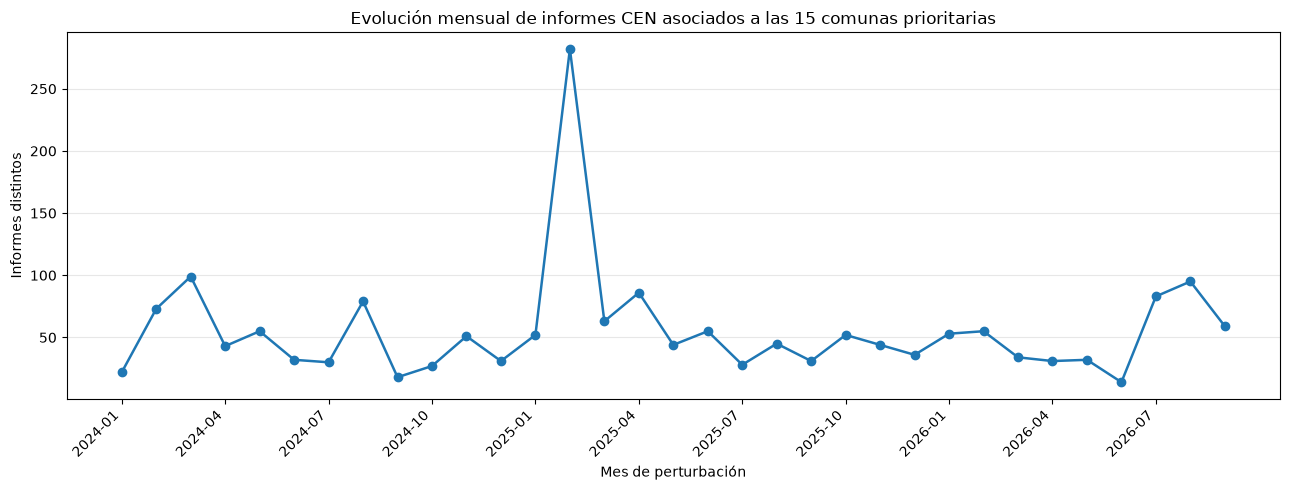

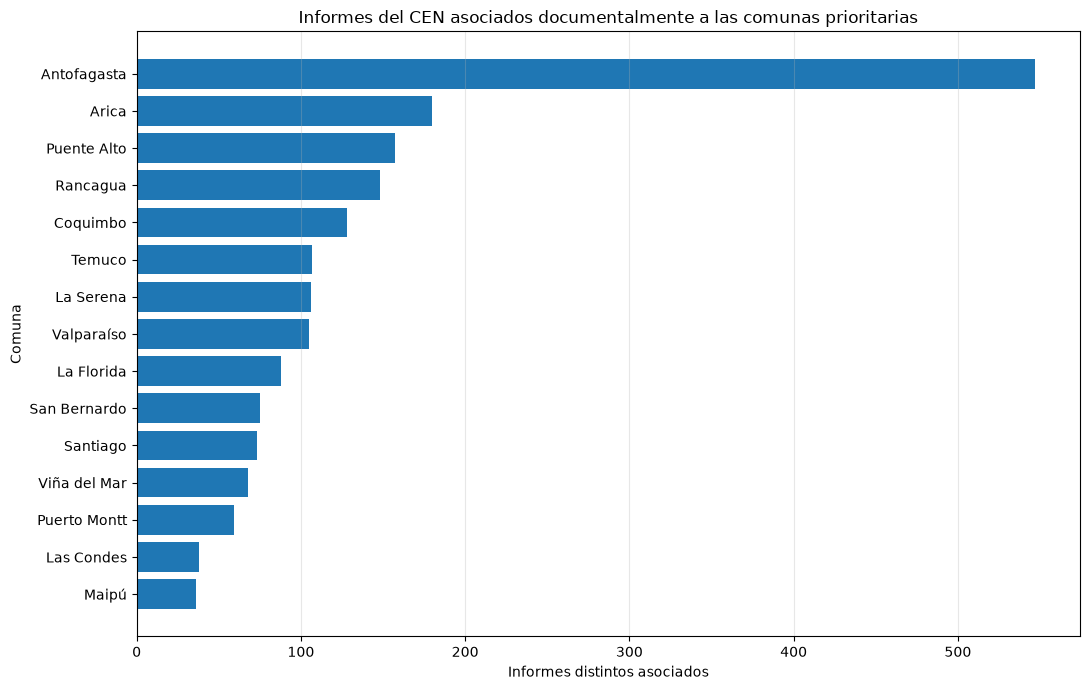

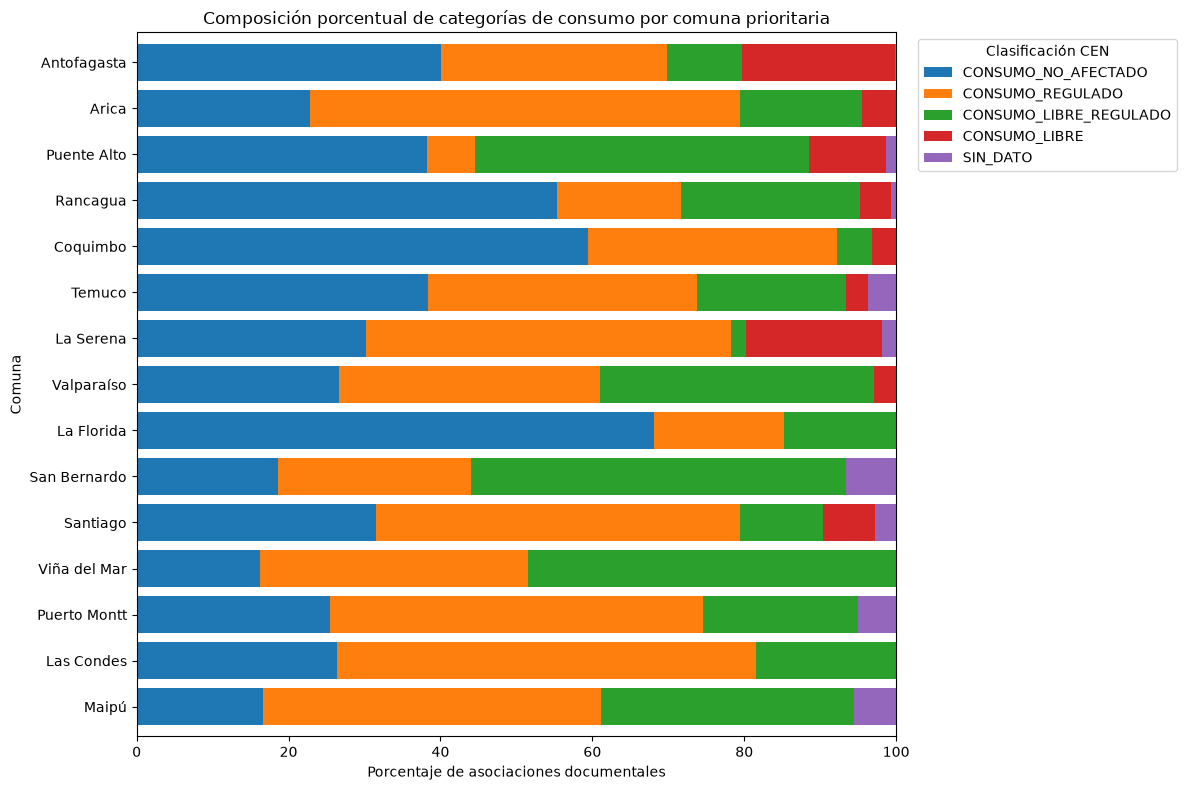

VISUALIZACIONES EXPLORATORIAS FINALIZADAS
[OK] Evolución mensual construida.
[OK] Distribución territorial construida.
[OK] Composición de consumo construida.
[OK] Integridad de los resultados verificada.


In [16]:
# ==========================================================
# FASE 2 - APARTADO 6.11
# VISUALIZACIONES EXPLORATORIAS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ==========================================================
# 1. VERIFICAR CONJUNTOS DISPONIBLES
# ==========================================================

assert len(df_temporal_prioritarias) == 1834, (
    "El conjunto de informes prioritarios "
    "no coincide con el resultado esperado."
)

assert len(df_prioritarias_cen) == 1915, (
    "El conjunto de asociaciones prioritarias "
    "no coincide con el resultado esperado."
)

assert len(df_resumen_prioritarias) == 15, (
    "El resumen no contiene las 15 comunas."
)


# ==========================================================
# 2. GRÁFICO 1: EVOLUCIÓN MENSUAL
# ==========================================================

evolucion_mensual = (
    df_temporal_prioritarias
    .groupby("mes_perturbacion")
    .agg(
        informes=("id_falla", "nunique")
    )
    .sort_index()
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    evolucion_mensual.index,
    evolucion_mensual["informes"],
    marker="o",
    linewidth=1.8
)

ax.set_title(
    "Evolución mensual de informes CEN asociados "
    "a las 15 comunas prioritarias"
)

ax.set_xlabel("Mes de perturbación")
ax.set_ylabel("Informes distintos")

ax.grid(axis="y", alpha=0.3)

# Mostrar una etiqueta cada tres meses.

posiciones = list(
    range(0, len(evolucion_mensual), 3)
)

ax.set_xticks(posiciones)

ax.set_xticklabels(
    evolucion_mensual.index[posiciones],
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. GRÁFICO 2: DISTRIBUCIÓN POR COMUNA
# ==========================================================

distribucion_comunal = (
    df_resumen_prioritarias[
        [
            "comuna_oficial",
            "informes_distintos"
        ]
    ]
    .sort_values("informes_distintos")
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    distribucion_comunal["comuna_oficial"],
    distribucion_comunal["informes_distintos"]
)

ax.set_title(
    "Informes del CEN asociados documentalmente "
    "a las comunas prioritarias"
)

ax.set_xlabel("Informes distintos asociados")
ax.set_ylabel("Comuna")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. PREPARAR CLASIFICACIÓN DE CONSUMO POR COMUNA
# ==========================================================

# Construir la estructura comuna-informe.
# Cada informe puede pertenecer a varias comunas.

df_consumo_comunal = (
    df_prioritarias_cen[
        [
            "id_falla",
            "codigo_comuna"
        ]
    ]
    .merge(
        df_operacional_prioritarias[
            [
                "id_falla",
                "consumo_analitico"
            ]
        ],
        on="id_falla",
        how="left",
        validate="many_to_one"
    )
    .merge(
        df_prioritarias[
            [
                "codigo_comuna",
                "comuna_oficial"
            ]
        ],
        on="codigo_comuna",
        how="left",
        validate="many_to_one"
    )
)

assert len(df_consumo_comunal) == 1915, (
    "La integración del consumo modificó "
    "las asociaciones originales."
)

assert df_consumo_comunal[
    "comuna_oficial"
].notna().all(), (
    "Existen asociaciones sin comuna oficial."
)


# ==========================================================
# 5. CALCULAR DISTRIBUCIÓN PORCENTUAL
# ==========================================================

tabla_consumo_comunal = pd.crosstab(
    df_consumo_comunal["comuna_oficial"],
    df_consumo_comunal["consumo_analitico"]
)

categorias_consumo = [
    "CONSUMO_NO_AFECTADO",
    "CONSUMO_REGULADO",
    "CONSUMO_LIBRE_REGULADO",
    "CONSUMO_LIBRE",
    "SIN_DATO"
]

tabla_consumo_comunal = (
    tabla_consumo_comunal
    .reindex(
        columns=categorias_consumo,
        fill_value=0
    )
)

porcentaje_consumo_comunal = (
    tabla_consumo_comunal
    .div(
        tabla_consumo_comunal.sum(axis=1),
        axis=0
    )
    * 100
)

# Ordenar las comunas por cantidad de informes.

orden_comunas = (
    distribucion_comunal["comuna_oficial"].tolist()
)

porcentaje_consumo_comunal = (
    porcentaje_consumo_comunal
    .reindex(orden_comunas)
)


# ==========================================================
# 6. GRÁFICO 3: CLASIFICACIÓN DE CONSUMO POR COMUNA
# ==========================================================

fig, ax = plt.subplots(figsize=(12, 8))

porcentaje_consumo_comunal.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.8
)

ax.set_title(
    "Composición porcentual de categorías "
    "de consumo por comuna prioritaria"
)

ax.set_xlabel("Porcentaje de asociaciones documentales")
ax.set_ylabel("Comuna")

ax.set_xlim(0, 100)

ax.legend(
    title="Clasificación CEN",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================================
# 7. VALIDACIÓN DE RESULTADOS
# ==========================================================

assert evolucion_mensual[
    "informes"
].sum() == 1834, (
    "La distribución temporal no coincide "
    "con el total de informes."
)

assert distribucion_comunal[
    "informes_distintos"
].sum() == 1915, (
    "La distribución comunal no coincide "
    "con las asociaciones territoriales."
)

assert tabla_consumo_comunal.to_numpy().sum() == 1915, (
    "La distribución de consumo presenta "
    "inconsistencias."
)


# ==========================================================
# 8. FINALIZAR
# ==========================================================

print("=" * 65)
print("VISUALIZACIONES EXPLORATORIAS FINALIZADAS")
print("=" * 65)

print("[OK] Evolución mensual construida.")

print("[OK] Distribución territorial construida.")

print("[OK] Composición de consumo construida.")

print("[OK] Integridad de los resultados verificada.")

### 6.11.4. Resultados e interpretación de las visualizaciones exploratorias

Las visualizaciones desarrolladas permitieron examinar la distribución temporal, territorial y operacional de los informes del Coordinador Eléctrico Nacional (CEN) asociados con las 15 comunas prioritarias seleccionadas mediante el Censo 2024.

El análisis consideró 1.834 informes distintos y 1.915 asociaciones territoriales, utilizando las variables previamente depuradas, normalizadas y validadas durante la Fase 2.

Las representaciones gráficas permiten identificar patrones relevantes para el estudio del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional (SEN).

**Figura 1. Evolución mensual de informes asociados a las comunas prioritarias**

La primera visualización representa la evolución mensual de los 1.834 informes distintos durante el período comprendido entre enero de 2024 y septiembre de 2026.

Los resultados evidencian una distribución temporal variable, con períodos de concentración y disminución en la cantidad de documentos registrados.

El principal hallazgo corresponde a febrero de 2025, cuando se identificaron **282 informes**, equivalentes al 15,38 % del conjunto prioritario.

Este comportamiento constituye una concentración documental excepcional respecto de los meses restantes y representa un período de interés para el análisis operacional posterior.

Sin embargo, la concentración no permite establecer por sí sola la causa de los registros. Para determinar su relación con acontecimientos específicos del SEN será necesario examinar las fechas, características técnicas y antecedentes documentales correspondientes.

También se observan concentraciones secundarias durante marzo de 2024, agosto de 2024, abril de 2025 y agosto de 2026.

La interpretación de las tendencias debe considerar que 2026 dispone de información solamente hasta septiembre, por lo que no corresponde comparar directamente su volumen acumulado con años completos.

**Figura 2. Distribución territorial de informes asociados con las 15 comunas prioritarias**

La segunda visualización permite comparar la cantidad de informes distintos vinculados documentalmente con cada comuna.

Los resultados muestran una distribución territorial heterogénea.

Antofagasta presenta la mayor cantidad de registros asociados, con 547 informes, seguida por Arica, con 180; Puente Alto, con 157; Rancagua, con 148; y Coquimbo, con 128.

En contraste, Maipú presenta 36 informes asociados y Las Condes registra 38.

Esta distribución evidencia que la cantidad de documentos vinculados con una comuna no mantiene necesariamente una relación proporcional con su población censada.

Por ejemplo, Puente Alto ocupa la primera posición demográfica entre las comunas seleccionadas, mientras que Antofagasta concentra el mayor número de informes asociados.

No obstante, estas diferencias no constituyen una medición directa de confiabilidad del suministro eléctrico ni permiten establecer que una comuna haya experimentado mayor cantidad de interrupciones efectivas.

Los registros pueden presentar características distintas respecto de su alcance territorial, infraestructura involucrada y condiciones administrativas.

La distribución se construyó a partir de las 1.915 asociaciones territoriales. Por ello, aunque cada comuna presenta un conteo de informes distintos, la suma de los valores comunales supera los 1.834 informes únicos del conjunto prioritario, debido a que un mismo documento puede encontrarse asociado con varias comunas.

**Figura 3. Composición porcentual de categorías de consumo por comuna prioritaria**

La tercera visualización representa la participación relativa de las categorías de consumo registradas en los informes asociados con cada comuna.

Los resultados evidencian diferencias en la composición documental de los territorios seleccionados.

En comunas como La Florida, Coquimbo y Rancagua se observa una participación importante de la categoría `CONSUMO_NO_AFECTADO`.

Por otra parte, Arica, Las Condes, Maipú y La Serena presentan una participación relevante de la categoría `CONSUMO_REGULADO`.

También se identifican comunas donde la categoría `CONSUMO_LIBRE_REGULADO` representa una proporción significativa de las asociaciones, entre ellas Puente Alto, San Bernardo y Viña del Mar.

Estas diferencias permiten reconocer perfiles documentales distintos entre los territorios y constituyen antecedentes para profundizar la caracterización operacional de los informes.

Sin embargo, las categorías de consumo pertenecen a los registros del CEN y no representan una medición directa de clientes afectados en cada comuna.

Asimismo, los porcentajes corresponden a la composición interna de las asociaciones de cada territorio. Por esta razón, deben interpretarse considerando las diferencias en el número de registros disponibles.

**Interpretación integrada de los resultados**

Las tres visualizaciones permiten reconocer características complementarias de los informes asociados a las comunas prioritarias:

| Dimensión | Principal resultado | Contribución al proyecto |
|---|---|---|
| Temporal | Concentración de 282 informes durante febrero de 2025. | Identificar períodos que requieren revisión operacional. |
| Territorial | Antofagasta concentra 547 informes asociados. | Reconocer diferencias en la presencia documental entre comunas. |
| Operacional | Se observan diferencias en la composición de categorías de consumo. | Caracterizar los antecedentes operacionales registrados en cada territorio. |

Los resultados permiten avanzar desde la exploración individual de variables hacia una caracterización integrada de los informes del SEN.

Desde la perspectiva del objetivo del proyecto, el procesamiento ha permitido identificar **dónde, cuándo y bajo qué clasificaciones operacionales se documentan los informes asociados a las comunas prioritarias**.

No obstante, se mantiene una distinción metodológica fundamental: los registros analizados representan asociaciones documentales de fallas y no mediciones directas de interrupciones efectivas, clientes afectados, energía no suministrada o duración real de los cortes eléctricos comunales.

Por lo tanto, las visualizaciones constituyen evidencia descriptiva para orientar el análisis del impacto operacional documentado, sin establecer relaciones causales ni indicadores de continuidad que no puedan sustentarse mediante las fuentes disponibles.

**Validación de las visualizaciones**

El código incorpora comprobaciones orientadas a verificar la consistencia entre los datos representados y los conjuntos procesados.

Los controles consideran:

1. La correspondencia entre la distribución mensual y los 1.834 informes únicos.
2. La consistencia entre la distribución territorial y las 1.915 asociaciones comunales.
3. La conservación de las asociaciones al incorporar las categorías de consumo.
4. La correspondencia entre las frecuencias de consumo comunal y el total de asociaciones disponibles.

Estas verificaciones permiten mantener trazabilidad entre los datos preparados y las representaciones gráficas.

Con estos resultados se completa la exploración visual inicial de las dimensiones temporal, territorial y operacional del proyecto.